# Acil Servislerde Bekleme Süreleri ve Hasta Ayrılma Analizi

## 1. Projenin Amacı
Bu projenin amacı, acil servislerde hasta bekleme sürelerini
incelemek ve muayene olmadan ayrılan hastalarla ilişkili
faktörleri araştırmaktır.

## 2. Araştırma Soruları
1. Hastaların ortalama bekleme süresi ne kadardır?
2. Bekleme süreleri hastanelere göre değişiyor mu?
3. Aciliyet düzeyi bekleme süreleriyle ilişkili midir?
4. Hangi zaman dilimlerinde bekleme süreleri artmaktadır?
5. Muayene olmadan ayrılma oranı nedir?
6. Bekleme süresi ile muayene olmadan ayrılma arasında
   ilişki var mıdır?

## 3. Veri Seti

- **Kullanılan dosya:** ER Wait Time Dataset.csv
- **Veri kaynağı:** [Kaggle — ER Wait Time](https://www.kaggle.com/datasets/rivalytics/er-wait-time)
- **Kayıt sayısı:** 5.000 simüle edilmiş hasta ziyareti
- **Değişken sayısı:** 19
- **Veri dönemi:** 2024 yılı

## 4. Kullanılacak Araçlar
- Python
- Google Colab
- Pandas
- Matplotlib
- GitHub

## 5. Analiz Yaklaşımı
Bulgu → Yorum → Risk → Öneri

## 6. Beklenen Çıktılar
- Veri kalitesi incelemesi
- İstatistiksel özetler
- Karşılaştırmalı analizler
- Grafikler
- Yönetim için değerlendirme ve öneriler

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

##############################################################################
#    HÜCRE 3 — CSV Dosyasının Yolunu Kontrol Etmefrom pathlib import Path
##############################################################################

# Proje klasörümüz
klasor = Path("/content/drive/MyDrive/PROJELERİM/Sağlık/Acil Servis")

# Klasörü ve CSV dosyalarını kontrol et
if klasor.is_dir():
    print("✅ Proje klasörü bulundu.")

    csv_dosyalari = list(klasor.glob("*.csv"))

    if csv_dosyalari:
        for dosya in csv_dosyalari:
            print("✅ CSV dosyası:", dosya.name)
    else:
        print("⚠️ Klasörde CSV dosyası bulunamadı.")
else:
    print("⚠️ Klasör yolu bulunamadı.")

✅ Proje klasörü bulundu.
✅ CSV dosyası: ER Wait Time Dataset.csv


In [ ]:
##############################################################################
#   HÜCRE 4 — Veri Setini Pandas ile Okuma
##############################################################################


import pandas as pd

# Veri dosyasını belirle
dosya = klasor / "ER Wait Time Dataset.csv"

# CSV dosyasını oku
df = pd.read_csv(dosya)

# Veri setinin boyutunu göster
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])

# İlk 5 satırı görüntüle
display(df.head())

Satır sayısı: 5000
Sütun sayısı: 19


,Visit ID,Patient ID,Hospital ID,Hospital Name,Region,Visit Date,Day of Week,Season,Time of Day,Urgency Level,Nurse-to-Patient Ratio,Specialist Availability,Facility Size (Beds),Time to Registration (min),Time to Triage (min),Time to Medical Professional (min),Total Wait Time (min),Patient Outcome,Patient Satisfaction
0,HOSP-1-20240210-0001,PAT-00001,HOSP-1,Springfield General Hospital,Urban,2024-02-10 20:20:56,Saturday,Winter,Late Morning,Medium,4,3,92,17,22,66,105,Discharged,1
1,HOSP-3-20241128-0001,PAT-00002,HOSP-3,Northside Community Hospital,Rural,2024-11-28 02:07:47,Thursday,Fall,Evening,Medium,4,0,38,9,30,30,69,Discharged,3
2,HOSP-3-20240930-0002,PAT-00003,HOSP-3,Northside Community Hospital,Rural,2024-09-30 04:02:28,Monday,Fall,Evening,Low,5,1,38,38,40,125,203,Discharged,1
3,HOSP-2-20240227-0001,PAT-00004,HOSP-2,Riverside Medical Center,Urban,2024-02-27 00:31:13,Tuesday,Winter,Evening,High,4,5,94,8,16,64,88,Discharged,2
4,HOSP-1-20240306-0002,PAT-00005,HOSP-1,Springfield General Hospital,Urban,2024-03-06 16:52:26,Wednesday,Spring,Afternoon,Low,4,8,74,26,29,63,118,Discharged,1


In [ ]:
# ============================================================
# HÜCRE 5 — SÜTUN İSİMLERİNİ TÜRKÇELEŞTİRME
# ============================================================

# İngilizce sütun adları ve Türkçe karşılıkları
sutun_cevirileri = {
    "Visit ID": "Ziyaret Numarası",
    "Patient ID": "Hasta Numarası",
    "Hospital ID": "Hastane Kodu",
    "Hospital Name": "Hastane Adı",
    "Region": "Bölge",
    "Visit Date": "Ziyaret Tarihi",
    "Day of Week": "Haftanın Günü",
    "Season": "Mevsim",
    "Time of Day": "Günün Zaman Dilimi",
    "Urgency Level": "Aciliyet Düzeyi",
    "Nurse-to-Patient Ratio": "Hemşire Hasta Oranı",
    "Specialist Availability": "Uzman Hekim Mevcudiyeti",
    "Facility Size (Beds)": "Hastane Yatak Kapasitesi",
    "Time to Registration (min)": "Kayıt Süresi (dk)",
    "Time to Triage (min)": "Triyaj Süresi (dk)",
    "Time to Medical Professional (min)": "Hekime Ulaşma Süresi (dk)",
    "Total Wait Time (min)": "Toplam Bekleme Süresi (dk)",
    "Patient Outcome": "Hasta Sonucu",
    "Patient Satisfaction": "Hasta Memnuniyeti"
}

# Orijinal veri setini koruyarak Türkçe tablo oluştur
df_tr = df.rename(columns=sutun_cevirileri).copy()

# Kontrol
print("Orijinal sütun sayısı:", len(df.columns))
print("Türkçe sütun sayısı:", len(df_tr.columns))

# İlk 5 satırı göster
display(df_tr.head())

Orijinal sütun sayısı: 19
Türkçe sütun sayısı: 19


,Ziyaret Numarası,Hasta Numarası,Hastane Kodu,Hastane Adı,Bölge,Ziyaret Tarihi,Haftanın Günü,Mevsim,Günün Zaman Dilimi,Aciliyet Düzeyi,Hemşire Hasta Oranı,Uzman Hekim Mevcudiyeti,Hastane Yatak Kapasitesi,Kayıt Süresi (dk),Triyaj Süresi (dk),Hekime Ulaşma Süresi (dk),Toplam Bekleme Süresi (dk),Hasta Sonucu,Hasta Memnuniyeti
0,HOSP-1-20240210-0001,PAT-00001,HOSP-1,Springfield General Hospital,Urban,2024-02-10 20:20:56,Saturday,Winter,Late Morning,Medium,4,3,92,17,22,66,105,Discharged,1
1,HOSP-3-20241128-0001,PAT-00002,HOSP-3,Northside Community Hospital,Rural,2024-11-28 02:07:47,Thursday,Fall,Evening,Medium,4,0,38,9,30,30,69,Discharged,3
2,HOSP-3-20240930-0002,PAT-00003,HOSP-3,Northside Community Hospital,Rural,2024-09-30 04:02:28,Monday,Fall,Evening,Low,5,1,38,38,40,125,203,Discharged,1
3,HOSP-2-20240227-0001,PAT-00004,HOSP-2,Riverside Medical Center,Urban,2024-02-27 00:31:13,Tuesday,Winter,Evening,High,4,5,94,8,16,64,88,Discharged,2
4,HOSP-1-20240306-0002,PAT-00005,HOSP-1,Springfield General Hospital,Urban,2024-03-06 16:52:26,Wednesday,Spring,Afternoon,Low,4,8,74,26,29,63,118,Discharged,1


In [ ]:
# ============================================================
# HÜCRE 6 — KATEGORİK DEĞİŞKENLERİN DAĞILIMI
# ============================================================

# İncelenecek kategorik sütunlar
kategorik_sutunlar = [
    "Hastane Adı",
    "Bölge",
    "Haftanın Günü",
    "Mevsim",
    "Günün Zaman Dilimi",
    "Aciliyet Düzeyi",
    "Hasta Sonucu"
]

# Her sütunu ayrı ayrı incele
for sutun in kategorik_sutunlar:

    print(f"\n{'=' * 50}")
    print(f"DEĞİŞKEN: {sutun}")
    print(f"{'=' * 50}")

    tablo = df_tr[sutun].value_counts(
        dropna=False
    ).reset_index()

    tablo.columns = [sutun, "Hasta Sayısı"]

    tablo["Oran (%)"] = (
        tablo["Hasta Sayısı"] / len(df_tr) * 100
    ).round(2)

    display(tablo)


DEĞİŞKEN: Hastane Adı


,Hastane Adı,Hasta Sayısı,Oran (%)
0,Riverside Medical Center,1023,20.46
1,Northside Community Hospital,999,19.98
2,St. Mary’s Regional Health,995,19.90
3,Springfield General Hospital,994,19.88
4,Summit Health Center,989,19.78



DEĞİŞKEN: Bölge


,Bölge,Hasta Sayısı,Oran (%)
0,Urban,3006,60.12
1,Rural,1994,39.88



DEĞİŞKEN: Haftanın Günü


,Haftanın Günü,Hasta Sayısı,Oran (%)
0,Monday,768,15.36
1,Tuesday,741,14.82
2,Sunday,725,14.50
3,Thursday,706,14.12
4,Saturday,701,14.02
5,Friday,685,13.70
6,Wednesday,674,13.48


... (4 outputs left out)


DEĞİŞKEN: Aciliyet Düzeyi


,Aciliyet Düzeyi,Hasta Sayısı,Oran (%)
0,Medium,1291,25.82
1,High,1245,24.90
2,Critical,1242,24.84
3,Low,1222,24.44



DEĞİŞKEN: Hasta Sonucu


,Hasta Sonucu,Hasta Sayısı,Oran (%)
0,Discharged,2879,57.58
1,Admitted,1868,37.36
2,Left Without Being Seen,253,5.06


In [ ]:
# ============================================================
# HÜCRE 7 — HASTANE VE BÖLGE ÇAPRAZ TABLOSU
# ============================================================

# Hastanelerin bölgelere göre kayıt sayılarını göster
tablo = pd.crosstab(
    df_tr["Hastane Adı"],
    df_tr["Bölge"],
    margins=True,
    margins_name="Toplam"
)

display(tablo)

Bölge,Rural,Urban,Toplam
Hastane Adı,,,
Northside Community Hospital,999,0,999
Riverside Medical Center,0,1023,1023
Springfield General Hospital,0,994,994
St. Mary’s Regional Health,995,0,995
Summit Health Center,0,989,989
Toplam,1994,3006,5000


## HÜCRE 7 — Hastane ve Bölge Dağılımı: Analist Notları

### 1. Bulgu
Veri setinde toplam 5 hastane ve 5.000 hasta kaydı bulunmaktadır.

- Kentsel (Urban): 3 hastane, 3.006 kayıt (%60,12)
- Kırsal (Rural): 2 hastane, 1.994 kayıt (%39,88)

Her hastane veri setinde yalnızca bir bölge kategorisinde görünmektedir.

### 2. Yorum
Kentsel kategorideki hasta kayıtlarının sayısı daha fazladır.

Ancak bu dağılım, kentsel bölgelerde sağlık hizmetlerine
duyulan ihtiyacın daha fazla olduğunu tek başına göstermez.

### 3. Risk ve Veri Sınırlılıkları
"Region" değişkeninin neyi temsil ettiği henüz doğrulanmamıştır.

- Hastanenin bulunduğu bölgeyi mi göstermektedir?
- Hastanın ikamet ettiği bölgeyi mi göstermektedir?
- Hastanelerin farklı bölgelerde şubeleri var mıdır?
- Hastalar farklı bölgelerdeki hastaneleri tercih ediyor olabilir mi?

Bu soruların cevapları mevcut bilgilerle kesinleştirilememektedir.

Bölge değişkeninin anlamı netleştirilmeden hastane
performansı ve hasta tercihleri hakkında kesin yorum
yapılması hatalı yönetim kararlarına neden olabilir.

### 4. Öneri
- Veri setinin açıklaması incelenerek Region değişkeni doğrulanmalıdır.
- Hastanelerin konumları ve varsa şube bilgileri araştırılmalıdır.
- Hastaların ikamet bölgeleri mevcutsa karşılaştırmaya eklenmelidir.
- Hastane karşılaştırmalarında kapasite, personel ve hasta
  başvuru sayıları gibi değişkenler de değerlendirilmelidir.

### 5. Analistin Öğrenme Notu
Verinin gösterdiği bilgi ile varsayımlar birbirinden ayrılmalıdır.

Bir değişkenin neyi ifade ettiği bilinmeden o değişkene
dayanarak kesin sonuç çıkarılmamalıdır.

**Temel ilke:** Önce veriyi tanı, sonra karşılaştır,
ardından yorumla ve öneri geliştir.

2024 YILI — SAATLİK TOPLAM HASTA KAYITLARI


,Pazartesi,Çarşamba
Saat,,
0,27,39
1,40,29
2,29,34
3,24,11
4,26,23
5,36,33
6,26,27
7,34,32
8,32,28


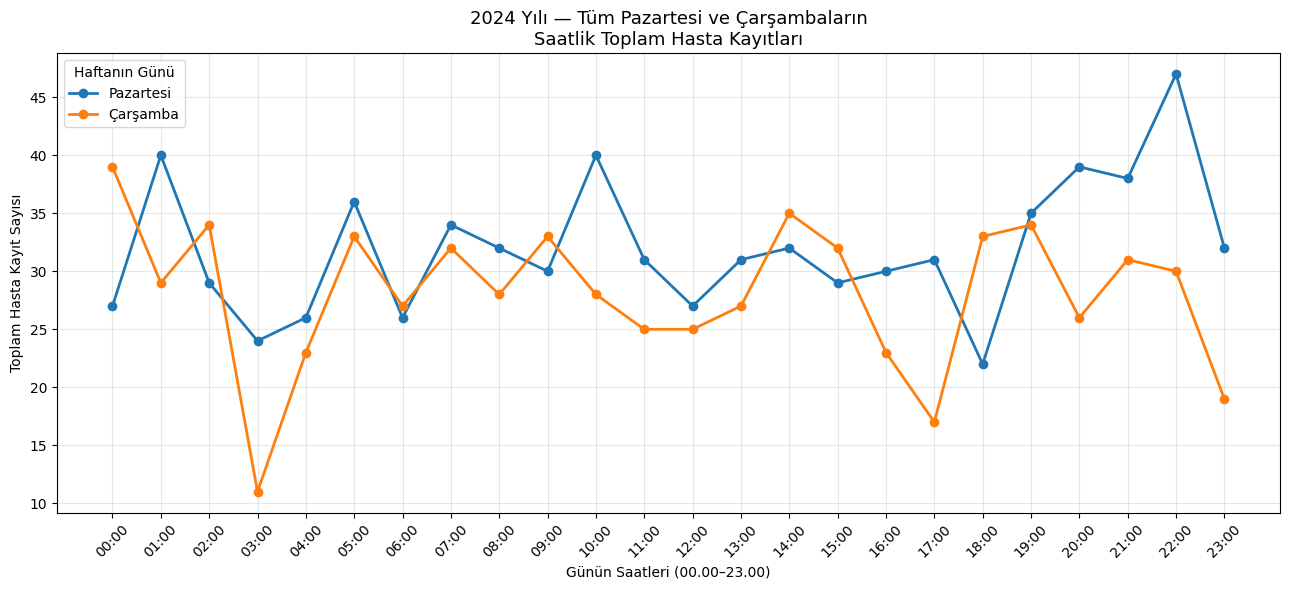

NOT: Her nokta, 2024 yılı veri setindeki ilgili hafta gününün belirtilen saat aralığındaki tüm kayıtlarının toplamıdır.


In [ ]:
# ============================================================
# HÜCRE 8 — PAZARTESİ VE ÇARŞAMBA SAATLİK TOPLAM KAYITLARI
# ============================================================

import matplotlib.pyplot as plt

# Orijinal veriyi koru
df_saat = df_tr.copy()

# Tarih ve saat bilgilerini hazırla
df_saat["Ziyaret Tarihi"] = pd.to_datetime(
    df_saat["Ziyaret Tarihi"]
)

df_saat["Saat"] = df_saat["Ziyaret Tarihi"].dt.hour

# Veri setindeki tüm pazartesi ve çarşambaları grupla
saat_tablosu = pd.crosstab(
    df_saat["Saat"],
    df_saat["Haftanın Günü"]
)

saat_tablosu = saat_tablosu.reindex(
    index=range(24),
    columns=["Monday", "Wednesday"],
    fill_value=0
)

saat_tablosu.columns = ["Pazartesi", "Çarşamba"]
saat_tablosu.index.name = "Saat"

# Sayısal tablo
print("2024 YILI — SAATLİK TOPLAM HASTA KAYITLARI")
display(saat_tablosu)

# Grafik
ax = saat_tablosu.plot(
    kind="line",
    marker="o",
    figsize=(13, 6),
    linewidth=2
)

ax.set_title(
    "2024 Yılı — Tüm Pazartesi ve Çarşambaların\n"
    "Saatlik Toplam Hasta Kayıtları",
    fontsize=13
)

ax.set_xlabel("Günün Saatleri (00.00–23.00)")
ax.set_ylabel("Toplam Hasta Kayıt Sayısı")

ax.set_xticks(range(24))
ax.set_xticklabels([f"{s:02d}:00" for s in range(24)],
                   rotation=45)

ax.legend(title="Haftanın Günü")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "NOT: Her nokta, 2024 yılı veri setindeki ilgili "
    "hafta gününün belirtilen saat aralığındaki "
    "tüm kayıtlarının toplamıdır."
)

## HÜCRE 8 — Saatlik Hasta Kayıtları: Analiz ve Değerlendirme

### 1. Analizin Amacı

2024 yılı veri setindeki pazartesi ve çarşamba günlerinin
saatlik hasta kayıt dağılımlarını karşılaştırmak.

Amaç, belirli saatlerde hasta kayıtlarının nasıl değiştiğini
ve iki gün arasında benzer eğilimler bulunup bulunmadığını
incelemektir.

### 2. Grafiğin Tanımı

**Grafik:** 2024 yılı boyunca tüm pazartesi ve çarşamba
günlerinin saatlik toplam hasta kayıtları.

- Yatay eksen: Günün saatleri (00.00–23.00)
- Dikey eksen: Toplam hasta kayıt sayısı
- Pazartesi: 768 kayıt
- Çarşamba: 674 kayıt

**Önemli:** Grafik tek bir haftayı göstermemektedir.

Veri setindeki bütün pazartesi ve çarşamba günlerinin
aynı saat aralıklarındaki kayıtları toplanmıştır.

Örneğin saat 00.00–00.59 arasında:
- Pazartesi toplamı: 27 kayıt
- Çarşamba toplamı: 39 kayıt

Bu sayılar tek bir günün değil, incelenen dönemdeki
ilgili günlerin toplam kayıtlarıdır.

### 3. BULGU — Veriler Ne Gösteriyor?

- Pazartesi günlerinin toplam kayıt sayısı çarşambadan fazladır.
- Saatlik kayıt sayıları gün içerisinde değişmektedir.
- İki günün kayıt sayıları bazı saat aralıklarında
  birlikte artış veya azalış göstermektedir.
- Bazı saatlerde ise farklı yönlerde değişimler görülmektedir.

### 4. YORUM — Verilerden Ne Anlıyoruz?

Pazartesi ve çarşamba günlerinin saatlik hasta kayıtları,
belirli zaman aralıklarında benzer eğilimler göstermektedir.

Ancak bu benzerlik, iki günün kayıt sayılarının
aynı olduğu veya doğru orantılı değiştiği anlamına gelmez.

Grafikteki benzer hareketler, saatlik kayıt dağılımlarının
karşılaştırılması açısından değerlendirilmelidir.

### 5. RİSK — Nerede Yanılabiliriz?

- Grafik farklı haftaların kayıtlarını birleştirmektedir.
- Haftalar arasındaki değişimleri ayrı ayrı göstermemektedir.
- Kayıt sayısındaki artış, bekleme süresinin de
  mutlaka arttığını göstermez.
- Benzer eğilimler neden-sonuç ilişkisini kanıtlamaz.
- Veri setinin gerçek veya sentetik niteliği doğrulanmalıdır.
- Tarih-saat bilgisinin hangi işlemi temsil ettiği
  kesinleştirilmelidir.

### 6. ÖNERİ — Sonraki Analizde Ne Yapmalıyız?

- Haftalara göre saatlik kayıt dağılımlarını incelemek.
- Saatlik kayıt sayılarını bekleme süreleriyle karşılaştırmak.
- Aciliyet düzeylerini değerlendirmeye eklemek.
- Muayene olmadan ayrılan hastaların saatlik dağılımını incelemek.
- Personel ve hizmet kapasitesiyle ilgili verileri değerlendirmek.

### 7. ANALİSTİN ÖĞRENME NOTU

Bir grafiği yorumlamadan önce şu sorular cevaplanmalıdır:

1. Grafik neyi ölçüyor?
2. Hangi dönemi kapsıyor?
3. Değerler toplam mı, ortalama mı, oran mı?
4. Hangi gruplar karşılaştırılıyor?
5. Grafik hangi soruları cevaplıyor?
6. Hangi soruları cevaplayamıyor?

**Temel ilke:**

Önce grafiği doğru tanımla.
Sonra bulguyu belirle.
Ardından yorumunu yap.
Yanılma riskini değerlendir.
Son olarak önerini oluştur.

### 8. Yönetim İçin Genel Değerlendirme

2024 yılı veri setindeki pazartesi ve çarşamba günlerinin
saatlik toplam hasta kayıtları incelendiğinde,
belirli saat aralıklarında benzer artış ve azalış
eğilimleri görülmektedir.

Ancak yalnızca hasta kayıt sayılarından hareketle
hastanelerin hizmet yoğunluğu ve performansı hakkında
kesin bir değerlendirme yapılamaz.

Daha kapsamlı sonuçlara ulaşmak için saatlik kayıt
sayılarının bekleme süreleri, aciliyet düzeyleri ve
hasta sonuçlarıyla birlikte incelenmesi önerilmektedir.

In [ ]:

# ============================================================
# HÜCRE 9 — ACİLİYET DÜZEYLERİNE GÖRE HASTA KAYITLARI
# ============================================================

import pandas as pd

sutun = "Aciliyet Düzeyi"
duzeyler = ["Low", "Medium", "High", "Critical"]

# Beklenmeyen değerleri kontrol et
beklenmeyen = df_tr.loc[
    df_tr[sutun].notna() & ~df_tr[sutun].isin(duzeyler),
    sutun
].unique()

if len(beklenmeyen) > 0:
    print("⚠️ Beklenmeyen değerler:", beklenmeyen)

else:
    tablo = (
        df_tr[sutun]
        .value_counts()
        .reindex(duzeyler, fill_value=0)
        .rename_axis("Aciliyet Düzeyi")
        .reset_index(name="Hasta Kayıt Sayısı")
    )

    tablo["Yüzde (%)"] = (
        tablo["Hasta Kayıt Sayısı"] / len(df_tr) * 100
    ).round(2)

    display(tablo)

    print("Toplam hasta kaydı:", len(df_tr))
    print("Eksik aciliyet kaydı:", df_tr[sutun].isna().sum())


,Aciliyet Düzeyi,Hasta Kayıt Sayısı,Yüzde (%)
0,Low,1222,24.44
1,Medium,1291,25.82
2,High,1245,24.90
3,Critical,1242,24.84


Toplam hasta kaydı: 5000
Eksik aciliyet kaydı: 0


HÜCRE 10 — HASTA KAYIT SÜRESİ ANALİZİ


,İstatistik,Değer
0,Toplam Kayıt,5000.00
1,Geçerli Kayıt,5000.00
2,Eksik / Geçersiz Kayıt,0.00
3,Ortalama (dk),11.70
4,Medyan (dk),8.00
5,Minimum (dk),0.00
6,Maksimum (dk),66.00
7,Standart Sapma (dk),10.44


Negatif süre sayısı: 0
Sıfır süre sayısı: 111


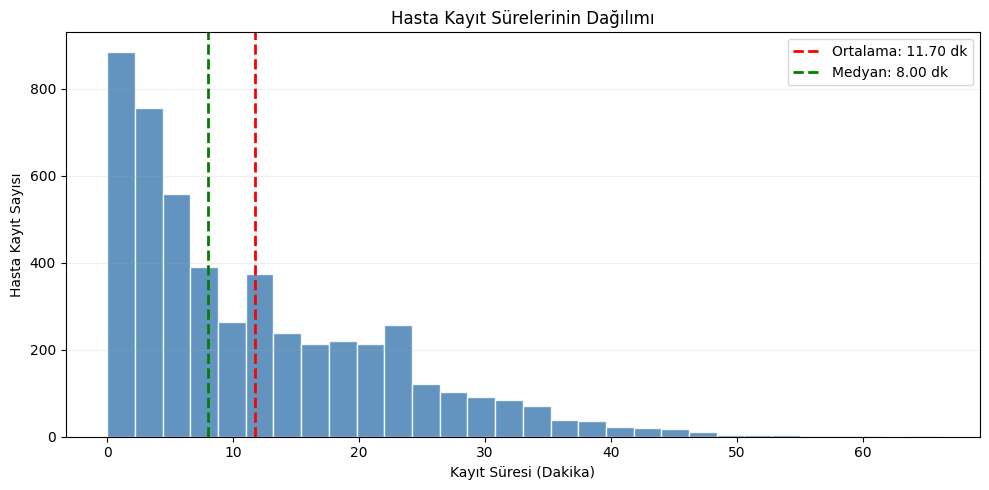

In [ ]:

# ============================================================
# HÜCRE 10 — HASTA KAYIT SÜRESİNİN İSTATİSTİKSEL ANALİZİ
# ============================================================

import pandas as pd

sutun = "Kayıt Süresi (dk)"

# Sayısal verilere dönüştür (orijinal tabloyu değiştirme)
sure = pd.to_numeric(df_tr[sutun], errors="coerce")

# İstatistiksel özet
ozet = pd.DataFrame({
    "İstatistik": [
        "Toplam Kayıt",
        "Geçerli Kayıt",
        "Eksik / Geçersiz Kayıt",
        "Ortalama (dk)",
        "Medyan (dk)",
        "Minimum (dk)",
        "Maksimum (dk)",
        "Standart Sapma (dk)"
    ],
    "Değer": [
        len(sure),
        sure.count(),
        sure.isna().sum(),
        round(sure.mean(), 2),
        round(sure.median(), 2),
        sure.min(),
        sure.max(),
        round(sure.std(), 2)
    ]
})

print("HÜCRE 10 — HASTA KAYIT SÜRESİ ANALİZİ")
display(ozet)

print("Negatif süre sayısı:", (sure < 0).sum())
print("Sıfır süre sayısı:", (sure == 0).sum())

# ============================================================
# HÜCRE 10 — HASTA KAYIT SÜRESİ DAĞILIM GRAFİĞİ
# ============================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    sure.dropna(),
    bins=30,
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    sure.mean(), color="red", linestyle="--",
    linewidth=2, label=f"Ortalama: {sure.mean():.2f} dk"
)

plt.axvline(
    sure.median(), color="green", linestyle="--",
    linewidth=2, label=f"Medyan: {sure.median():.2f} dk"
)

plt.title("Hasta Kayıt Sürelerinin Dağılımı")
plt.xlabel("Kayıt Süresi (Dakika)")
plt.ylabel("Hasta Kayıt Sayısı")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


ACİLİYET DÜZEYLERİNE GÖRE KAYIT SÜRELERİ


,Hasta_Sayısı,Ortalama,Medyan,Minimum,Maksimum,Standart_Sapma,Sıfır_Süre_Sayısı
Düşük,1222,24.33,23.0,8,66,9.28,0
Orta,1291,14.84,14.0,3,51,6.93,0
Yüksek,1245,5.65,5.0,1,15,2.37,0
Kritik,1242,2.09,2.0,0,8,1.41,111


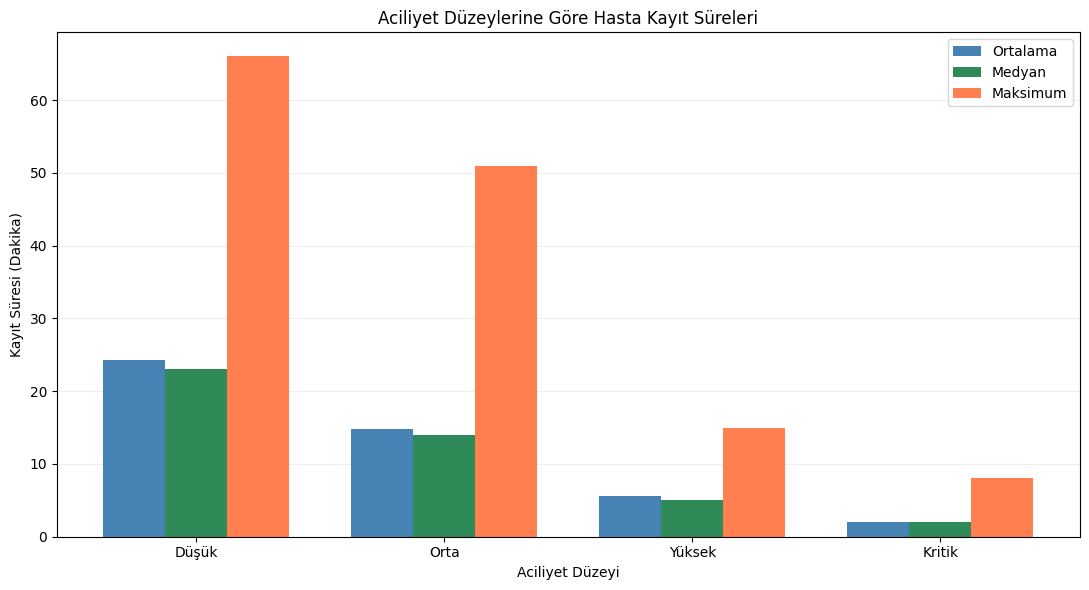

In [ ]:

# ============================================================
# HÜCRE 11 — ACİLİYET DÜZEYİNE GÖRE KAYIT SÜRELERİ
# ============================================================

import pandas as pd

duzeyler = ["Low", "Medium", "High", "Critical"]

veri = df_tr[["Aciliyet Düzeyi", "Kayıt Süresi (dk)"]].copy()
veri["Kayıt Süresi (dk)"] = pd.to_numeric(
    veri["Kayıt Süresi (dk)"], errors="coerce"
)

tablo = (
    veri.groupby("Aciliyet Düzeyi")["Kayıt Süresi (dk)"]
    .agg(
        Hasta_Sayısı="size",
        Ortalama="mean",
        Medyan="median",
        Minimum="min",
        Maksimum="max",
        Standart_Sapma="std",
        Sıfır_Süre_Sayısı=lambda x: (x == 0).sum()
    )
    .reindex(duzeyler)
    .round(2)
)

tablo.index = ["Düşük", "Orta", "Yüksek", "Kritik"]

print("ACİLİYET DÜZEYLERİNE GÖRE KAYIT SÜRELERİ")
display(tablo)

# ============================================================
# HÜCRE 11 — ACİLİYET DÜZEYİNE GÖRE KAYIT SÜRESİ GRAFİĞİ
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(tablo))
genislik = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(x - genislik, tablo["Ortalama"],
       genislik, label="Ortalama", color="steelblue")

ax.bar(x, tablo["Medyan"],
       genislik, label="Medyan", color="seagreen")

ax.bar(x + genislik, tablo["Maksimum"],
       genislik, label="Maksimum", color="coral")

ax.set_xticks(x)
ax.set_xticklabels(tablo.index)
ax.set_xlabel("Aciliyet Düzeyi")
ax.set_ylabel("Kayıt Süresi (Dakika)")
ax.set_title("Aciliyet Düzeylerine Göre Hasta Kayıt Süreleri")

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


HÜCRE 12 — TRİYAJ SÜRESİ ANALİZİ


,Hasta_Sayısı,Ortalama,Medyan,Minimum,Maksimum,Standart_Sapma,Sıfır_Süre_Sayısı,Eksik_Süre_Sayısı
Düşük,1222,58.70,54.0,17,163,24.10,0,0
Orta,1291,26.18,24.0,6,82,10.87,0,0
Yüksek,1245,11.00,10.0,3,32,4.60,0,0
Kritik,1242,3.96,4.0,1,13,2.10,0,0


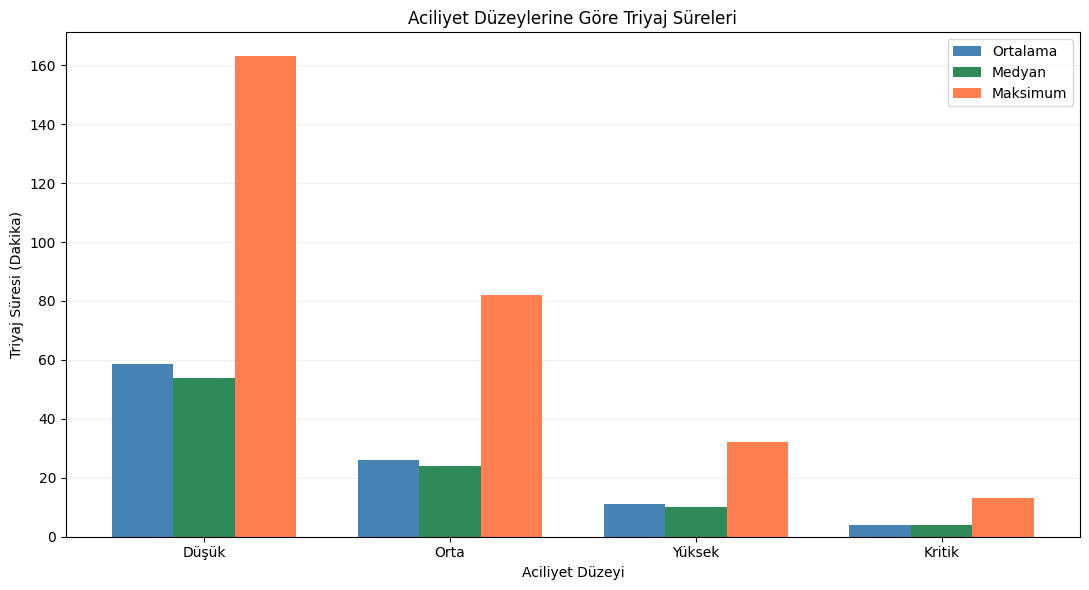

In [ ]:

# ============================================================
# HÜCRE 12 — ACİLİYET DÜZEYİNE GÖRE TRİYAJ SÜRESİ
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sutun = "Triyaj Süresi (dk)"
duzeyler = ["Low", "Medium", "High", "Critical"]
etiketler = ["Düşük", "Orta", "Yüksek", "Kritik"]

veri = df_tr[["Aciliyet Düzeyi", sutun]].copy()
veri[sutun] = pd.to_numeric(veri[sutun], errors="coerce")

tablo_12 = (
    veri.groupby("Aciliyet Düzeyi")[sutun]
    .agg(
        Hasta_Sayısı="size",
        Ortalama="mean",
        Medyan="median",
        Minimum="min",
        Maksimum="max",
        Standart_Sapma="std",
        Sıfır_Süre_Sayısı=lambda x: (x == 0).sum(),
        Eksik_Süre_Sayısı=lambda x: x.isna().sum()
    )
    .reindex(duzeyler)
    .round(2)
)

tablo_12.index = etiketler

print("HÜCRE 12 — TRİYAJ SÜRESİ ANALİZİ")
display(tablo_12)

# Karşılaştırma grafiği
x = np.arange(len(etiketler))
genislik = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for konum, kolon, renk in [
    (-genislik, "Ortalama", "steelblue"),
    (0, "Medyan", "seagreen"),
    (genislik, "Maksimum", "coral")
]:
    ax.bar(
        x + konum,
        tablo_12[kolon],
        genislik,
        label=kolon,
        color=renk
    )

ax.set_xticks(x)
ax.set_xticklabels(etiketler)
ax.set_xlabel("Aciliyet Düzeyi")
ax.set_ylabel("Triyaj Süresi (Dakika)")
ax.set_title("Aciliyet Düzeylerine Göre Triyaj Süreleri")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


HÜCRE 13 — HEKİME ULAŞMA SÜRESİ ANALİZİ


,Hasta_Sayısı,Ortalama,Medyan,Minimum,Maksimum,Standart_Sapma,Sıfır_Süre_Sayısı,Eksik_Süre_Sayısı
Düşük,1222,90.51,86.0,32,233,30.90,0,0
Orta,1291,52.67,49.0,14,148,21.83,0,0
Yüksek,1245,26.54,25.0,7,75,11.32,0,0
Kritik,1242,12.31,11.0,2,41,6.04,0,0


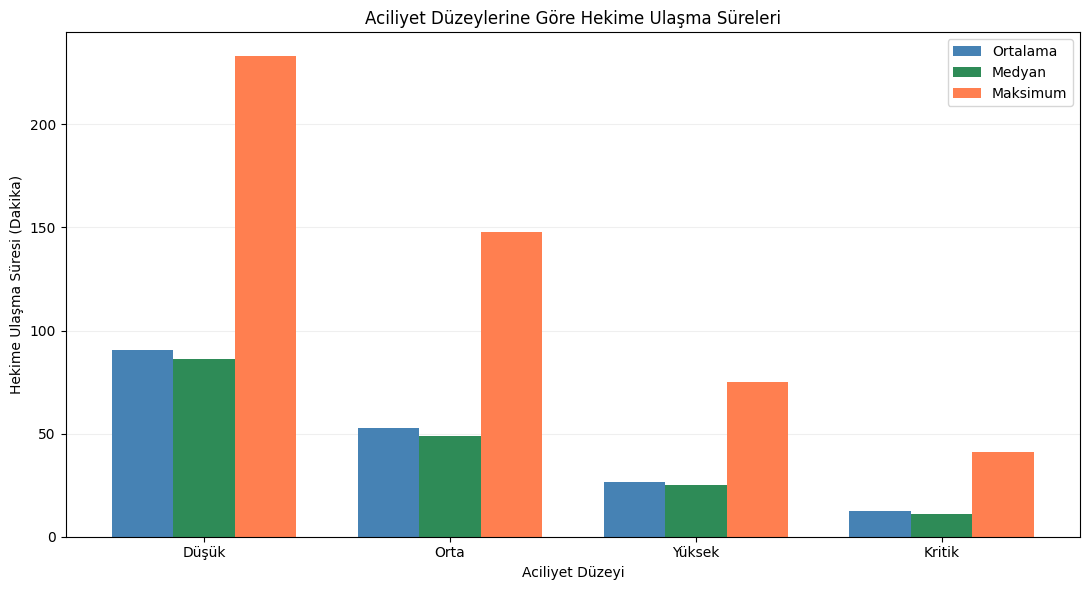

In [ ]:

# ============================================================
# HÜCRE 13 — ACİLİYET DÜZEYİNE GÖRE HEKİME ULAŞMA SÜRESİ
# ============================================================

sutun = "Hekime Ulaşma Süresi (dk)"
duzeyler = ["Low", "Medium", "High", "Critical"]
etiketler = ["Düşük", "Orta", "Yüksek", "Kritik"]

veri_13 = df_tr[["Aciliyet Düzeyi", sutun]].copy()
veri_13[sutun] = pd.to_numeric(
    veri_13[sutun], errors="coerce"
)

tablo_13 = (
    veri_13.groupby("Aciliyet Düzeyi")[sutun]
    .agg(
        Hasta_Sayısı="size",
        Ortalama="mean",
        Medyan="median",
        Minimum="min",
        Maksimum="max",
        Standart_Sapma="std",
        Sıfır_Süre_Sayısı=lambda x: (x == 0).sum(),
        Eksik_Süre_Sayısı=lambda x: x.isna().sum()
    )
    .reindex(duzeyler)
    .round(2)
)

tablo_13.index = etiketler

print("HÜCRE 13 — HEKİME ULAŞMA SÜRESİ ANALİZİ")
display(tablo_13)

# Grafik
x = np.arange(len(etiketler))
genislik = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for konum, kolon, renk in [
    (-genislik, "Ortalama", "steelblue"),
    (0, "Medyan", "seagreen"),
    (genislik, "Maksimum", "coral")
]:
    ax.bar(
        x + konum,
        tablo_13[kolon],
        genislik,
        label=kolon,
        color=renk
    )

ax.set_xticks(x)
ax.set_xticklabels(etiketler)
ax.set_xlabel("Aciliyet Düzeyi")
ax.set_ylabel("Hekime Ulaşma Süresi (Dakika)")
ax.set_title("Aciliyet Düzeylerine Göre Hekime Ulaşma Süreleri")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


HÜCRE 14 — TOPLAM BEKLEME SÜRESİ ANALİZİ


,Hasta_Sayısı,Ortalama,Medyan,Minimum,Maksimum,Standart_Sapma,Sıfır_Süre_Sayısı,Eksik_Süre_Sayısı
Düşük,1222,173.54,165.0,70,442,57.00,0,0
Orta,1291,93.70,89.0,28,245,33.77,0,0
Yüksek,1245,43.19,41.0,13,111,16.30,0,0
Kritik,1242,18.35,17.0,4,60,8.11,0,0


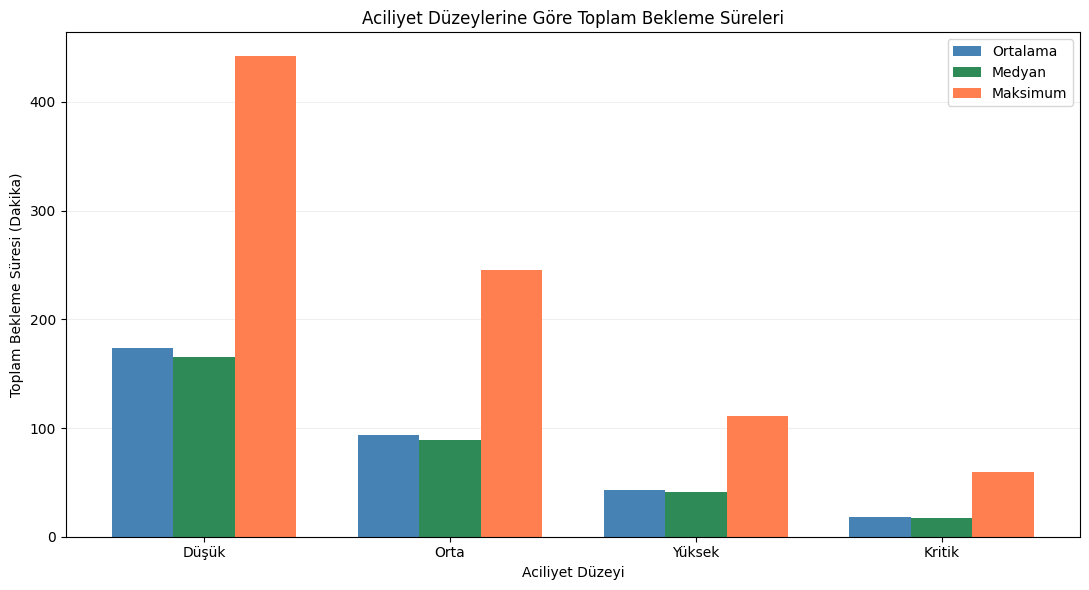

In [ ]:

# ============================================================
# HÜCRE 14 — ACİLİYET DÜZEYİNE GÖRE TOPLAM BEKLEME SÜRESİ
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sutun = "Toplam Bekleme Süresi (dk)"
duzeyler = ["Low", "Medium", "High", "Critical"]
etiketler = ["Düşük", "Orta", "Yüksek", "Kritik"]

veri_14 = df_tr[["Aciliyet Düzeyi", sutun]].copy()
veri_14[sutun] = pd.to_numeric(
    veri_14[sutun], errors="coerce"
)

# İstatistiksel özet
tablo_14 = (
    veri_14.groupby("Aciliyet Düzeyi")[sutun]
    .agg(
        Hasta_Sayısı="size",
        Ortalama="mean",
        Medyan="median",
        Minimum="min",
        Maksimum="max",
        Standart_Sapma="std",
        Sıfır_Süre_Sayısı=lambda x: (x == 0).sum(),
        Eksik_Süre_Sayısı=lambda x: x.isna().sum()
    )
    .reindex(duzeyler)
    .round(2)
)

tablo_14.index = etiketler

print("HÜCRE 14 — TOPLAM BEKLEME SÜRESİ ANALİZİ")
display(tablo_14)

# Karşılaştırma grafiği
x = np.arange(len(etiketler))
genislik = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for konum, kolon, renk in [
    (-genislik, "Ortalama", "steelblue"),
    (0, "Medyan", "seagreen"),
    (genislik, "Maksimum", "coral")
]:
    ax.bar(
        x + konum,
        tablo_14[kolon],
        genislik,
        label=kolon,
        color=renk
    )

ax.set_xticks(x)
ax.set_xticklabels(etiketler)
ax.set_xlabel("Aciliyet Düzeyi")
ax.set_ylabel("Toplam Bekleme Süresi (Dakika)")
ax.set_title("Aciliyet Düzeylerine Göre Toplam Bekleme Süreleri")

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


HÜCRE 15 — ORTALAMA BEKLEME SÜRELERİ (DAKİKA)


,Kayıt,Triyaj,Hekime Ulaşma,Toplam Bekleme
Düşük,24.33,58.70,90.51,173.54
Orta,14.84,26.18,52.67,93.70
Yüksek,5.65,11.00,26.54,43.19
Kritik,2.09,3.96,12.31,18.35


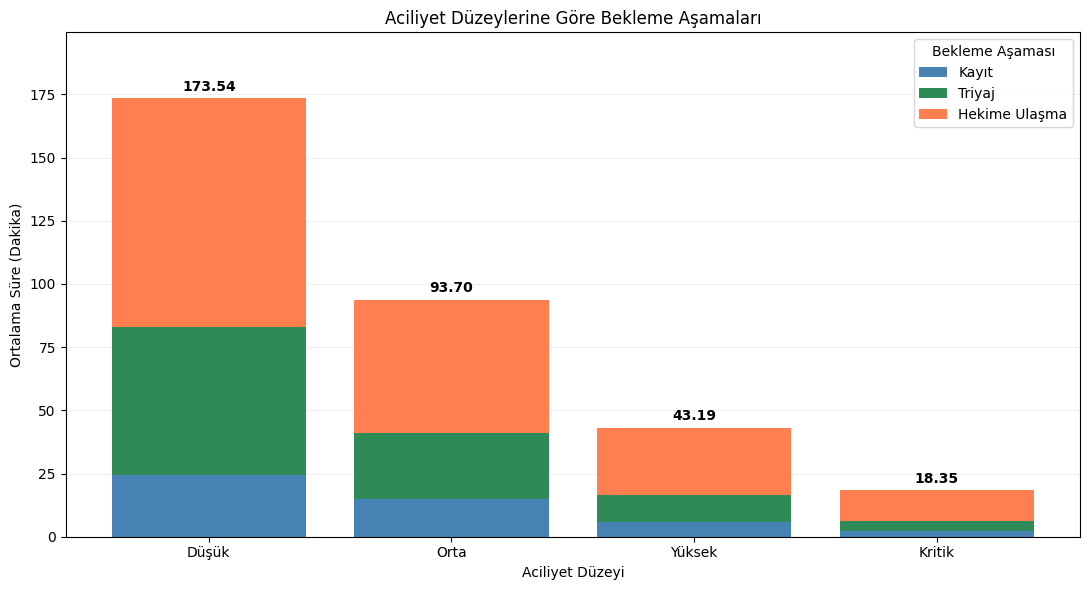

In [ ]:

# ============================================================
# HÜCRE 15 — TÜM BEKLEME AŞAMALARININ KARŞILAŞTIRILMASI
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sure_sutunlari = [
    "Kayıt Süresi (dk)",
    "Triyaj Süresi (dk)",
    "Hekime Ulaşma Süresi (dk)",
    "Toplam Bekleme Süresi (dk)"
]

duzeyler = ["Low", "Medium", "High", "Critical"]
etiketler = ["Düşük", "Orta", "Yüksek", "Kritik"]

# Mevcut verilerden ortalama süreleri hesapla
veri_15 = df_tr[["Aciliyet Düzeyi"] + sure_sutunlari].copy()

veri_15[sure_sutunlari] = veri_15[sure_sutunlari].apply(
    pd.to_numeric, errors="coerce"
)

tablo_15 = (
    veri_15.groupby("Aciliyet Düzeyi")[sure_sutunlari]
    .mean()
    .reindex(duzeyler)
)

tablo_15.index = etiketler

tablo_15.columns = [
    "Kayıt",
    "Triyaj",
    "Hekime Ulaşma",
    "Toplam Bekleme"
]

print("HÜCRE 15 — ORTALAMA BEKLEME SÜRELERİ (DAKİKA)")
display(tablo_15.round(2))

# Yığılmış sütun grafiği
fig, ax = plt.subplots(figsize=(11, 6))

alt = np.zeros(len(tablo_15))

for kolon, renk in [
    ("Kayıt", "steelblue"),
    ("Triyaj", "seagreen"),
    ("Hekime Ulaşma", "coral")
]:
    ax.bar(
        tablo_15.index,
        tablo_15[kolon],
        bottom=alt,
        label=kolon,
        color=renk
    )
    alt += tablo_15[kolon].to_numpy()

# Toplam süreleri sütunların üzerine yaz
for i, toplam in enumerate(tablo_15["Toplam Bekleme"]):
    ax.text(
        i, toplam + 3,
        f"{toplam:.2f}",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Aciliyet Düzeylerine Göre Bekleme Aşamaları")
ax.set_xlabel("Aciliyet Düzeyi")
ax.set_ylabel("Ortalama Süre (Dakika)")
ax.legend(title="Bekleme Aşaması")
ax.set_ylim(0, tablo_15["Toplam Bekleme"].max() * 1.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



## HÜCRE 9–15 | Aciliyet Düzeylerine Göre Bekleme Sürelerinin Genel Değerlendirmesi

### 1. Analizin Amacı

Bu bölümde 5.000 hasta kaydının aciliyet düzeylerine göre kayıt, triyaj, hekime ulaşma ve toplam bekleme süreleri analiz edilmiştir.

Amaç, hasta bekleme sürelerinin hangi aşamalarda yoğunlaştığını belirlemek, aciliyet düzeylerine göre farklılıkları incelemek ve hastane süreçlerinin iyileştirilmesine yönelik araştırma soruları geliştirmektir.

### 2. Aciliyet Düzeylerinin Dağılımı

| Aciliyet Düzeyi | Hasta Sayısı | Oran (%) |
|---|---:|---:|
| Düşük | 1.222 | 24,44 |
| Orta | 1.291 | 25,82 |
| Yüksek | 1.245 | 24,90 |
| Kritik | 1.242 | 24,84 |
| **Toplam** | **5.000** | **100,00** |

Aciliyet düzeylerinin birbirine yakın oranlarda dağılması, veri setinin dengeli oluşturulmuş olabileceğini düşündürmektedir. Bunun veri üretimi veya örnekleme yönteminden kaynaklanıp kaynaklanmadığı ayrıca doğrulanmalıdır.

### 3. Bekleme Sürelerinin Karşılaştırılması

Aciliyet düzeylerine göre ortalama süreler aşağıda sunulmuştur.

| Aciliyet | Kayıt (dk) | Triyaj (dk) | Hekime Ulaşma (dk) | Toplam (dk) |
|---|---:|---:|---:|---:|
| Düşük | 24,33 | 58,70 | 90,51 | 173,54 |
| Orta | 14,84 | 26,18 | 52,67 | 93,70 |
| Yüksek | 5,65 | 11,00 | 26,54 | 43,19 |
| Kritik | 2,09 | 3,96 | 12,31 | 18,35 |

**Temel bulgu:** Aciliyet düzeyi arttıkça kayıt, triyaj, hekime ulaşma ve toplam bekleme sürelerinin ortalamaları azalmaktadır.

Tüm aciliyet gruplarında toplam bekleme süresinin en büyük ortalama bileşeni hekime ulaşma süresidir.

Düşük aciliyetli hastalarda ortalama toplam sürenin yaklaşık %52'si, kritik hastalarda ise yaklaşık %67'si hekime ulaşma aşamasından oluşmaktadır.

Bu bulgu, hekime ulaşma süresinin hasta akışı açısından öncelikle araştırılması gereken aşamalardan biri olduğunu göstermektedir.

### 4. Uzun Bekleme Süreleri

Düşük aciliyetli hastalarda maksimum süreler:

- Kayıt: 66 dakika
- Triyaj: 163 dakika
- Hekime ulaşma: 233 dakika
- Toplam bekleme: 442 dakika

Kritik hastalarda maksimum süreler:

- Kayıt: 8 dakika
- Triyaj: 13 dakika
- Hekime ulaşma: 41 dakika
- Toplam bekleme: 60 dakika

Düşük aciliyet grubunda minimum toplam bekleme süresi 70 dakika, kritik grupta maksimum toplam bekleme süresi 60 dakikadır. Dolayısıyla bu iki grubun toplam bekleme süreleri örtüşmemektedir.

Buna karşılık hekime ulaşma sürelerinde kritik hastaların maksimum süresi 41 dakika, düşük aciliyetli hastaların minimum süresi 32 dakikadır. Bu durum, grupların bireysel süre aralıklarının örtüşebildiğini göstermektedir.

Özellikle kritik hastalarda uzun hekime ulaşma sürelerinin hangi koşullarda ortaya çıktığı araştırılmalıdır.

### 5. Sıfır Kayıt Süreleri

Kayıt süresi analizinde 111 hastanın kayıt süresi sıfır dakika olarak belirlenmiştir.

Bu kayıtların tamamı kritik aciliyet grubunda bulunmaktadır.

Sıfır sürelerin nedenleri arasında farklı idari kayıt süreçleri, sürelerin yuvarlanması veya sentetik veri üretim kuralları bulunabilir.

Ambulansla gelen hastalarda farklı kayıt prosedürlerinin uygulanması da araştırılabilecek bir hipotezdir. Ancak mevcut bulgular bu açıklamayı doğrulamamaktadır.

### 6. Veri Tutarlılığı

HÜCRE 15'te toplam bekleme süresinin üç alt süreyle matematiksel tutarlılığı kontrol edilmiştir.

- Kontrol edilen kayıt: 5.000
- Eşleşen kayıt: 5.000
- Farklı kayıt: 0
- Eksik/geçersiz kayıt: 0

Bütün kayıtlarda şu eşitlik sağlanmıştır:

**Toplam Bekleme Süresi = Kayıt Süresi + Triyaj Süresi + Hekime Ulaşma Süresi**

Bu sonuç, süre değişkenlerinin matematiksel tutarlılığını doğrulamaktadır. Ancak ölçümlerin klinik açıdan doğruluğunu tek başına kanıtlamamaktadır.

### 7. Araştırılması Gereken Konular

1. Hekime ulaşma sürelerinin uzamasında hastane yoğunluğunun ve uzman hekim mevcudiyetinin etkisi.
2. Düşük aciliyetli hastalarda uzun triyaj sürelerinin nedenleri.
3. Kritik hastalarda uzun hekime ulaşma sürelerinin sıklığı ve koşulları.
4. Kritik hastalardaki 111 sıfır kayıt süresinin oluşma nedeni.
5. Bekleme süreleri ile hastaların muayene edilmeden ayrılmaları arasında ilişki bulunup bulunmadığı.

Bu konular doğrulanmış nedenler değil, sonraki analizlerde araştırılacak hipotezlerdir.

### 8. Genel Sonuç

Analiz sonucunda, aciliyet düzeyi yükseldikçe hasta bekleme sürelerinin belirgin biçimde azaldığı görülmüştür.

Toplam bekleme süresinin en büyük ortalama bileşeni bütün gruplarda hekime ulaşma aşamasıdır.

Bu nedenle hekime ulaşma süreçlerinin ayrıntılı incelenmesi, hasta akışının değerlendirilmesi açısından önem taşımaktadır.

Bununla birlikte veri setinin sentetik olabileceği dikkate alınmalı, elde edilen sonuçlar gerçek hastane uygulamalarına doğrudan genellenmemelidir.

Çalışmanın sonraki aşamasında **Hasta Sonucu** değişkeni incelenerek, muayene edilmeden ayrılan hastaların belirlenmesi ve bu durumun bekleme süreleriyle ilişkisinin araştırılması hedeflenmektedir.


In [ ]:

# ============================================================
# HÜCRE 16 — HASTA SONUÇLARININ TÜRKÇE DAĞILIMI
# ============================================================

ceviri = {
    "Discharged": "Taburcu Edildi",
    "Admitted": "Hastaneye Yatırıldı",
    "Left Without Being Seen": "Hekim Tarafından Görülmeden Ayrıldı"
}

sonuclar = df_tr["Hasta Sonucu"].replace(ceviri)

tablo_16 = (
    sonuclar.value_counts(dropna=False)
    .rename_axis("Hasta Sonucu")
    .reset_index(name="Hasta Sayısı")
)

tablo_16["Yüzde (%)"] = (
    tablo_16["Hasta Sayısı"] / len(df_tr) * 100
).round(2)

print("HÜCRE 16 — HASTA SONUÇLARININ DAĞILIMI")
display(tablo_16)

print("Toplam kayıt:", len(df_tr))
print("Eksik sonuç:", df_tr["Hasta Sonucu"].isna().sum())


HÜCRE 16 — HASTA SONUÇLARININ DAĞILIMI


,Hasta Sonucu,Hasta Sayısı,Yüzde (%)
0,Taburcu Edildi,2879,57.58
1,Hastaneye Yatırıldı,1868,37.36
2,Hekim Tarafından Görülmeden Ayrıldı,253,5.06


Toplam kayıt: 5000
Eksik sonuç: 0


HÜCRE 17 — HASTA SONUÇLARINA GÖRE BEKLEME SÜRELERİ


,Hasta_Sayısı,Ortalama_Kayıt,Ortalama_Triyaj,Ortalama_Hekime_Ulaşma,Ortalama_Toplam,Medyan_Toplam,Maksimum_Toplam
Hasta Sonucu,,,,,,,
Hastaneye Yatırıldı,1868,7.03,13.14,28.48,48.65,41.0,120
Muayene Olmadan Ayrıldı,253,25.58,59.64,93.82,179.05,169.0,380
Taburcu Edildi,2879,13.52,29.35,52.10,94.96,76.0,442


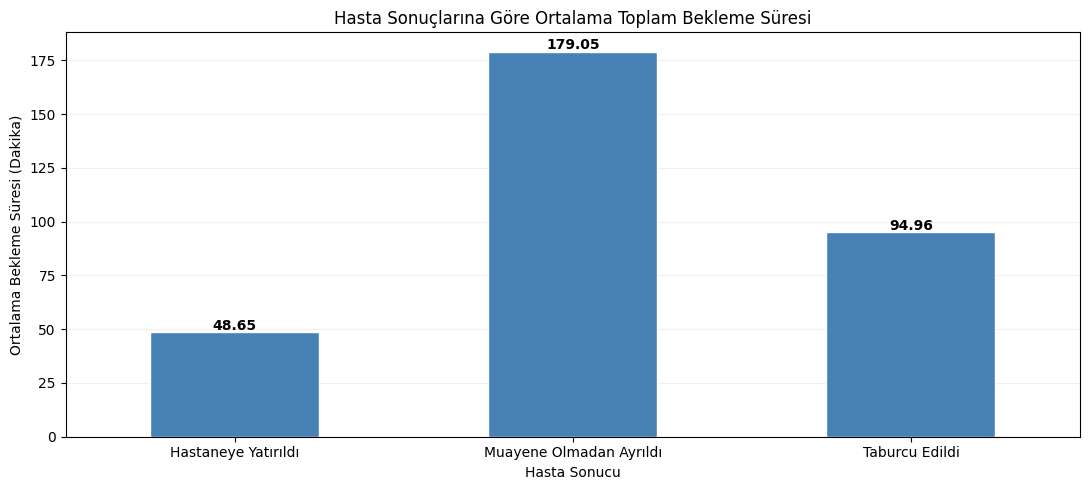

In [ ]:

# ============================================================
# HÜCRE 17 — HASTA SONUÇLARINA GÖRE BEKLEME SÜRELERİ
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

ceviri = {
    "Discharged": "Taburcu Edildi",
    "Admitted": "Hastaneye Yatırıldı",
    "Left Without Being Seen": "Muayene Olmadan Ayrıldı"
}

sutunlar = [
    "Kayıt Süresi (dk)",
    "Triyaj Süresi (dk)",
    "Hekime Ulaşma Süresi (dk)",
    "Toplam Bekleme Süresi (dk)"
]

veri_17 = df_tr[["Hasta Sonucu"] + sutunlar].copy()
veri_17["Hasta Sonucu"] = veri_17["Hasta Sonucu"].replace(ceviri)
veri_17[sutunlar] = veri_17[sutunlar].apply(
    pd.to_numeric, errors="coerce"
)

# Hasta sayılarını ve ortalama süreleri hesapla
tablo_17 = veri_17.groupby("Hasta Sonucu").agg(
    Hasta_Sayısı=("Toplam Bekleme Süresi (dk)", "size"),
    Ortalama_Kayıt=("Kayıt Süresi (dk)", "mean"),
    Ortalama_Triyaj=("Triyaj Süresi (dk)", "mean"),
    Ortalama_Hekime_Ulaşma=("Hekime Ulaşma Süresi (dk)", "mean"),
    Ortalama_Toplam=("Toplam Bekleme Süresi (dk)", "mean"),
    Medyan_Toplam=("Toplam Bekleme Süresi (dk)", "median"),
    Maksimum_Toplam=("Toplam Bekleme Süresi (dk)", "max")
).round(2)

print("HÜCRE 17 — HASTA SONUÇLARINA GÖRE BEKLEME SÜRELERİ")
display(tablo_17)

# Toplam bekleme süresi karşılaştırma grafiği
ax = tablo_17["Ortalama_Toplam"].plot(
    kind="bar",
    figsize=(11, 5),
    color="steelblue",
    edgecolor="white"
)

ax.set_title("Hasta Sonuçlarına Göre Ortalama Toplam Bekleme Süresi")
ax.set_xlabel("Hasta Sonucu")
ax.set_ylabel("Ortalama Bekleme Süresi (Dakika)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for i, deger in enumerate(tablo_17["Ortalama_Toplam"]):
    ax.text(i, deger + 1, f"{deger:.2f}",
            ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


HÜCRE 18 — ACİLİYET DÜZEYLERİNE GÖRE AYRILMA


,Toplam Hasta,Muayene Olmadan Ayrılan,Grup İçi Ayrılma Oranı (%),Ayrılanlar İçindeki Pay (%)
Düşük,1222,198,16.20,78.26
Orta,1291,55,4.26,21.74
Yüksek,1245,0,0.00,0.00
Kritik,1242,0,0.00,0.00


Muayene olmadan ayrılan toplam: 253


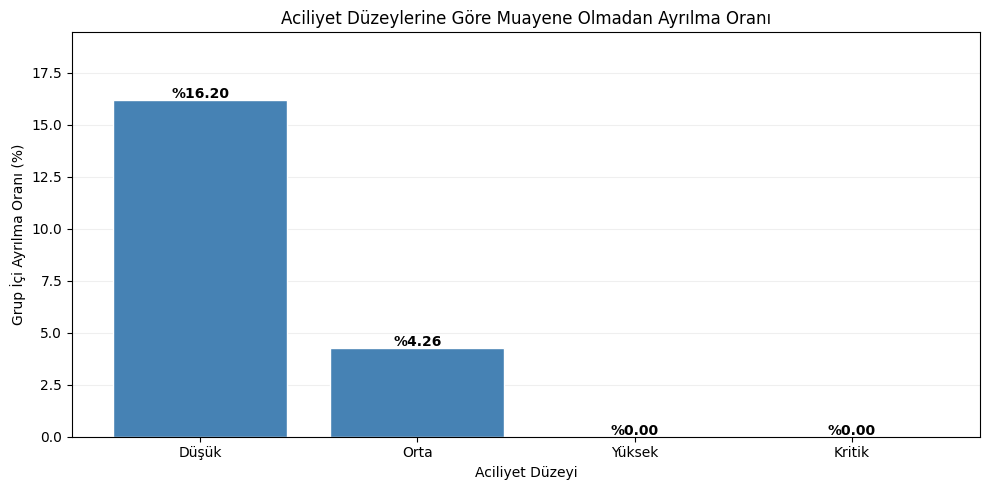

In [ ]:

# ============================================================
# HÜCRE 18 — MUAYENE OLMADAN AYRILAN HASTALARIN
# ACİLİYET DÜZEYLERİNE GÖRE DAĞILIMI
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

duzeyler = ["Low", "Medium", "High", "Critical"]
etiketler = ["Düşük", "Orta", "Yüksek", "Kritik"]

# Her aciliyet grubundaki toplam hasta sayısı
toplam = (
    df_tr["Aciliyet Düzeyi"]
    .value_counts()
    .reindex(duzeyler, fill_value=0)
)

# Muayene olmadan ayrılan hastalar
lwbs = df_tr[
    df_tr["Hasta Sonucu"] == "Left Without Being Seen"
]

ayrilan = (
    lwbs["Aciliyet Düzeyi"]
    .value_counts()
    .reindex(duzeyler, fill_value=0)
)

tablo_18 = pd.DataFrame({
    "Toplam Hasta": toplam,
    "Muayene Olmadan Ayrılan": ayrilan,
    "Grup İçi Ayrılma Oranı (%)": (
        ayrilan / toplam.replace(0, float("nan")) * 100
    ).round(2),
    "Ayrılanlar İçindeki Pay (%)": (
        ayrilan / len(lwbs) * 100
    ).round(2)
})

tablo_18.index = etiketler

print("HÜCRE 18 — ACİLİYET DÜZEYLERİNE GÖRE AYRILMA")
display(tablo_18)

print("Muayene olmadan ayrılan toplam:", len(lwbs))

# Grafik
fig, ax = plt.subplots(figsize=(10, 5))

oranlar = tablo_18["Grup İçi Ayrılma Oranı (%)"]

ax.bar(
    oranlar.index,
    oranlar.values,
    color="steelblue",
    edgecolor="white"
)

for i, oran in enumerate(oranlar):
    ax.text(
        i, oran + 0.1,
        f"%{oran:.2f}",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Aciliyet Düzeylerine Göre Muayene Olmadan Ayrılma Oranı")
ax.set_xlabel("Aciliyet Düzeyi")
ax.set_ylabel("Grup İçi Ayrılma Oranı (%)")
ax.set_ylim(0, max(oranlar.max() * 1.2, 1))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# HÜCRE 19 — ACİLİYET DÜZEYİ VE HASTA SONUCUNA GÖRE
# BEKLEME SÜRELERİNİN KARŞILAŞTIRILMASI
# ============================================================
# Yalnızca düşük ve orta aciliyet grupları
# ============================================================
veri = df_tr[
    df_tr["Aciliyet Düzeyi"].isin(["Low", "Medium"])
].copy()

# Hasta sonuçlarını iki gruba ayır
veri["Hasta Grubu"] = veri["Hasta Sonucu"].apply(
    lambda x: "Muayene Olmadan Ayrıldı"
    if x == "Left Without Being Seen"
    else "Diğer Hastalar"
)

# Karşılaştırma tablosu
tablo_19 = veri.groupby(
    ["Aciliyet Düzeyi", "Hasta Grubu"]
)["Toplam Bekleme Süresi (dk)"].agg(
    Hasta_Sayısı="count",
    Ortalama_Bekleme="mean",
    Medyan_Bekleme="median",
    Minimum_Bekleme="min",
    Maksimum_Bekleme="max"
).round(2)

# Aciliyet düzeylerinin sırası
tablo_19 = tablo_19.reindex(
    ["Low", "Medium"],
    level="Aciliyet Düzeyi"
)

print("HÜCRE 19 — BEKLEME SÜRELERİNİN KARŞILAŞTIRILMASI")
display(tablo_19)


HÜCRE 19 — BEKLEME SÜRELERİNİN KARŞILAŞTIRILMASI


Hasta_Sayısı  Ortalama_Bekleme  \
Aciliyet Düzeyi Hasta Grubu                                               
Low             Diğer Hastalar                   1024            170.59   
                Muayene Olmadan Ayrıldı           198            188.79   
Medium          Diğer Hastalar                   1236             91.46   
                Muayene Olmadan Ayrıldı            55            143.96   

                                         Medyan_Bekleme  Minimum_Bekleme  \
Aciliyet Düzeyi Hasta Grubu                                                
Low             Diğer Hastalar                    162.0               70   
                Muayene Olmadan Ayrıldı           180.5              122   
Medium          Diğer Hastalar                     87.0               28   
                Muayene Olmadan Ayrıldı           137.0              121   

                                         Maksimum_Bekleme  
Aciliyet Düzeyi Hasta Grubu                                
Low             Diğer Hastalar                        442  
                Muayene Olmadan Ayrıldı               380  
Medium          Diğer Hastalar                        245  
                Muayene Olmadan Ayrıldı               195

## HÜCRE 16–19 — Hasta Sonuçları ve Bekleme Sürelerinin Analizi

### HÜCRE 16 — Hasta Sonuçlarının Dağılımı

Toplam 5.000 hasta ziyareti üç farklı sonuç kategorisinde değerlendirilmiştir.

| Hasta sonucu | Hasta sayısı | Oran |
|---|---:|---:|
| Taburcu edilen | 2.879 | %57,58 |
| Hastaneye yatırılan | 1.868 | %37,36 |
| Muayene olmadan ayrılan | 253 | %5,06 |

**Değerlendirme:** Hasta ziyaretlerinin çoğunluğu taburcu edilme ile sonuçlanmıştır. Bununla birlikte, 253 hastanın doktor muayenesi olmadan ayrılması, hizmet süreçleri açısından incelenmesi gereken bir bulgudur.

### HÜCRE 17 — Hasta Sonuçlarına Göre Bekleme Süreleri

Hasta sonuçlarına göre ortalama toplam bekleme süreleri karşılaştırılmıştır.

| Hasta sonucu | Ortalama bekleme |
|---|---:|
| Hastaneye yatırılan | 48,65 dk |
| Taburcu edilen | 94,96 dk |
| Muayene olmadan ayrılan | 179,05 dk |

**Değerlendirme:** En yüksek ortalama bekleme süresi, muayene olmadan ayrılan hastalarda gözlenmiştir. Bu durum bekleme süresi ile hasta sonucu arasında bir ilişki olabileceğini düşündürmektedir. Ancak aciliyet düzeylerinin etkisi dikkate alınmadan nedensel bir yorum yapılamaz.

### HÜCRE 18 — Muayene Olmadan Ayrılan Hastaların Aciliyet Düzeylerine Göre Dağılımı

| Aciliyet düzeyi | Toplam hasta | Muayenesiz ayrılan | Ayrılma oranı |
|---|---:|---:|---:|
| Düşük | 1.222 | 198 | %16,20 |
| Orta | 1.291 | 55 | %4,26 |
| Yüksek | 1.245 | 0 | %0 |
| Kritik | 1.242 | 0 | %0 |

**Değerlendirme:** Muayene olmadan ayrılmaların tamamı düşük ve orta aciliyet düzeylerinde gerçekleşmiştir. En yüksek ayrılma oranı düşük aciliyet grubunda görülmüştür. Yüksek ve kritik aciliyet gruplarında muayene olmadan ayrılan hasta bulunmamaktadır.

### HÜCRE 19 — Aciliyet Düzeyi ve Hasta Sonucuna Göre Bekleme Sürelerinin Karşılaştırılması

Aynı aciliyet düzeyindeki hastaların bekleme süreleri, muayene olmadan ayrılma durumlarına göre karşılaştırılmıştır.

| Aciliyet düzeyi | Hasta grubu | Hasta sayısı | Ortalama bekleme | Medyan |
|---|---|---:|---:|---:|
| Düşük | Diğer hastalar | 1.024 | 170,59 dk | 162 dk |
| Düşük | Muayenesiz ayrılan | 198 | 188,79 dk | 180,5 dk |
| Orta | Diğer hastalar | 1.236 | 91,46 dk | 87 dk |
| Orta | Muayenesiz ayrılan | 55 | 143,96 dk | 137 dk |

**Değerlendirme:** Düşük aciliyet grubunda muayene olmadan ayrılan hastaların ortalama bekleme süresi diğer hastalardan 18,20 dakika daha uzundur. Orta aciliyet grubunda ise bu fark 52,50 dakikadır.

Her iki grupta da muayene olmadan ayrılan hastaların ortalama ve medyan bekleme sürelerinin daha yüksek olması, bekleme süresi ile muayene olmadan ayrılma arasındaki olası ilişkiye işaret etmektedir.

### Genel Sonuç ve Sonraki Araştırma Aşaması

HÜCRE 16–19 kapsamında elde edilen bulgular, muayene olmadan ayrılan hastaların düşük ve orta aciliyet düzeylerinde yoğunlaştığını ve aynı aciliyet düzeyindeki diğer hastalara kıyasla daha uzun bekleme sürelerine sahip olduğunu göstermektedir.

Bununla birlikte, mevcut sonuçlar betimsel analizlere dayanmaktadır. Gözlenen farklılıkların istatistiksel anlamlılığı henüz test edilmemiştir. Ayrıca muayenesiz ayrılan hastalar için toplam bekleme süresinin nasıl tanımlandığı doğrulanmalıdır.

**Sonraki aşamada**, aciliyet düzeyi kontrol edilerek bekleme süresi ile muayene olmadan ayrılma arasındaki ilişkinin istatistiksel olarak incelenmesi önerilmektedir.

In [ ]:

# HÜCRE 20 — BEKLEME SÜRELERİNİN İSTATİSTİKSEL KARŞILAŞTIRILMASI

from scipy.stats import mannwhitneyu
import pandas as pd

sonuclar_20 = []

for aciliyet in ["Low", "Medium"]:
    veri = df_tr[df_tr["Aciliyet Düzeyi"] == aciliyet]

    ayrilan = veri.loc[
        veri["Hasta Sonucu"] == "Left Without Being Seen",
        "Toplam Bekleme Süresi (dk)"
    ].dropna()

    diger = veri.loc[
        veri["Hasta Sonucu"] != "Left Without Being Seen",
        "Toplam Bekleme Süresi (dk)"
    ].dropna()

    if ayrilan.empty or diger.empty:
        print(f"{aciliyet}: Karşılaştırma için yeterli grup yok.")
        continue

    u, p = mannwhitneyu(
        ayrilan, diger, alternative="two-sided"
    )

    sonuclar_20.append({
        "Aciliyet Düzeyi": aciliyet,
        "Ayrılan Hasta": len(ayrilan),
        "Diğer Hasta": len(diger),
        "Ortalama Farkı (dk)": round(
            ayrilan.mean() - diger.mean(), 2
        ),
        "U İstatistiği": round(u, 2),
        "p Değeri": p
    })

tablo_20 = pd.DataFrame(sonuclar_20)

if not tablo_20.empty:
    # İki karşılaştırma için Bonferroni düzeltmesi
    tablo_20["Düzeltilmiş p"] = (
        tablo_20["p Değeri"] * len(tablo_20)
    ).clip(upper=1)

print("HÜCRE 20 — İSTATİSTİKSEL TEST SONUÇLARI")
display(tablo_20)


HÜCRE 20 — İSTATİSTİKSEL TEST SONUÇLARI


,Aciliyet Düzeyi,Ayrılan Hasta,Diğer Hasta,Ortalama Farkı (dk),U İstatistiği,p Değeri,Düzeltilmiş p
0,Low,198,1024,18.21,121706.0,7.738096e-06,1.547619e-05
1,Medium,55,1236,52.50,62189.5,1.929140e-25,3.858280e-25


In [ ]:

# HÜCRE 21 — MANN-WHITNEY U ETKİ BÜYÜKLÜĞÜ

import pandas as pd

tablo_21 = tablo_20[[
    "Aciliyet Düzeyi",
    "Ayrılan Hasta",
    "Diğer Hasta",
    "U İstatistiği"
]].copy()

# Rank-biserial korelasyon
# Pozitif değer: ayrılan hastaların daha uzun bekleme eğilimi
tablo_21["Etki Büyüklüğü (r_rb)"] = (
    2 * tablo_21["U İstatistiği"]
    / (tablo_21["Ayrılan Hasta"] * tablo_21["Diğer Hasta"])
    - 1
).round(3)

print("HÜCRE 21 — ETKİ BÜYÜKLÜĞÜ SONUÇLARI")
display(tablo_21)


HÜCRE 21 — ETKİ BÜYÜKLÜĞÜ SONUÇLARI


,Aciliyet Düzeyi,Ayrılan Hasta,Diğer Hasta,U İstatistiği,Etki Büyüklüğü (r_rb)
0,Low,198,1024,121706.0,0.201
1,Medium,55,1236,62189.5,0.830


In [ ]:

# HÜCRE 22 — HASTANELERE GÖRE BEKLEME SÜRELERİ

import pandas as pd

# Hastane sütununu mevcut veriden bul

hastane_adaylari = ["Hastane Adı"]

if len(hastane_adaylari) != 1:
    print("Hastane sütunu kesin olarak belirlenemedi.")
    print("Olası sütunlar:", hastane_adaylari)
    print("Tüm sütunlar:", df_tr.columns.tolist())
else:
    hastane_sutunu = hastane_adaylari[0]

    veri_22 = df_tr[
        df_tr["Aciliyet Düzeyi"].isin(["Low", "Medium"])
    ].copy()

    veri_22["Hasta Grubu"] = veri_22["Hasta Sonucu"].eq(
        "Left Without Being Seen"
    ).map({
        True: "Muayene Olmadan Ayrılan",
        False: "Diğer Hastalar"
    })

    ozet = veri_22.groupby(
        [hastane_sutunu, "Aciliyet Düzeyi", "Hasta Grubu"]
    )["Toplam Bekleme Süresi (dk)"].agg(
        Hasta_Sayısı="count",
        Ortalama_Bekleme="mean"
    ).unstack("Hasta Grubu")

    ozet.columns = [
        f"{olcu}_{grup}"
        for olcu, grup in ozet.columns
    ]

    tablo_22 = ozet.reset_index()

    tablo_22["Ortalama_Fark_Dk"] = (
        tablo_22["Ortalama_Bekleme_Muayene Olmadan Ayrılan"]
        - tablo_22["Ortalama_Bekleme_Diğer Hastalar"]
    )

    tablo_22 = tablo_22.round(2)

    print("HÜCRE 22 — HASTANELERE GÖRE KARŞILAŞTIRMA")
    display(tablo_22)


HÜCRE 22 — HASTANELERE GÖRE KARŞILAŞTIRMA


,Hastane Adı,Aciliyet Düzeyi,Hasta_Sayısı_Diğer Hastalar,Hasta_Sayısı_Muayene Olmadan Ayrılan,Ortalama_Bekleme_Diğer Hastalar,Ortalama_Bekleme_Muayene Olmadan Ayrılan,Ortalama_Fark_Dk
0,Northside Community Hospital,Low,206,39,173.83,193.15,19.32
1,Northside Community Hospital,Medium,239,8,91.41,143.75,52.34
2,Riverside Medical Center,Low,207,35,169.32,187.40,18.08
3,Riverside Medical Center,Medium,255,17,92.31,142.76,50.46
4,Springfield General Hospital,Low,213,38,167.56,187.55,19.99
5,Springfield General Hospital,Medium,240,12,92.62,143.33,50.71
6,St. Mary’s Regional Health,Low,208,37,169.43,190.89,21.46
7,St. Mary’s Regional Health,Medium,267,10,88.58,143.60,55.02
8,Summit Health Center,Low,190,49,173.10,185.69,12.59
9,Summit Health Center,Medium,235,8,92.67,148.12,55.45


In [ ]:

# HÜCRE 23 — HASTANELER ARASI BEKLEME FARKLARININ TESTİ

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

sonuclar_23 = []

for aciliyet in ["Low", "Medium"]:
    veri = df_tr.loc[
        df_tr["Aciliyet Düzeyi"] == aciliyet,
        ["Hastane Adı", "Hasta Sonucu", "Toplam Bekleme Süresi (dk)"]
    ].copy()

    veri["ayrilma"] = (
        veri["Hasta Sonucu"] == "Left Without Being Seen"
    ).astype(int)

    veri["Toplam Bekleme Süresi (dk)"] = pd.to_numeric(
        veri["Toplam Bekleme Süresi (dk)"], errors="coerce"
    )
    veri = veri.dropna()

    model = smf.ols(
        'Q("Toplam Bekleme Süresi (dk)") ~ '
        'C(Q("Hastane Adı")) * C(ayrilma)',
        data=veri
    ).fit(cov_type="HC3")

    # Hastane ile ayrılma durumu arasındaki etkileşim
    terimler = [
        i for i, ad in enumerate(model.model.exog_names)
        if ":" in ad and "ayrilma" in ad
    ]

    R = np.eye(len(model.params))[terimler]
    test = model.wald_test(R, scalar=True)

    sonuclar_23.append({
        "Aciliyet Düzeyi": aciliyet,
        "Hasta Sayısı": len(veri),
        "Test İstatistiği": float(test.statistic),
        "p Değeri": float(test.pvalue)
    })

tablo_23 = pd.DataFrame(sonuclar_23)
tablo_23["Düzeltilmiş p"] = (
    tablo_23["p Değeri"] * len(tablo_23)
).clip(upper=1)

print("HÜCRE 23 — HASTANELER ARASI FARKLILIK TESTİ")
display(tablo_23)


HÜCRE 23 — HASTANELER ARASI FARKLILIK TESTİ


,Aciliyet Düzeyi,Hasta Sayısı,Test İstatistiği,p Değeri,Düzeltilmiş p
0,Low,1222,0.600219,0.963039,1.0
1,Medium,1291,0.489093,0.974554,1.0


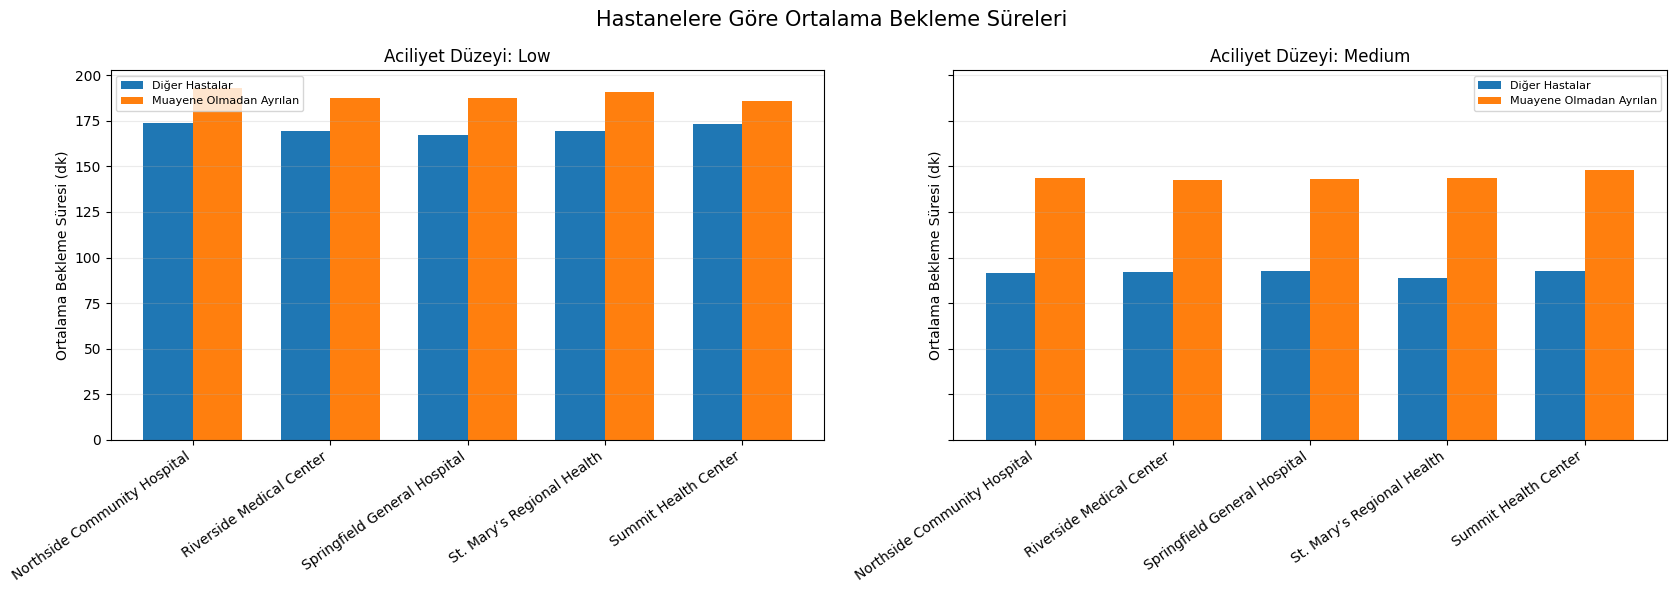

In [4]:

# HÜCRE 23A — HASTANELERE GÖRE BEKLEME SÜRELERİ GRAFİĞİ

import matplotlib.pyplot as plt
import numpy as np

# HÜCRE 22'de hazırlanmış tabloyu kullan
grafik_23a = tablo_22.copy()

gruplar = [
    ("Diğer Hastalar", "Ortalama_Bekleme_Diğer Hastalar"),
    ("Muayene Olmadan Ayrılan",
     "Ortalama_Bekleme_Muayene Olmadan Ayrılan")
]

fig, eksenler = plt.subplots(1, 2, figsize=(17, 6), sharey=True)

for ax, aciliyet in zip(eksenler, ["Low", "Medium"]):
    veri = grafik_23a[
        grafik_23a["Aciliyet Düzeyi"] == aciliyet
    ]

    x = np.arange(len(veri))
    genislik = 0.36

    for i, (etiket, sutun) in enumerate(gruplar):
        ax.bar(
            x + (i - 0.5) * genislik,
            veri[sutun],
            width=genislik,
            label=etiket
        )

    ax.set_title(f"Aciliyet Düzeyi: {aciliyet}")
    ax.set_xticks(x)
    ax.set_xticklabels(
        veri["Hastane Adı"],
        rotation=35,
        ha="right"
    )
    ax.set_ylabel("Ortalama Bekleme Süresi (dk)")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Hastanelere Göre Ortalama Bekleme Süreleri",
    fontsize=15
)
plt.tight_layout()
plt.show()


## HÜCRE 20–23 — Bekleme Sürelerinin İstatistiksel Değerlendirmesi

**HÜCRE 20 — İstatistiksel anlamlılık:** Mann–Whitney U testi sonucunda, düşük ve orta aciliyet gruplarında muayene olmadan ayrılan hastalar ile diğer hastaların bekleme süresi dağılımları arasında istatistiksel olarak anlamlı farklılık bulunmuştur (Bonferroni düzeltilmiş p < 0,05).

**HÜCRE 21 — Etki büyüklüğü:** Rank-biserial korelasyon değerleri düşük aciliyet grubunda 0,201, orta aciliyet grubunda 0,830 olarak hesaplanmıştır. Bekleme süreleri arasındaki ayrışmanın orta aciliyet grubunda daha belirgin olduğu görülmüştür.

**HÜCRE 22 — Hastane karşılaştırması:** Beş hastanenin tamamında muayene olmadan ayrılan hastaların ortalama bekleme süreleri, aynı aciliyet düzeyindeki diğer hastalardan daha yüksek bulunmuştur.

**HÜCRE 23 — Hastaneler arası istatistiksel karşılaştırma:** Hastane ve hasta sonucu arasındaki etkileşim testlerinde, bekleme süresi farklarının hastanelere göre değiştiğine ilişkin istatistiksel olarak anlamlı kanıt elde edilememiştir (her iki düzeltilmiş p = 1,00).

### Genel değerlendirme ve sınırlılıklar

Bulgular, muayene olmadan ayrılma durumu ile bekleme süreleri arasında ilişki bulunduğunu desteklemektedir. Ancak nedensellik ortaya konmamıştır.

Veri seti sentetik olduğundan, gözlenen örüntüler veri üretim mekanizmasından etkilenmiş olabilir ve gerçek hastanelere doğrudan genellenemez. Ayrıca bekleme süresinin muayene olmadan ayrılan hastalarda nasıl tanımlandığı doğrulanmalıdır.

---

## YENİ ANALİZ BÖLÜMÜ — Personel ve Hastane Kapasitesinin Bekleme Süreleriyle İlişkisi

Bu bölümde hemşire-hasta oranı, uzman hekim mevcudiyeti ve hastane yatak kapasitesinin bekleme süreleriyle ilişkisi incelenecektir.

**Başlangıç: HÜCRE 24 — Personel ve Kapasite Değişkenlerinin İncelenmesi**

In [ ]:

# HÜCRE 24 — PERSONEL VE KAPASİTE VERİLERİNİN İNCELENMESİ

import pandas as pd

sutunlar_24 = [
    "Hemşire Hasta Oranı",
    "Uzman Hekim Mevcudiyeti",
    "Hastane Yatak Kapasitesi"
]

veri_24 = df_tr[sutunlar_24].copy()

# Veri türleri, eksik değerler ve benzersiz değer sayıları
tablo_24 = pd.DataFrame({
    "Veri Türü": veri_24.dtypes.astype(str),
    "Eksik Değer": veri_24.isna().sum(),
    "Benzersiz Değer": veri_24.nunique()
})

print("HÜCRE 24 — VERİ YAPISI")
display(tablo_24)

print("\nSAYISAL DEĞİŞKENLERİN ÖZETİ")
display(veri_24.describe(include="number").round(2))

print("\nUZMAN HEKİM MEVCUDİYETİ — DEĞER DAĞILIMI")
display(
    veri_24["Uzman Hekim Mevcudiyeti"]
    .value_counts(dropna=False)
    .rename_axis("Değer")
    .reset_index(name="Hasta Kaydı Sayısı")
)


HÜCRE 24 — VERİ YAPISI


,Veri Türü,Eksik Değer,Benzersiz Değer
Hemşire Hasta Oranı,int64,0,5
Uzman Hekim Mevcudiyeti,int64,0,11
Hastane Yatak Kapasitesi,int64,0,191



SAYISAL DEĞİŞKENLERİN ÖZETİ


,Hemşire Hasta Oranı,Uzman Hekim Mevcudiyeti,Hastane Yatak Kapasitesi
count,5000.00,5000.00,5000.00
mean,3.24,3.88,87.12
std,1.20,3.04,58.00
min,1.00,0.00,10.00
25%,3.00,1.00,36.00
50%,3.00,3.00,74.00
75%,4.00,6.00,138.00
max,5.00,10.00,200.00



UZMAN HEKİM MEVCUDİYETİ — DEĞER DAĞILIMI


,Değer,Hasta Kaydı Sayısı
0,1,833
1,3,824
2,2,798
3,0,475
4,4,325
5,10,321
6,6,299
7,9,294
8,5,289
9,8,285


In [ ]:
# HÜCRE 25 — HASTANE BAZINDA PERSONEL VE KAPASİTE KONTROLÜ

tablo_25 = df_tr.groupby("Hastane Adı").agg(
    Hasta_Sayısı=("Ziyaret Numarası", "size"),
    Hemsire_Farkli_Deger=("Hemşire Hasta Oranı", "nunique"),
    Hekim_Farkli_Deger=("Uzman Hekim Mevcudiyeti", "nunique"),
    Hekim_Min=("Uzman Hekim Mevcudiyeti", "min"),
    Hekim_Max=("Uzman Hekim Mevcudiyeti", "max"),
    Yatak_Farkli_Deger=("Hastane Yatak Kapasitesi", "nunique"),
    Yatak_Min=("Hastane Yatak Kapasitesi", "min"),
    Yatak_Max=("Hastane Yatak Kapasitesi", "max")
).reset_index()

print("HÜCRE 25 — HASTANE BAZINDA VERİ KONTROLÜ")
display(tablo_25)

HÜCRE 25 — HASTANE BAZINDA VERİ KONTROLÜ


,Hastane Adı,Hasta_Sayısı,Hemsire_Farkli_Deger,Hekim_Farkli_Deger,Hekim_Min,Hekim_Max,Yatak_Farkli_Deger,Yatak_Min,Yatak_Max
0,Northside Community Hospital,999,5,4,0,3,41,10,50
1,Riverside Medical Center,1023,5,10,1,10,151,50,200
2,Springfield General Hospital,994,5,10,1,10,151,50,200
3,St. Mary’s Regional Health,995,5,4,0,3,41,10,50
4,Summit Health Center,989,5,10,1,10,151,50,200


In [ ]:

# HÜCRE 26 — YATAK KAPASİTESİ VE BEKLEME SÜRESİ

import pandas as pd

veri_26 = df_tr[
    ["Hastane Yatak Kapasitesi", "Toplam Bekleme Süresi (dk)"]
].copy()

veri_26["Kapasite Grubu"] = pd.cut(
    veri_26["Hastane Yatak Kapasitesi"],
    bins=[9, 50, 100, 150, 200],
    labels=["10–50", "51–100", "101–150", "151–200"]
)

tablo_26 = veri_26.groupby(
    "Kapasite Grubu", observed=True
)["Toplam Bekleme Süresi (dk)"].agg(
    Hasta_Sayısı="count",
    Ortalama_Bekleme="mean",
    Medyan_Bekleme="median"
).round(2)

print("HÜCRE 26 — YATAK KAPASİTESİNE GÖRE BEKLEME")
display(tablo_26)


HÜCRE 26 — YATAK KAPASİTESİNE GÖRE BEKLEME


,Hasta_Sayısı,Ortalama_Bekleme,Medyan_Bekleme
Kapasite Grubu,,,
10–50,2019,81.99,60.0
51–100,1021,83.71,62.0
101–150,940,80.76,56.5
151–200,1020,81.04,61.0


In [ ]:

# HÜCRE 27 — YATAK KAPASİTESİ VE BEKLEME SÜRESİ
# SPEARMAN KORELASYON ANALİZİ

from scipy.stats import spearmanr
import pandas as pd

veri_27 = df_tr[
    ["Hastane Yatak Kapasitesi", "Toplam Bekleme Süresi (dk)"]
].dropna()

rho, p = spearmanr(
    veri_27["Hastane Yatak Kapasitesi"],
    veri_27["Toplam Bekleme Süresi (dk)"]
)

tablo_27 = pd.DataFrame({
    "Değişkenler": ["Yatak Kapasitesi – Bekleme Süresi"],
    "Hasta Sayısı": [len(veri_27)],
    "Spearman rho": [round(rho, 4)],
    "p Değeri": [p]
})

print("HÜCRE 27 — KORELASYON ANALİZİ")
display(tablo_27)


HÜCRE 27 — KORELASYON ANALİZİ


,Değişkenler,Hasta Sayısı,Spearman rho,p Değeri
0,Yatak Kapasitesi – Bekleme Süresi,5000,0.0066,0.640257


In [ ]:

# HÜCRE 28 — UZMAN HEKİM MEVCUDİYETİNE GÖRE BEKLEME

tablo_28 = df_tr.groupby(
    "Uzman Hekim Mevcudiyeti"
)["Toplam Bekleme Süresi (dk)"].agg(
    Hasta_Sayısı="count",
    Ortalama_Bekleme="mean",
    Medyan_Bekleme="median"
).round(2).reset_index()

print("HÜCRE 28 — UZMAN HEKİM MEVCUDİYETİ VE BEKLEME")
display(tablo_28)


HÜCRE 28 — UZMAN HEKİM MEVCUDİYETİ VE BEKLEME


,Uzman Hekim Mevcudiyeti,Hasta_Sayısı,Ortalama_Bekleme,Medyan_Bekleme
0,0,475,77.16,58.0
1,1,833,79.14,59.0
2,2,798,83.04,62.0
3,3,824,88.85,64.0
4,4,325,80.63,58.0
5,5,289,76.77,54.0
6,6,299,80.35,60.0
7,7,257,86.89,69.0
8,8,285,78.96,55.0
9,9,294,78.74,54.5


In [ ]:

# HÜCRE 29 — UZMAN HEKİM MEVCUDİYETİ
# VE BEKLEME SÜRESİ KORELASYONU

from scipy.stats import spearmanr
import pandas as pd

veri_29 = df_tr[
    ["Uzman Hekim Mevcudiyeti", "Toplam Bekleme Süresi (dk)"]
].dropna()

rho, p = spearmanr(
    veri_29["Uzman Hekim Mevcudiyeti"],
    veri_29["Toplam Bekleme Süresi (dk)"]
)

tablo_29 = pd.DataFrame({
    "Değişkenler": ["Uzman Hekim Mevcudiyeti – Bekleme Süresi"],
    "Hasta Sayısı": [len(veri_29)],
    "Spearman rho": [round(rho, 4)],
    "p Değeri": [p]
})

print("HÜCRE 29 — SPEARMAN KORELASYON SONUÇLARI")
display(tablo_29)


HÜCRE 29 — SPEARMAN KORELASYON SONUÇLARI


,Değişkenler,Hasta Sayısı,Spearman rho,p Değeri
0,Uzman Hekim Mevcudiyeti – Bekleme Süresi,5000,0.0132,0.35129


## HÜCRE 24–29 — Personel, Hastane Kapasitesi ve Bekleme Sürelerinin Analizi

### HÜCRE 24 — Personel ve Kapasite Değişkenlerinin İncelenmesi

Toplam 5.000 hasta kaydında hemşire-hasta oranı, uzman hekim mevcudiyeti ve hastane yatak kapasitesi değişkenleri incelenmiştir.

| Değişken | Ortalama | Standart sapma | Minimum | Maksimum |
|---|---:|---:|---:|---:|
| Hemşire Hasta Oranı | 3,24 | 1,20 | 1 | 5 |
| Uzman Hekim Mevcudiyeti | 3,88 | 3,04 | 0 | 10 |
| Hastane Yatak Kapasitesi | 87,12 | 58,00 | 10 | 200 |

Üç değişkende de eksik değer bulunmamıştır. Ancak uzman hekim mevcudiyeti ve hemşire-hasta oranının operasyonel tanımları henüz doğrulanmamıştır.

### HÜCRE 25 — Hastanelere Göre Veri Yapısı

Beş hastanede personel ve kapasite değişkenlerinin farklı değerler aldığı belirlenmiştir.

Northside Community Hospital ve St. Mary’s Regional Health kayıtlarında yatak kapasitesi 10–50 arasında değişirken diğer üç hastanede 50–200 arasında değişmektedir.

Bu durum, yatak kapasitesi değişkeninin aynı hastanenin bütün kayıtlarında sabit olmadığını göstermektedir. Değişimin gerçek operasyonel kapasiteyi mi yoksa sentetik veri üretim mekanizmasını mı yansıttığı bilinmemektedir.

### HÜCRE 26 — Yatak Kapasitesine Göre Bekleme Süreleri

| Kapasite grubu | Hasta sayısı | Ortalama bekleme | Medyan bekleme |
|---|---:|---:|---:|
| 10–50 | 2.019 | 81,99 dk | 60 dk |
| 51–100 | 1.021 | 83,71 dk | 62 dk |
| 101–150 | 940 | 80,76 dk | 56,5 dk |
| 151–200 | 1.020 | 81,04 dk | 61 dk |

Kapasite gruplarının ortalama bekleme süreleri birbirine yakın bulunmuştur. Kapasite değerleri yükseldikçe bekleme sürelerinin düzenli biçimde arttığı veya azaldığı gözlenmemiştir.

### HÜCRE 27 — Yatak Kapasitesi ve Bekleme Süresi Korelasyonu

Spearman korelasyon analizinde:

- **Spearman rho:** 0,0066
- **p değeri:** Yaklaşık 0,64

Yatak kapasitesi ile toplam bekleme süresi arasında istatistiksel olarak anlamlı bir monoton ilişki saptanmamıştır (p > 0,05).

### HÜCRE 28 — Uzman Hekim Mevcudiyetine Göre Bekleme Süreleri

Uzman hekim mevcudiyeti değişkeninin 0–10 arasındaki farklı değerlerinde ortalama bekleme süreleri 76,77 ile 88,85 dakika arasında değişmektedir.

En düşük ortalama bekleme süresi 5 değerinde, en yüksek ortalama bekleme süresi ise 3 değerinde gözlenmiştir.

Mevcudiyet değerleri yükseldikçe ortalama bekleme sürelerinde düzenli bir artış veya azalış bulunmamıştır.

### HÜCRE 29 — Uzman Hekim Mevcudiyeti ve Bekleme Süresi Korelasyonu

Spearman korelasyon analizinde sözlü olarak doğrulanan sonuçlar:

- **Spearman rho:** 0,0132
- **p değeri:** 0,35129

Korelasyon katsayısı sıfıra oldukça yakındır ve istatistiksel olarak anlamlı değildir (p > 0,05).

Bu sonuç, uzman hekim mevcudiyeti değişkeni ile toplam bekleme süresi arasında belirgin bir monoton ilişki gözlenmediğini göstermektedir.

### Genel Değerlendirme ve Araştırmanın Sınırlılıkları

HÜCRE 24–29 kapsamında yatak kapasitesi ve uzman hekim mevcudiyeti değişkenlerinin toplam bekleme süreleriyle ilişkisi incelenmiştir.

Her iki değişken için gerçekleştirilen keşifsel Spearman analizlerinde istatistiksel olarak anlamlı monoton ilişkiler saptanmamıştır.

Ancak veri seti sentetiktir. Değişkenlerin kesin operasyonel tanımları doğrulanmamıştır ve hastane içindeki kayıtların bağımlılığı bu basit korelasyon testlerinde modellenmemiştir. Dolayısıyla bulgular gerçek hastanelere doğrudan genellenemez ve nedensel sonuçlar çıkarılamaz.

**Sonraki araştırma aşaması:** Hemşire-hasta oranı ile toplam bekleme süresi arasındaki ilişkinin incelenmesi.

In [ ]:

# HÜCRE 30 — HEMŞİRE-HASTA ORANI VE BEKLEME SÜRELERİ

tablo_30 = df_tr.groupby(
    "Hemşire Hasta Oranı"
)["Toplam Bekleme Süresi (dk)"].agg(
    Hasta_Sayısı="count",
    Ortalama_Bekleme="mean",
    Medyan_Bekleme="median"
).round(2).reset_index()

print("HÜCRE 30 — HEMŞİRE-HASTA ORANINA GÖRE BEKLEME")
display(tablo_30)


HÜCRE 30 — HEMŞİRE-HASTA ORANINA GÖRE BEKLEME


,Hemşire Hasta Oranı,Hasta_Sayısı,Ortalama_Bekleme,Medyan_Bekleme
0,1,637,16.08,15.0
1,2,605,20.75,19.0
2,3,1323,63.70,56.0
3,4,1800,107.34,93.0
4,5,635,172.12,162.0


In [ ]:

# HÜCRE 31 — HEMŞİRE-HASTA ORANI VE BEKLEME SÜRESİ
# SPEARMAN KORELASYON ANALİZİ

from scipy.stats import spearmanr
import pandas as pd

veri_31 = df_tr[
    ["Hemşire Hasta Oranı", "Toplam Bekleme Süresi (dk)"]
].dropna()

rho, p = spearmanr(
    veri_31["Hemşire Hasta Oranı"],
    veri_31["Toplam Bekleme Süresi (dk)"]
)

tablo_31 = pd.DataFrame({
    "Değişkenler": ["Hemşire-Hasta Oranı – Bekleme Süresi"],
    "Hasta Sayısı": [len(veri_31)],
    "Spearman rho": [round(rho, 4)],
    "p Değeri": [p]
})

print("HÜCRE 31 — SPEARMAN KORELASYON SONUÇLARI")
display(tablo_31)


HÜCRE 31 — SPEARMAN KORELASYON SONUÇLARI


,Değişkenler,Hasta Sayısı,Spearman rho,p Değeri
0,Hemşire-Hasta Oranı – Bekleme Süresi,5000,0.792,0.0


## HÜCRE 30–31 — Hemşire-Hasta Oranı ile Bekleme Süreleri Arasındaki İlişkinin Analizi

### HÜCRE 30 — Hemşire-Hasta Oranına Göre Bekleme Sürelerinin Dağılımı

**Analizin amacı:** Hemşire-hasta oranı değişkeninin farklı değerlerinde toplam bekleme sürelerinin nasıl değiştiğini betimsel istatistiklerle değerlendirmek.

Toplam 5.000 hasta kaydı, hemşire-hasta oranının 1–5 arasındaki değerlerine göre gruplandırılmıştır.

| Hemşire-hasta oranı | Hasta sayısı | Ortalama bekleme (dk) | Medyan bekleme (dk) |
|---|---:|---:|---:|
| 1 | 637 | 16,08 | 15 |
| 2 | 605 | 20,75 | 19 |
| 3 | 1.323 | 63,70 | 56 |
| 4 | 1.800 | 107,34 | 93 |
| 5 | 635 | 172,12 | 162 |

**Bulgular:** Hemşire-hasta oranı değişkeninin değeri 1'den 5'e yükseldikçe ortalama bekleme süresi 16,08 dakikadan 172,12 dakikaya yükselmiştir. Medyan bekleme süreleri de aynı yönde artmıştır.

Özellikle 1 ve 5 değerlerine sahip gruplardaki hasta kaydı sayıları birbirine yakın olmasına rağmen bekleme süreleri arasında belirgin farklılık gözlenmiştir.

**Değerlendirme:** Bulgular, hemşire-hasta oranı değişkeni ile toplam bekleme süresi arasında pozitif yönlü bir ilişki olabileceğini düşündürmektedir. Bununla birlikte, gruplardaki hasta kayıt sayıları anlık hasta yoğunluğunu temsil etmemektedir. Ayrıca değişkenin kesin tanımı doğrulanmadığından, yüksek değerlerin personel yükü açısından ne anlama geldiği henüz belirlenememiştir.

### HÜCRE 31 — Spearman Korelasyon Analizi

**Analizin amacı:** Hemşire-hasta oranı ile toplam bekleme süresi arasındaki monoton ilişkinin yönünü, gücünü ve istatistiksel anlamlılığını belirlemek.

| İstatistik | Sonuç |
|---|---:|
| İncelenen hasta kaydı | 5.000 |
| Spearman korelasyon katsayısı (rho) | 0,792 |
| p değeri | < 0,001 |
| İstatistiksel anlamlılık | Anlamlı |

**Bulgular:** Spearman korelasyon katsayısı 0,792 olarak hesaplanmıştır. Bu değer, hemşire-hasta oranı değişkeni ile toplam bekleme süresi arasında güçlü ve pozitif yönlü bir monoton ilişki bulunduğunu göstermektedir.

p değeri hesaplama çıktısında 0,0 olarak görüntülendiğinden, istatistiksel sonuç p < 0,001 biçiminde raporlanmıştır.

**Değerlendirme:** HÜCRE 30'da betimsel olarak gözlenen artış eğilimi, HÜCRE 31'de gerçekleştirilen korelasyon analiziyle de desteklenmiştir. Bu ilişki istatistiksel olarak anlamlıdır. Ancak korelasyon, hemşire-hasta oranının bekleme süresinde artışa neden olduğunu kanıtlamamaktadır.

### Genel Değerlendirme ve Metodolojik Sınırlılıklar

HÜCRE 30–31 kapsamında gerçekleştirilen analizler, hemşire-hasta oranı değişkeni ile toplam bekleme süresi arasında güçlü, pozitif ve istatistiksel olarak anlamlı bir monoton ilişki bulunduğunu ortaya koymaktadır.

Bununla birlikte:

- Veri seti sentetiktir ve gözlenen ilişki veri üretim mekanizmasından etkilenmiş olabilir.
- Hemşire-hasta oranı değişkeninin operasyonel tanımı henüz doğrulanmamıştır.
- Aynı hastaneye ait kayıtların olası bağımlılığı ve diğer değişkenlerin etkileri bu basit korelasyon analizinde kontrol edilmemiştir.
- Bulgular gerçek hastanelere doğrudan genellenemez ve nedensel olarak yorumlanamaz.

**Sonuç:** İncelenen sentetik veri setinde hemşire-hasta oranı, toplam bekleme süresiyle güçlü ilişki gösteren bir değişkendir. Bu ilişkinin bağımsız etkisinin ve operasyonel anlamının değerlendirilmesi için daha ileri analizlere ihtiyaç vardır.

In [ ]:

# HÜCRE 32 — HASTANELERE GÖRE SPEARMAN KORELASYONU

from scipy.stats import spearmanr
import pandas as pd

sonuclar_32 = []

for hastane, grup in df_tr.groupby("Hastane Adı"):
    veri = grup[
        ["Hemşire Hasta Oranı", "Toplam Bekleme Süresi (dk)"]
    ].dropna()

    rho, p = spearmanr(
        veri["Hemşire Hasta Oranı"],
        veri["Toplam Bekleme Süresi (dk)"]
    )

    sonuclar_32.append({
        "Hastane": hastane,
        "Hasta Sayısı": len(veri),
        "Spearman rho": round(rho, 4),
        "p Değeri": p
    })

tablo_32 = pd.DataFrame(sonuclar_32)

print("HÜCRE 32 — HASTANELERE GÖRE KORELASYON")
display(tablo_32)


HÜCRE 32 — HASTANELERE GÖRE KORELASYON


,Hastane,Hasta Sayısı,Spearman rho,p Değeri
0,Northside Community Hospital,999,0.7880,2.945959e-212
1,Riverside Medical Center,1023,0.7747,1.943265e-205
2,Springfield General Hospital,994,0.7896,1.315228e-212
3,St. Mary’s Regional Health,995,0.8017,3.295078e-224
4,Summit Health Center,989,0.8045,1.706707e-225


## HÜCRE 32 — Hastanelere Göre Hemşire-Hasta Oranı ile Bekleme Süresi Arasındaki İlişkinin Analizi

### Analizin Amacı

HÜCRE 31'de tüm hasta kayıtları üzerinde belirlenen güçlü pozitif ilişkinin, beş hastanenin her birinde de gözlenip gözlenmediğini Spearman korelasyon analiziyle değerlendirmek.

### Bulgular

| Hastane | Hasta sayısı | Spearman rho | p değeri |
|---|---:|---:|---:|
| Northside Community Hospital | 999 | 0,7880 | < 0,001 |
| Riverside Medical Center | 1.023 | 0,7747 | < 0,001 |
| Springfield General Hospital | 994 | 0,7896 | < 0,001 |
| St. Mary’s Regional Health | 995 | 0,8017 | < 0,001 |
| Summit Health Center | 989 | 0,8045 | < 0,001 |

Beş hastanenin tamamında Spearman korelasyon katsayıları pozitif ve yüksek bulunmuştur. Katsayılar 0,7747 ile 0,8045 arasında değişmektedir.

Tüm hastanelerde p değerleri 0,001'in altında olduğundan, incelenen değişkenler arasında istatistiksel olarak anlamlı monoton ilişkiler saptanmıştır.

### Akademik Değerlendirme

Hastaneler ayrı ayrı değerlendirildiğinde de hemşire-hasta oranı değişkeni ile toplam bekleme süresi arasında güçlü ve pozitif yönlü ilişkiler gözlenmiştir.

Bu bulgu, HÜCRE 31'de tüm veri seti üzerinde elde edilen korelasyon sonucunu (rho = 0,792) desteklemektedir.

Korelasyon katsayılarının hastaneler arasında birbirine yakın olması dikkat çekicidir. Bununla birlikte, katsayılar arasındaki farkların istatistiksel anlamlılığı ayrıca test edilmemiştir.

### Metodolojik Sınırlılıklar

Veri setinin sentetik olması, hemşire-hasta oranı değişkeninin operasyonel tanımının doğrulanmamış olması ve diğer olası etkileyici değişkenlerin kontrol edilmemesi nedeniyle bulgular keşifsel olarak değerlendirilmelidir.

Gözlenen güçlü ilişkiler nedenselliği kanıtlamaz ve gerçek hastanelere doğrudan genellenemez.

### Sonuç

Hemşire-hasta oranı değişkeni ile toplam bekleme süresi arasında **beş hastanenin tamamında güçlü, pozitif ve istatistiksel olarak anlamlı monoton ilişkiler** saptanmıştır.

Bu bulgular, ilişkinin yalnızca hastanelerin birleştirilmesinden kaynaklanmadığını ve hastane içindeki kayıtlarda da gözlendiğini göstermektedir.

In [ ]:

# HÜCRE 33 — ACİLİYET DÜZEYLERİNE GÖRE SPEARMAN KORELASYONU

from scipy.stats import spearmanr
import pandas as pd

# Aciliyet sütununu bul
aciliyet_kolonu = next(
    (c for c in df_tr.columns
     if "aciliyet" in c.casefold() or "triyaj" in c.casefold()),
    None
)

if aciliyet_kolonu is None:
    raise ValueError("Aciliyet sütunu bulunamadı. Sütun adlarını kontrol edelim.")

sonuclar_33 = []

for duzey, grup in df_tr.groupby(aciliyet_kolonu):
    veri = grup[
        ["Hemşire Hasta Oranı", "Toplam Bekleme Süresi (dk)"]
    ].dropna()

    rho, p = spearmanr(
        veri["Hemşire Hasta Oranı"],
        veri["Toplam Bekleme Süresi (dk)"]
    )

    sonuclar_33.append({
        "Aciliyet Düzeyi": duzey,
        "Hasta Sayısı": len(veri),
        "Spearman rho": round(rho, 4),
        "p Değeri": p
    })

tablo_33 = pd.DataFrame(sonuclar_33)

print("HÜCRE 33 — ACİLİYET DÜZEYLERİNE GÖRE KORELASYON")
display(tablo_33)


HÜCRE 33 — ACİLİYET DÜZEYLERİNE GÖRE KORELASYON


,Aciliyet Düzeyi,Hasta Sayısı,Spearman rho,p Değeri
0,Critical,1242,0.2704,2.990232e-22
1,High,1245,0.2591,1.495840e-20
2,Low,1222,-0.0229,4.246592e-01
3,Medium,1291,0.2252,2.593918e-16


In [ ]:

# HÜCRE 34 — ACİLİYET VE HEMŞİRE-HASTA ORANI DAĞILIMI

# HÜCRE 33'te belirlenen aciliyet sütununu kullanıyoruz.

tablo_34 = (
    df_tr.groupby(
        [aciliyet_kolonu, "Hemşire Hasta Oranı"]
    )["Toplam Bekleme Süresi (dk)"]
    .agg(
        Hasta_Sayısı="count",
        Ortalama_Bekleme="mean",
        Medyan_Bekleme="median"
    )
    .round(2)
    .reset_index()
)

print("HÜCRE 34 — ACİLİYET VE HEMŞİRE-HASTA ORANI")
display(tablo_34)


HÜCRE 34 — ACİLİYET VE HEMŞİRE-HASTA ORANI


,Aciliyet Düzeyi,Hemşire Hasta Oranı,Hasta_Sayısı,Ortalama_Bekleme,Medyan_Bekleme
0,Critical,1,637,16.08,15.0
1,Critical,2,605,20.75,19.0
2,High,3,633,38.88,37.0
3,High,4,612,47.64,45.0
4,Low,4,587,175.07,168.0
5,Low,5,635,172.12,162.0
6,Medium,3,690,86.48,83.0
7,Medium,4,601,101.98,97.0


## HÜCRE 33–34 — Aciliyet Düzeylerine Göre Hemşire-Hasta Oranı ve Bekleme Sürelerinin Analizi

### HÜCRE 33 — Aciliyet Düzeylerine Göre Hemşire-Hasta Oranı ve Bekleme Süresi İlişkisi

**Amaç:** Hemşire-hasta oranı ile toplam bekleme süresi arasındaki ilişkinin farklı aciliyet düzeylerinde nasıl değiştiğini belirlemek.

Hemşire-hasta oranı ile toplam bekleme süresi arasındaki ilişki, Spearman sıra korelasyon katsayısı kullanılarak her aciliyet düzeyi için ayrı ayrı incelenmiştir.

| Aciliyet düzeyi | Spearman (ρ) | p değeri | Değerlendirme |
|---|---:|---:|---|
| Kritik (Critical) | 0,2704 | <0,001 | Zayıf pozitif ilişki |
| Yüksek (High) | 0,2591 | <0,001 | Zayıf pozitif ilişki |
| Orta (Medium) | 0,2252 | <0,001 | Zayıf pozitif ilişki |
| Düşük (Low) | -0,0229 | 0,4247 | Anlamlı ilişki yok |

**Bulguların değerlendirilmesi:**

Kritik, yüksek ve orta aciliyet düzeylerinde hemşire-hasta oranı ile toplam bekleme süresi arasında istatistiksel olarak anlamlı, ancak zayıf düzeyde pozitif ilişkiler belirlenmiştir.

Düşük aciliyet düzeyinde ise korelasyon katsayısı sıfıra oldukça yakın bulunmuş ve istatistiksel olarak anlamlı bir ilişki saptanmamıştır.

Önceki genel analizde hemşire-hasta oranı ile bekleme süresi arasında güçlü bir pozitif ilişki (ρ = 0,792; p < 0,001) belirlenmişken, aciliyet düzeyleri ayrı ayrı değerlendirildiğinde bu ilişkinin belirgin şekilde zayıfladığı görülmüştür.

Bu durum, genel veri setinde gözlenen güçlü ilişkinin kısmen aciliyet düzeyleri arasındaki farklılıklardan kaynaklanabileceğini düşündürmektedir.

**İstatistiksel yorum:** Bulgular, aciliyet düzeyinin hemşire-hasta oranı ile bekleme süresi arasındaki ilişkinin yorumlanmasında dikkate alınması gereken önemli bir değişken olduğunu göstermektedir. Bununla birlikte, korelasyon analizi nedensellik ortaya koymamaktadır.

---

### HÜCRE 34 — Aciliyet Düzeyi, Hemşire-Hasta Oranı ve Bekleme Süresinin Karşılaştırılması

**Amaç:** Hemşire-hasta oranı kategorilerine göre ortalama ve medyan toplam bekleme sürelerinin aynı aciliyet düzeyi içerisinde nasıl değiştiğini incelemek.

| Aciliyet düzeyi | Hemşire-hasta oranı | Hasta sayısı | Ortalama bekleme (dk) | Medyan (dk) |
|---|---:|---:|---:|---:|
| Kritik | 1 | 637 | 16,08 | 15 |
| Kritik | 2 | 605 | 20,75 | 19 |
| Yüksek | 3 | 633 | 38,88 | 37 |
| Yüksek | 4 | 612 | 47,64 | 45 |
| Orta | 3 | 690 | 86,48 | 83 |
| Orta | 4 | 601 | 101,98 | 97 |
| Düşük | 4 | 587 | 175,07 | 168 |
| Düşük | 5 | 635 | 172,12 | 162 |

**Bulguların değerlendirilmesi:**

Kritik aciliyet düzeyinde hemşire-hasta oranı 1 olan grupta ortalama bekleme süresi 16,08 dakika iken, oranı 2 olan grupta 20,75 dakikadır. İki grup arasında 4,67 dakikalık fark bulunmaktadır.

Yüksek aciliyet düzeyinde oranı 3 olan grupta ortalama bekleme süresi 38,88 dakika, oranı 4 olan grupta 47,64 dakikadır. Aradaki fark 8,76 dakikadır.

Orta aciliyet düzeyinde oranı 3 olan grupta ortalama bekleme süresi 86,48 dakika, oranı 4 olan grupta 101,98 dakikadır. Aradaki fark 15,50 dakikadır.

Düşük aciliyet düzeyinde ise oranı 4 olan grupta ortalama bekleme süresi 175,07 dakika, oranı 5 olan grupta 172,12 dakikadır. Diğer aciliyet düzeylerinden farklı olarak burada oran yükselirken ortalama bekleme süresinde 2,95 dakikalık azalma görülmektedir.

Medyan değerleri de her aciliyet düzeyinde ortalamalarla aynı yönde değişmektedir.

**Karşılaştırmalı değerlendirme:**

Aynı hemşire-hasta oranının farklı aciliyet düzeylerinde farklı bekleme süreleriyle birlikte görüldüğü belirlenmiştir.

Örneğin hemşire-hasta oranı 4 olan gruplarda:

- Yüksek aciliyet: 47,64 dakika
- Orta aciliyet: 101,98 dakika
- Düşük aciliyet: 175,07 dakika

Bu farklılık, toplam bekleme süresinin yalnızca hemşire-hasta oranıyla açıklanamayacağını; aciliyet düzeyi ve hizmet önceliklendirme süreçlerinin de dikkate alınması gerektiğini göstermektedir.

Bu karşılaştırmalar betimsel niteliktedir. Grup ortalamaları arasındaki farkların istatistiksel anlamlılığı bu hücrede ayrıca test edilmemiştir.

---

### HÜCRE 33–34 — Genel Değerlendirme

HÜCRE 33 ve HÜCRE 34 kapsamında gerçekleştirilen analizler, hemşire-hasta oranı ile toplam bekleme süresi arasındaki ilişkinin aciliyet düzeylerine göre farklılaştığını ortaya koymuştur.

Genel veri setinde güçlü bir ilişki gözlenmesine rağmen, aciliyet düzeyleri içerisinde yapılan analizlerde ilişkinin çoğunlukla zayıf olduğu; düşük aciliyet düzeyinde ise istatistiksel olarak anlamlı olmadığı belirlenmiştir.

Ayrıca aynı hemşire-hasta oranına sahip farklı aciliyet gruplarında bekleme sürelerinin önemli ölçüde değişebildiği görülmüştür.

**Sonuç:** Hemşire-hasta oranı ile toplam bekleme süresi arasındaki ilişkinin değerlendirilmesinde aciliyet düzeyinin dikkate alınması gerekmektedir. Bulgular, bekleme sürelerinin personel kapasitesi yanında hasta önceliklendirme ve hizmet süreçleriyle birlikte ele alınmasının önemini desteklemektedir.

Ancak mevcut bulgular, hemşire-hasta oranındaki değişimin doğrudan bekleme süresindeki değişime neden olduğunu kanıtlamamaktadır. Hemşire-hasta oranı değişkeninin tanımı ve diğer olası karıştırıcı faktörler, ileri analizlerde ayrıca değerlendirilmelidir.

In [ ]:

# HÜCRE 35 — HASTA MEMNUNİYETİ VERİ KONTROLÜ

sutun = "Hasta Memnuniyeti"
veri_35 = df_tr[sutun]

print("HÜCRE 35 — HASTA MEMNUNİYETİ ANALİZİ")

print("\nToplam kayıt:", len(veri_35))
print("Eksik değer:", veri_35.isna().sum())
print("Veri tipi:", veri_35.dtype)
print("Farklı değer sayısı:", veri_35.nunique())

tablo_35 = (
    veri_35.value_counts(dropna=False)
    .rename_axis("Memnuniyet Değeri")
    .reset_index(name="Hasta Sayısı")
)

tablo_35["Yüzde"] = (
    tablo_35["Hasta Sayısı"] / len(veri_35) * 100
).round(2)

print("\nMemnuniyet değerlerinin dağılımı:")
display(tablo_35)

print("\nSayısal özet (uygunsa):")
display(veri_35.describe())


HÜCRE 35 — HASTA MEMNUNİYETİ ANALİZİ

Toplam kayıt: 5000
Eksik değer: 0
Veri tipi: int64
Farklı değer sayısı: 5

Memnuniyet değerlerinin dağılımı:


,Memnuniyet Değeri,Hasta Sayısı,Yüzde
0,1,1538,30.76
1,4,1429,28.58
2,3,873,17.46
3,2,605,12.10
4,5,555,11.10



Sayısal özet (uygunsa):


,Hasta Memnuniyeti
count,5000.000000
mean,2.771600
std,1.424584
min,1.000000
25%,1.000000
50%,3.000000
75%,4.000000
max,5.000000


## HÜCRE 35 — Hasta Memnuniyeti Değişkeninin Dağılım Analizi

### Amaç
Acil servis veri setinde hasta memnuniyeti değişkeninin veri bütünlüğünü, frekans dağılımını ve temel betimsel istatistiklerini incelemek.

### Veri Kontrolü
- Toplam hasta sayısı: 5.000
- Eksik değer sayısı: 0
- Veri tipi: int64
- Farklı değer sayısı: 5
- Gözlenen değer aralığı: 1–5

### Memnuniyet Puanlarının Dağılımı

| Puan | Hasta Sayısı | Yüzde (%) |
|---|---:|---:|
| 1 | 1.538 | 30,76 |
| 2 | 605 | 12,10 |
| 3 | 873 | 17,46 |
| 4 | 1.429 | 28,58 |
| 5 | 555 | 11,10 |
| **Toplam** | **5.000** | **100,00** |

### Betimsel İstatistikler

- Ortalama: 2,7716
- Medyan: 3
- Standart sapma: 1,4246
- Minimum: 1
- Maksimum: 5
- Birinci çeyrek (Q1): 1
- Üçüncü çeyrek (Q3): 4

### Bulguların Değerlendirilmesi

Hasta memnuniyeti değişkeninde eksik veri bulunmamaktadır. Gözlemler beş farklı sayısal kategoride dağılmaktadır.

En yüksek frekansa sahip kategori 1 olup 1.538 hasta (%30,76) bu kategoride yer almaktadır. İkinci en yüksek frekansa sahip kategori ise 4 olup 1.429 hasta (%28,58) tarafından temsil edilmektedir.

Ortalama değer 2,7716, medyan ise 3 olarak hesaplanmıştır. Kategorilerin dağılımı eşit değildir.

### Ölçeğin Tanımı ve Memnuniyet Düzeylerinin Değerlendirilmesi

Kaggle veri setinin açıklamasına göre hasta memnuniyeti 1–5 arasında puanlanmakta ve 5 en yüksek memnuniyet puanını temsil etmektedir. Bu doğrultuda yüksek puanlar daha yüksek hasta memnuniyetini göstermektedir.

Analiz kapsamında memnuniyet puanları üç düzeyde gruplandırılmıştır:

- **Düşük memnuniyet (1–2):** 2.143 hasta (%42,86)
- **Orta memnuniyet (3):** 873 hasta (%17,46)
- **Yüksek memnuniyet (4–5):** 1.984 hasta (%39,68)

Düşük memnuniyet grubundaki hasta sayısı, yüksek memnuniyet grubundakinden 159 kişi fazladır. Bu gruplandırma analiz amacıyla oluşturulmuş olup veri setinin özgün kategorilerini değiştirmemektedir.

**Kaynak:** [Kaggle — ER Wait Time](https://www.kaggle.com/datasets/rivalytics/er-wait-time)

### Sonuç

Bu analiz betimsel niteliktedir. Memnuniyet puanları, veri setinde belirtilen 1–5 puanlık ölçek doğrultusunda değerlendirilmiştir. Memnuniyet düzeylerinin diğer değişkenlerle ilişkileri sonraki analizlerde ayrıca incelenmiştir.

In [ ]:

# HÜCRE 36 — HASTA SONUCUNA GÖRE MEMNUNİYET ANALİZİ

veri_36 = df_tr[
    ["Hasta Sonucu", "Hasta Memnuniyeti"]
].dropna().copy()

# Hasta sonuçlarını Türkçeleştir
ceviri_36 = {
    "Admitted": "Hastaneye Yatırılan",
    "Discharged": "Taburcu Edilen",
    "Left Without Being Seen": "Muayene Olmadan Ayrılan"
}

veri_36["Hasta Sonucu"] = (
    veri_36["Hasta Sonucu"]
    .replace(ceviri_36)
)

# Memnuniyet istatistiklerini hesapla
tablo_36 = (
    veri_36.groupby("Hasta Sonucu")["Hasta Memnuniyeti"]
    .agg(
        Hasta_Sayısı="count",
        Ortalama="mean",
        Medyan="median",
        Standart_Sapma="std",
        Düşük_Memnuniyet_Yüzdesi=lambda x: (x <= 2).mean() * 100,
        Yüksek_Memnuniyet_Yüzdesi=lambda x: (x >= 4).mean() * 100
    )
    .round(2)
    .reset_index()
)

# Tablo başlıklarını düzenle
tablo_36.columns = [
    "Hasta Sonucu",
    "Hasta Sayısı",
    "Ortalama Memnuniyet",
    "Medyan",
    "Standart Sapma",
    "Düşük Memnuniyet (%)",
    "Yüksek Memnuniyet (%)"
]

print("HÜCRE 36 — HASTA SONUCUNA GÖRE MEMNUNİYET")
display(tablo_36)

print("Analize dahil edilen kayıt:", len(veri_36))


HÜCRE 36 — HASTA SONUCUNA GÖRE MEMNUNİYET


,Hasta Sonucu,Hasta Sayısı,Ortalama Memnuniyet,Medyan,Standart Sapma,Düşük Memnuniyet (%),Yüksek Memnuniyet (%)
0,Hastaneye Yatırılan,1868,3.38,4.0,1.14,23.13,53.91
1,Muayene Olmadan Ayrılan,253,1.00,1.0,0.00,100.00,0.00
2,Taburcu Edilen,2879,2.53,2.0,1.45,50.64,33.94


Analize dahil edilen kayıt: 5000


## HÜCRE 36 — Hasta Sonucuna Göre Memnuniyet Düzeylerinin Analizi

### Amaç

Acil servise başvuran hastaların memnuniyet düzeylerinin, başvuru sonucuna göre nasıl farklılaştığını incelemek ve hasta sonucu kategorileri arasında betimsel karşılaştırmalar yapmak.

### Yöntem

Toplam 5.000 hasta kaydı üç grupta değerlendirilmiştir:

- Hastaneye yatırılan hastalar
- Taburcu edilen hastalar
- Muayene olmadan ayrılan hastalar

Hasta memnuniyeti 1–5 arasında puanlanmış olup 5 en yüksek memnuniyet düzeyini temsil etmektedir.

Analizde hasta sayısı, aritmetik ortalama, medyan, standart sapma ve memnuniyet düzeylerine ilişkin yüzdelik dağılımlar hesaplanmıştır.

Memnuniyet düzeyleri 1–2 düşük, 3 orta ve 4–5 yüksek memnuniyet olarak sınıflandırılmıştır.

### Bulgular

| Hasta sonucu | Hasta sayısı | Ortalama | Medyan | Standart sapma | Düşük memnuniyet (%) | Yüksek memnuniyet (%) |
|---|---:|---:|---:|---:|---:|---:|
| Hastaneye yatırılan | 1.868 | 3,38 | 4 | 1,14 | 23,13 | 53,91 |
| Taburcu edilen | 2.879 | 2,53 | 2 | 1,45 | 50,64 | 33,94 |
| Muayene olmadan ayrılan | 253 | 1,00 | 1 | 0,00 | 100,00 | 0,00 |

**Toplam değerlendirilen hasta kaydı: 5.000**

### Bulguların Değerlendirilmesi

**Hastaneye yatırılan hastalar:**

Bu grupta ortalama memnuniyet puanı 3,38, medyan 4 olarak hesaplanmıştır. Hastaların %53,91'i yüksek memnuniyet, %23,13'ü düşük memnuniyet grubundadır.

**Taburcu edilen hastalar:**

Bu grupta ortalama memnuniyet puanı 2,53, medyan 2 olarak belirlenmiştir. Hastaların %50,64'ü düşük, %33,94'ü yüksek memnuniyet grubunda yer almaktadır.

**Muayene olmadan ayrılan hastalar:**

Bu gruptaki 253 hastanın tamamının memnuniyet puanı 1'dir. Bu nedenle ortalama ve medyan 1, standart sapma ise 0 olarak hesaplanmıştır.

Bu durum, ilgili grupta memnuniyet puanları bakımından gözlenen değişkenlik bulunmadığını göstermektedir.

### Karşılaştırmalı Değerlendirme

Hasta sonucu kategorileri arasında memnuniyet düzeylerinin farklılaştığı gözlenmiştir.

En yüksek ortalama memnuniyet, hastaneye yatırılan hastalarda (3,38), en düşük ortalama memnuniyet ise muayene olmadan ayrılan hastalarda (1,00) belirlenmiştir.

Taburcu edilen hastaların ortalama memnuniyet puanı 2,53 olup diğer iki grup arasında yer almaktadır.

Bu bulgular, hasta sonucu ile memnuniyet puanlarının dağılımı arasında betimsel düzeyde farklılıklar bulunduğunu göstermektedir.

### İstatistiksel ve Yöntemsel Sınırlılıklar

Bu hücrede yalnızca betimsel istatistikler hesaplanmıştır. Gruplar arasındaki farklılıkların istatistiksel anlamlılığı henüz test edilmemiştir.

Ayrıca veri seti gerçek hasta kayıtlarından değil, simülasyon yöntemiyle oluşturulmuş 5.000 hasta ziyaretinden oluşmaktadır.

Özellikle muayene olmadan ayrılan hastaların tamamının 1 memnuniyet puanına sahip olması, veri üretiminde kullanılan kurallarla ilişkili olabilir. Dolayısıyla bu bulgu gerçek hastaların memnuniyet davranışlarına doğrudan genellenemez.

Hasta sonucu ile memnuniyet düzeyi arasındaki farklılıklar nedensel ilişki olarak yorumlanmamalıdır.

### Sonuç

HÜCRE 36 kapsamında hasta memnuniyetinin başvuru sonucuna göre farklı dağılımlar gösterdiği belirlenmiştir.

Hastaneye yatırılan hastaların ortalama memnuniyeti daha yüksekken, muayene olmadan ayrılan hastaların tamamında en düşük memnuniyet puanı gözlenmiştir.

Bu bulguların istatistiksel açıdan değerlendirilmesi amacıyla sonraki aşamada hasta sonucu ile memnuniyet düzeyi arasındaki ilişki Ki-kare bağımsızlık testi kullanılarak incelenecektir.

In [ ]:

# HÜCRE 37 — HASTA SONUCU VE MEMNUNİYET İLİŞKİSİ

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# HÜCRE 36'da hazırlanmış Türkçe veriyi kullan
veri_37 = veri_36.copy()

# Memnuniyet düzeylerini sınıflandır
veri_37["Memnuniyet Düzeyi"] = pd.cut(
    veri_37["Hasta Memnuniyeti"],
    bins=[0, 2, 3, 5],
    labels=["Düşük", "Orta", "Yüksek"]
)

# Çapraz tablo
tablo_37 = pd.crosstab(
    veri_37["Hasta Sonucu"],
    veri_37["Memnuniyet Düzeyi"]
)

print("HÜCRE 37 — HASTA SONUCU VE MEMNUNİYET")
display(tablo_37)

# Ki-kare bağımsızlık testi
ki_kare, p, sd, beklenen = chi2_contingency(tablo_37)

# Etki büyüklüğü: Cramér's V
n = tablo_37.to_numpy().sum()
k = min(tablo_37.shape) - 1
cramers_v = np.sqrt(ki_kare / (n * k))

print("\nİSTATİSTİKSEL TEST SONUÇLARI")
print(f"Ki-kare istatistiği: {ki_kare:.4f}")
print(f"Serbestlik derecesi: {sd}")
print(f"p değeri: {p:.6g}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"En küçük beklenen frekans: {beklenen.min():.2f}")
print(f"Beklenen frekansı 5'in altında olan hücre: {(beklenen < 5).sum()}")

if (beklenen < 5).any():
    print("Uyarı: Ki-kare testinin beklenen frekans koşulu incelenmeli.")
else:
    print("Beklenen frekans koşulu sağlanıyor.")


HÜCRE 37 — HASTA SONUCU VE MEMNUNİYET


Memnuniyet Düzeyi,Düşük,Orta,Yüksek
Hasta Sonucu,,,
Hastaneye Yatırılan,432,429,1007
Muayene Olmadan Ayrılan,253,0,0
Taburcu Edilen,1458,444,977



İSTATİSTİKSEL TEST SONUÇLARI
Ki-kare istatistiği: 706.2244
Serbestlik derecesi: 4
p değeri: 1.5648e-151
Cramér's V: 0.2657
En küçük beklenen frekans: 44.17
Beklenen frekansı 5'in altında olan hücre: 0
Beklenen frekans koşulu sağlanıyor.


## HÜCRE 37 — Hasta Sonucu ile Memnuniyet Düzeyi Arasındaki İlişkinin Ki-kare Bağımsızlık Testiyle İncelenmesi

### Amaç

Acil servise başvuran hastaların başvuru sonuçları ile memnuniyet düzeyleri arasında istatistiksel olarak anlamlı bir ilişki bulunup bulunmadığını araştırmak ve ilişkinin gücünü değerlendirmek.

### Yöntem

Toplam 5.000 hasta kaydı üzerinden hasta sonucu ve memnuniyet düzeyi değişkenleri incelenmiştir.

Hasta sonuçları üç kategoride değerlendirilmiştir:

- Hastaneye yatırılan
- Taburcu edilen
- Muayene olmadan ayrılan

Memnuniyet puanları 1–2 düşük, 3 orta ve 4–5 yüksek memnuniyet olarak sınıflandırılmıştır.

Kategorik değişkenler arasındaki ilişki Pearson Ki-kare bağımsızlık testiyle değerlendirilmiş, ilişkinin gücü Cramér's V katsayısıyla ölçülmüştür. İstatistiksel anlamlılık düzeyi 0,05 olarak belirlenmiştir.

### Bulgular

| Hasta sonucu | Düşük | Orta | Yüksek | Toplam |
|---|---:|---:|---:|---:|
| Hastaneye yatırılan | 432 | 429 | 1.007 | 1.868 |
| Muayene olmadan ayrılan | 253 | 0 | 0 | 253 |
| Taburcu edilen | 1.458 | 444 | 977 | 2.879 |
| **Toplam** | **2.143** | **873** | **1.984** | **5.000** |

### İstatistiksel Test Sonuçları

| İstatistik | Değer |
|---|---:|
| Ki-kare istatistiği (χ²) | 706,2244 |
| Serbestlik derecesi | 4 |
| p değeri | 1,5648 × 10⁻¹⁵¹ |
| Cramér's V | 0,2657 |
| En küçük beklenen frekans | 44,17 |
| Beklenen frekansı 5'in altında olan hücre sayısı | 0 |

### Bulguların Değerlendirilmesi

Ki-kare bağımsızlık testi sonucunda hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı ilişki belirlenmiştir (χ²(4) = 706,2244; p < 0,001).

Bu nedenle iki değişkenin birbirinden bağımsız olduğunu öne süren sıfır hipotezi reddedilmiştir.

Hastaneye yatırılan hastaların %53,91'i yüksek memnuniyet grubunda yer alırken, taburcu edilen hastaların %50,64'ü düşük memnuniyet grubundadır.

Muayene olmadan ayrılan 253 hastanın tamamı düşük memnuniyet grubunda bulunmaktadır.

Bu dağılımlar, hasta sonuçlarına göre memnuniyet düzeylerinin farklılaştığını göstermektedir.

### Etki Büyüklüğünün Değerlendirilmesi

Cramér's V katsayısı 0,2657 olarak hesaplanmıştır.

Bu değer, yaygın yorumlama ölçütlerine göre zayıf ile orta arasında, orta düzeye yaklaşan bir ilişkiye işaret etmektedir. Etki büyüklüğünün değerlendirilmesinde çapraz tablonun boyutları da dikkate alınmalıdır.

İstatistiksel anlamlılık ile ilişkinin gücü birbirinden farklı kavramlardır. Çok küçük p değeri, ilişkinin mutlaka güçlü olduğu anlamına gelmemektedir.

### Test Varsayımlarının Kontrolü

Beklenen frekansların en küçüğü 44,17'dir. Beklenen frekansı 5'in altında olan hücre bulunmamaktadır.

Dolayısıyla Ki-kare testinin beklenen frekanslara ilişkin uygunluk koşulu sağlanmıştır.

Bununla birlikte, testin yorumlanmasında gözlemlerin bağımsızlığı ve veri üretim sürecinin özellikleri de dikkate alınmalıdır.

### Yöntemsel Sınırlılıklar

Veri seti gerçek hasta kayıtlarından değil, simülasyon yöntemiyle oluşturulmuş 5.000 hasta ziyaretinden meydana gelmektedir.

Özellikle muayene olmadan ayrılan hastaların tamamının memnuniyet puanının 1 olması, simülasyonda kullanılan veri üretim kurallarıyla ilişkili olabilir.

Bu durum, Ki-kare istatistiğinin büyüklüğünü ve iki değişken arasında gözlenen ilişkinin gücünü etkileyebilir.

Ayrıca hasta sonucu ile memnuniyet arasındaki ilişki, aciliyet düzeyi ve bekleme süresi gibi değişkenlerden de etkilenebilir.

Bu nedenle sonuçlar nedensel bir ilişki olarak yorumlanmamalı ve gerçek hasta popülasyonlarına doğrudan genellenmemelidir.

### Sonuç

HÜCRE 37 kapsamında gerçekleştirilen Ki-kare bağımsızlık testi, simülasyon veri setinde hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı bir ilişki bulunduğunu göstermiştir.

Cramér's V katsayısı, ilişkinin büyüklüğüne ilişkin tamamlayıcı bilgi sağlamıştır.

Bulgular, hasta memnuniyetinin başvuru sonucuna göre farklılaştığını göstermektedir. Bununla birlikte, verilerin simülasyon niteliği ve olası karıştırıcı değişkenler nedeniyle sonuçlar dikkatle değerlendirilmelidir.

In [ ]:

# HÜCRE 38 — HASTA MEMNUNİYETİ DUYARLILIK ANALİZİ

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# HÜCRE 37'de hazırlanan veriyi kullan
veri_38 = veri_37[
    veri_37["Hasta Sonucu"].isin([
        "Hastaneye Yatırılan",
        "Taburcu Edilen"
    ])
].copy()

# Çapraz tablo
tablo_38 = pd.crosstab(
    veri_38["Hasta Sonucu"],
    veri_38["Memnuniyet Düzeyi"]
)

print("HÜCRE 38 — İKİ HASTA GRUBUNUN KARŞILAŞTIRILMASI")
display(tablo_38)

# Ki-kare testi
ki_kare_38, p_38, sd_38, beklenen_38 = chi2_contingency(
    tablo_38
)

# Etki büyüklüğü
n_38 = tablo_38.to_numpy().sum()
k_38 = min(tablo_38.shape) - 1
cramers_v_38 = np.sqrt(ki_kare_38 / (n_38 * k_38))

# Önceki testle karşılaştırma
karsilastirma_38 = pd.DataFrame({
    "Ölçüt": [
        "Hasta Sayısı",
        "Ki-kare",
        "p Değeri",
        "Cramér's V"
    ],
    "HÜCRE 37 — Üç Grup": [
        5000, 706.2244, 1.5648e-151, 0.2657
    ],
    "HÜCRE 38 — İki Grup": [
        n_38, ki_kare_38, p_38, cramers_v_38
    ]
})

print("\nÖNCEKİ ANALİZLE KARŞILAŞTIRMA")
display(karsilastirma_38)

print(f"Serbestlik derecesi: {sd_38}")
print(f"En küçük beklenen frekans: {beklenen_38.min():.2f}")
print(f"Beklenen frekansı 5'in altında olan hücre: {(beklenen_38 < 5).sum()}")


HÜCRE 38 — İKİ HASTA GRUBUNUN KARŞILAŞTIRILMASI


Memnuniyet Düzeyi,Düşük,Orta,Yüksek
Hasta Sonucu,,,
Hastaneye Yatırılan,432,429,1007
Taburcu Edilen,1458,444,977



ÖNCEKİ ANALİZLE KARŞILAŞTIRMA


,Ölçüt,HÜCRE 37 — Üç Grup,HÜCRE 38 — İki Grup
0,Hasta Sayısı,5.000000e+03,4.747000e+03
1,Ki-kare,7.062244e+02,3.586306e+02
2,p Değeri,1.564800e-151,1.331563e-78
3,Cramér's V,2.657000e-01,2.748616e-01


Serbestlik derecesi: 2
En küçük beklenen frekans: 343.54
Beklenen frekansı 5'in altında olan hücre: 0


## HÜCRE 38 — Hasta Sonucu ile Memnuniyet Düzeyi Arasındaki İlişkinin Duyarlılık Analizi

### Amaç

HÜCRE 37'de belirlenen hasta sonucu ile memnuniyet düzeyi arasındaki istatistiksel ilişkinin, muayene olmadan ayrılan hastaların analizden çıkarılması durumunda devam edip etmediğini araştırmak.

Bu kapsamda yalnızca hastaneye yatırılan ve taburcu edilen hastalar karşılaştırılmıştır.

### Yöntem

Toplam 5.000 hasta kaydından muayene olmadan ayrılan 253 hasta dışlanmış ve kalan 4.747 hasta analize dahil edilmiştir.

Hasta sonucu iki kategoride değerlendirilmiştir:

- Hastaneye yatırılan
- Taburcu edilen

Memnuniyet puanları düşük (1–2), orta (3) ve yüksek (4–5) olarak sınıflandırılmıştır.

İki kategorik değişken arasındaki ilişki Pearson Ki-kare bağımsızlık testiyle incelenmiş ve ilişkinin gücü Cramér's V katsayısıyla değerlendirilmiştir.

### Bulgular

| Hasta sonucu | Düşük | Orta | Yüksek | Toplam |
|---|---:|---:|---:|---:|
| Hastaneye yatırılan | 432 | 429 | 1.007 | 1.868 |
| Taburcu edilen | 1.458 | 444 | 977 | 2.879 |
| **Toplam** | **1.890** | **873** | **1.984** | **4.747** |

### İstatistiksel Test Sonuçları

| İstatistik | HÜCRE 37 — Üç grup | HÜCRE 38 — İki grup |
|---|---:|---:|
| Hasta sayısı | 5.000 | 4.747 |
| Ki-kare (χ²) | 706,2244 | 358,6306 |
| Serbestlik derecesi | 4 | 2 |
| p değeri | <0,001 | <0,001 |
| Cramér's V | 0,2657 | 0,2749 |

HÜCRE 38'de hesaplanan kesin p değeri yaklaşık 1,3316 × 10⁻⁷⁸'dir.

En küçük beklenen frekans 343,54 olup beklenen frekansı 5'in altında olan hücre bulunmamaktadır.

### Bulguların Değerlendirilmesi

Muayene olmadan ayrılan hastaların dışlanmasının ardından gerçekleştirilen Ki-kare bağımsızlık testi sonucunda, hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı ilişki saptanmıştır (χ²(2) = 358,6306; p < 0,001).

Bu bulgu, HÜCRE 37'de belirlenen ilişkinin yalnızca muayene olmadan ayrılan hastaların dağılımından kaynaklanmadığını göstermektedir.

Hastaneye yatırılan hastaların %53,91'i yüksek memnuniyet düzeyindeyken, taburcu edilen hastaların %33,94'ü yüksek memnuniyet düzeyindedir.

Düşük memnuniyet oranı ise hastaneye yatırılanlarda %23,13, taburcu edilenlerde %50,64 olarak belirlenmiştir.

### Etki Büyüklüğünün Değerlendirilmesi

HÜCRE 38'de Cramér's V katsayısı 0,2749 olarak hesaplanmıştır.

Bu değer, iki hasta sonucu kategorisi ile memnuniyet düzeyi arasında sınırlı fakat dikkate değer bir ilişki bulunduğunu göstermektedir.

HÜCRE 37'de Cramér's V değeri 0,2657 iken HÜCRE 38'de 0,2749 olarak hesaplanmıştır.

Ancak iki analiz farklı örneklem büyüklüklerine ve çapraz tablo boyutlarına sahip olduğundan, katsayılardaki küçük farklılık doğrudan ilişkinin güçlendiği şeklinde yorumlanmamalıdır.

Benzer şekilde, Ki-kare istatistiğindeki azalma da tek başına ilişkinin zayıfladığını göstermez.

### Duyarlılık Analizinin Değerlendirilmesi

Bu analiz, HÜCRE 37'de elde edilen istatistiksel anlamlılığın belirli bir hasta grubunun analizden çıkarılması durumunda da devam ettiğini göstermiştir.

Dolayısıyla hastaneye yatırılan ve taburcu edilen hastalar arasında memnuniyet düzeyleri bakımından istatistiksel ilişki bulunmaktadır.

Bununla birlikte, bu analiz aciliyet düzeyi, bekleme süresi veya diğer olası karıştırıcı değişkenleri kontrol etmemektedir.

### Yöntemsel Sınırlılıklar

Veri seti gerçek hasta kayıtlarından değil, simülasyon yöntemiyle oluşturulmuş hasta ziyaretlerinden oluşmaktadır.

Memnuniyet puanlarının veri üretiminde kullanılan önceden belirlenmiş kurallardan etkilenmiş olması mümkündür.

Ayrıca muayene olmadan ayrılan hastaların çıkarılması, analiz edilen hasta grubunun yapısını değiştirmektedir.

Bu nedenle bulgular nedensel ilişki olarak yorumlanmamalı ve gerçek hasta popülasyonlarına doğrudan genellenmemelidir.

### Sonuç

HÜCRE 38 kapsamında gerçekleştirilen duyarlılık analizi, muayene olmadan ayrılan 253 hastanın dışlanmasından sonra da hasta sonucu ile memnuniyet düzeyi arasındaki istatistiksel ilişkinin devam ettiğini ortaya koymuştur.

Analiz sonucunda χ²(2) = 358,6306, p < 0,001 ve Cramér's V = 0,2749 değerleri elde edilmiştir.

Bu bulgular, simülasyon veri setinde hastaneye yatırılan ve taburcu edilen hastaların memnuniyet dağılımlarının farklılaştığını göstermektedir.

Sonraki aşamada aciliyet düzeyi dikkate alınarak bu ilişkinin farklı hasta gruplarında nasıl değiştiği incelenebilir.

In [ ]:

# HÜCRE 39 — ACİLİYET DÜZEYİNE GÖRE
# HASTA SONUCU VE MEMNUNİYET İLİŞKİSİ

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Verileri hazırla
veri_39 = df_tr[
    ["Aciliyet Düzeyi", "Hasta Sonucu", "Hasta Memnuniyeti"]
].dropna().copy()

# Türkçe kategoriler
veri_39["Aciliyet Düzeyi"] = veri_39["Aciliyet Düzeyi"].replace({
    "Critical": "Kritik",
    "High": "Yüksek",
    "Medium": "Orta",
    "Low": "Düşük"
})

veri_39["Hasta Sonucu"] = veri_39["Hasta Sonucu"].replace({
    "Admitted": "Hastaneye Yatırılan",
    "Discharged": "Taburcu Edilen"
})

# Önceki analizle aynı iki hasta grubu
veri_39 = veri_39[
    veri_39["Hasta Sonucu"].isin([
        "Hastaneye Yatırılan",
        "Taburcu Edilen"
    ])
].copy()

# Memnuniyet düzeyleri
veri_39["Memnuniyet Düzeyi"] = pd.cut(
    veri_39["Hasta Memnuniyeti"],
    bins=[0, 2, 3, 5],
    labels=["Düşük", "Orta", "Yüksek"]
)

sonuclar_39 = []

for aciliyet in ["Kritik", "Yüksek", "Orta", "Düşük"]:
    grup = veri_39[
        veri_39["Aciliyet Düzeyi"] == aciliyet
    ]

    tablo = pd.crosstab(
        grup["Hasta Sonucu"],
        grup["Memnuniyet Düzeyi"]
    )

    tablo = tablo.reindex(
        index=["Hastaneye Yatırılan", "Taburcu Edilen"],
        columns=["Düşük", "Orta", "Yüksek"],
        fill_value=0
    )

    print(f"\nACİLİYET DÜZEYİ: {aciliyet}")
    display(tablo)

    # Boş satır ve sütunları çıkar
    test_tablosu = tablo.loc[
        tablo.sum(axis=1) > 0,
        tablo.sum(axis=0) > 0
    ]

    if min(test_tablosu.shape) < 2:
        print("Karşılaştırma için yeterli kategori yok.")
        continue

    ki, p, sd, beklenen = chi2_contingency(test_tablosu)

    if (beklenen < 5).any():
        print("Uyarı: Beklenen frekans koşulu sağlanmıyor.")
        sonuclar_39.append({
            "Aciliyet": aciliyet,
            "Hasta Sayısı": len(grup),
            "Ki-kare": np.nan,
            "p Değeri": np.nan,
            "Cramér's V": np.nan,
            "Durum": "Varsayım sağlanmadı"
        })
        continue

    v = np.sqrt(
        ki / (test_tablosu.to_numpy().sum() *
              (min(test_tablosu.shape) - 1))
    )

    sonuclar_39.append({
        "Aciliyet": aciliyet,
        "Hasta Sayısı": len(grup),
        "Ki-kare": round(ki, 4),
        "p Değeri": p,
        "Cramér's V": round(v, 4),
        "Durum": "Test uygulandı"
    })

tablo_39 = pd.DataFrame(sonuclar_39)

print("\nHÜCRE 39 — İSTATİSTİKSEL SONUÇLAR")
display(tablo_39)



ACİLİYET DÜZEYİ: Kritik


Memnuniyet Düzeyi,Düşük,Orta,Yüksek
Hasta Sonucu,,,
Hastaneye Yatırılan,0,12,614
Taburcu Edilen,0,9,607



ACİLİYET DÜZEYİ: Yüksek


Memnuniyet Düzeyi,Düşük,Orta,Yüksek
Hasta Sonucu,,,
Hastaneye Yatırılan,37,228,367
Taburcu Edilen,28,246,339



ACİLİYET DÜZEYİ: Orta


Memnuniyet Düzeyi,Düşük,Orta,Yüksek
Hasta Sonucu,,,
Hastaneye Yatırılan,298,180,26
Taburcu Edilen,518,183,31



ACİLİYET DÜZEYİ: Düşük


Memnuniyet Düzeyi,Düşük,Orta,Yüksek
Hasta Sonucu,,,
Hastaneye Yatırılan,97,9,0
Taburcu Edilen,912,6,0


Uyarı: Beklenen frekans koşulu sağlanmıyor.

HÜCRE 39 — İSTATİSTİKSEL SONUÇLAR


,Aciliyet,Hasta Sayısı,Ki-kare,p Değeri,Cramér's V,Durum
0,Kritik,1242,0.1624,0.686968,0.0114,Test uygulandı
1,Yüksek,1245,2.7509,0.252731,0.0470,Test uygulandı
2,Orta,1236,18.3430,0.000104,0.1218,Test uygulandı
3,Düşük,1024,NaN,NaN,NaN,Varsayım sağlanmadı


In [ ]:

# HÜCRE 40 — Düşük aciliyet: Fisher'ın kesin testi
import pandas as pd
from scipy.stats import fisher_exact

# HÜCRE 39'da elde edilen gözlenen frekanslar
tablo_40 = pd.DataFrame(
    [[97, 9],
     [912, 6]],
    index=["Hastaneye Yatırılan", "Taburcu Edilen"],
    columns=["Düşük Memnuniyet", "Orta Memnuniyet"]
)

odds_ratio, p_degeri = fisher_exact(tablo_40, alternative="two-sided")

display(tablo_40)
print(f"\nFisher kesin testi — iki yönlü")
print(f"Odds oranı: {odds_ratio:.4f}")
print(f"p değeri: {p_degeri:.6g}")
print(f"İstatistiksel değerlendirme: {'Anlamlı' if p_degeri < 0.05 else 'Anlamlı değil'} (α = 0,05)")


,Düşük Memnuniyet,Orta Memnuniyet
Hastaneye Yatırılan,97,9
Taburcu Edilen,912,6



Fisher kesin testi — iki yönlü
Odds oranı: 0.0709
p değeri: 2.90981e-06
İstatistiksel değerlendirme: Anlamlı (α = 0,05)



## HÜCRE 39–40 | Aciliyet Düzeyine Göre Hasta Sonucu ile Hasta Memnuniyeti Arasındaki İlişkinin İncelenmesi

### 1. Analizin Amacı

Bu analizde, hasta sonucu ile hasta memnuniyeti arasındaki ilişkinin aciliyet düzeyine göre farklılaşıp farklılaşmadığı araştırılmıştır.

Hastaneye yatırılan ve taburcu edilen hastalar değerlendirmeye alınmış; kritik, yüksek, orta ve düşük aciliyet grupları ayrı ayrı incelenmiştir.

### 2. İstatistiksel Yöntem

Hasta sonucu iki kategoride, hasta memnuniyeti ise düşük, orta ve yüksek olmak üzere üç kategoride değerlendirilmiştir.

- **HÜCRE 39:** Aciliyet gruplarında Pearson Ki-kare bağımsızlık testi uygulanmış, ilişkinin büyüklüğü Cramér's V katsayısıyla değerlendirilmiştir.
- **HÜCRE 40:** Düşük aciliyet grubunda Ki-kare testinin beklenen frekans koşulu sağlanmadığından Fisher'ın iki yönlü kesin testi kullanılmıştır.
- **Anlamlılık düzeyi:** α = 0,05.

Yüksek memnuniyet kategorisinde gözlem bulunmayan gruplarda boş sütun değerlendirme dışında tutulmuştur.

### 3. İstatistiksel Bulgular

| Aciliyet düzeyi | Hasta sayısı | Test | Test istatistiği | p değeri | Cramér's V | Sonuç |
|---|---:|---|---|---:|---:|---|
| Kritik | 1.242 | Ki-kare | χ² = 0,1624; sd = 1 | 0,686968 | 0,0114 | Anlamlı değil |
| Yüksek | 1.245 | Ki-kare | χ² = 2,7509; sd = 2 | 0,252731 | 0,0470 | Anlamlı değil |
| Orta | 1.236 | Ki-kare | χ² = 18,3430; sd = 2 | 0,000104 | 0,1218 | Anlamlı, zayıf ilişki |
| Düşük | 1.024 | Fisher kesin testi | Odds oranı = 0,0709 | 0,00000291 | — | Anlamlı ilişki |

**Not:** Düşük aciliyet grubu için Cramér's V raporlanmamıştır. Fisher testi sonucunda elde edilen odds oranı, Cramér's V ile aynı ölçüyü ifade etmez.

### 4. Bulguların Değerlendirilmesi

#### 4.1. Kritik Aciliyet Grubu

Kritik aciliyet grubunda hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı bir ilişki saptanmamıştır (p = 0,686968).

Cramér's V değerinin 0,0114 olması, gözlenen ilişkinin son derece zayıf olduğunu göstermektedir.

#### 4.2. Yüksek Aciliyet Grubu

Yüksek aciliyet grubunda da hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı bir ilişki saptanmamıştır (p = 0,252731).

Cramér's V = 0,0470 değeri, ilişkinin çok zayıf olduğunu göstermektedir.

#### 4.3. Orta Aciliyet Grubu

Orta aciliyet grubunda hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı bir ilişki bulunmuştur:

**χ²(2) = 18,3430; p = 0,000104; Cramér's V = 0,1218.**

Bununla birlikte Cramér's V değeri, ilişkinin zayıf büyüklükte olduğunu göstermektedir.

Bu sonuç, istatistiksel anlamlılık ile ilişkinin büyüklüğünün farklı kavramlar olduğunu ortaya koymaktadır.

#### 4.4. Düşük Aciliyet Grubu — Fisher'ın Kesin Testi

Düşük aciliyet grubunda yüksek memnuniyet kategorisinde hasta bulunmamaktadır. Kalan iki memnuniyet kategorisinde ise beklenen frekans koşulu sağlanmadığından Pearson Ki-kare testi uygulanmamıştır.

Bu nedenle 2 × 2 çapraz tablo üzerinden Fisher'ın iki yönlü kesin testi gerçekleştirilmiştir.

| Hasta sonucu | Düşük memnuniyet | Orta memnuniyet | Toplam |
|---|---:|---:|---:|
| Hastaneye yatırılan | 97 | 9 | 106 |
| Taburcu edilen | 912 | 6 | 918 |
| **Toplam** | **1.009** | **15** | **1.024** |

Hastaneye yatırılanların %8,49'u, taburcu edilenlerin ise %0,65'i orta düzeyde memnuniyet bildirmiştir.

Fisher'ın kesin testi sonucunda:

- **Odds oranı:** 0,0709
- **p değeri:** 0,00000291
- **İstatistiksel karar:** p < 0,05 olduğundan bağımsızlık hipotezi reddedilmiştir.

Odds oranı, tablodaki kategori sırasına göre hesaplanmıştır. Hastaneye yatırılanların düşük memnuniyet bildirme odds'u, orta memnuniyete kıyasla taburcu edilenlerin yaklaşık 0,071 katıdır.

Bu bulgu, düşük aciliyet grubunda hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı bir ilişki bulunduğunu göstermektedir.

Ancak sonuç nedensellik olarak yorumlanmamalıdır.

### 5. Genel Sonuç

Aciliyet düzeylerine göre gerçekleştirilen analizlerde:

- Kritik ve yüksek aciliyet gruplarında istatistiksel olarak anlamlı ilişki saptanmamıştır.
- Orta aciliyet grubunda istatistiksel olarak anlamlı fakat zayıf büyüklükte bir ilişki belirlenmiştir.
- Düşük aciliyet grubunda Fisher'ın kesin testi sonucunda istatistiksel olarak anlamlı bir ilişki saptanmıştır.

Bu bulgular, hasta sonucu ile memnuniyet ilişkisinin aciliyet gruplarında ayrı ayrı incelenmesinin önemini göstermektedir.

Bununla birlikte, alt gruplarda anlamlılık sonuçlarının farklı olması, ilişki büyüklüklerinin gruplar arasında istatistiksel olarak farklılaştığını tek başına kanıtlamaz. Böyle bir sonuca ulaşmak için doğrudan gruplar arası karşılaştırma gerekir.

### 6. Araştırmanın Sınırlılıkları

Analizde kullanılan Emergency Room Wait Time Dataset, 2024 yılına ait 5.000 simüle hasta ziyaretinden oluşmaktadır.

Bu nedenle elde edilen bulgular:

- Gerçek hastane verilerine doğrudan genellenemez.
- Nedensel ilişkilerin kanıtı olarak değerlendirilemez.
- Simülasyonun oluşturulmasında kullanılan varsayımlar ve kurallardan etkilenmiş olabilir.

### 7. Araştırma Açısından Değerlendirme

HÜCRE 39 ve HÜCRE 40 birlikte değerlendirildiğinde, aciliyet düzeylerine göre hasta sonucu ve memnuniyet arasındaki ilişkilerin incelenmesi tamamlanmıştır.

Bu bulgular, araştırmanın temel konusu olan **acil servis bekleme süreleri ve hasta memnuniyeti** arasındaki ilişkilerin sonraki aşamalarda değerlendirilmesi için tamamlayıcı bir istatistiksel çerçeve sağlamaktadır.


In [ ]:

# HÜCRE 41 — Memnuniyet puanına göre bekleme süresi
import pandas as pd

# Mevcut oturumdaki uygun veri tablosunu bul
adaylar = [
    (ad, deger) for ad, deger in globals().copy().items()
    if isinstance(deger, pd.DataFrame)
    and {"Patient Satisfaction", "Total Wait Time (min)"}.issubset(deger.columns)
]

if not adaylar:
    raise ValueError("Hasta verisi bulunamadı. Önce mevcut veri tablosunu yükleyin.")

ad, veri = max(adaylar, key=lambda x: len(x[1]))
print(f"Kullanılan tablo: {ad} | Satır sayısı: {len(veri)}")

ozet_41 = (
    veri.groupby("Patient Satisfaction")["Total Wait Time (min)"]
    .agg(Hasta_Sayısı="count", Ortalama="mean", Medyan="median",
         Standart_Sapma="std")
    .round(2)
)

display(ozet_41)


Kullanılan tablo: df | Satır sayısı: 5000


,Hasta_Sayısı,Ortalama,Medyan,Standart_Sapma
Patient Satisfaction,,,,
1,1538,167.54,155.0,52.59
2,605,88.75,89.0,11.89
3,873,57.76,58.0,12.41
4,1429,27.70,27.0,11.02
5,555,14.80,14.0,5.36


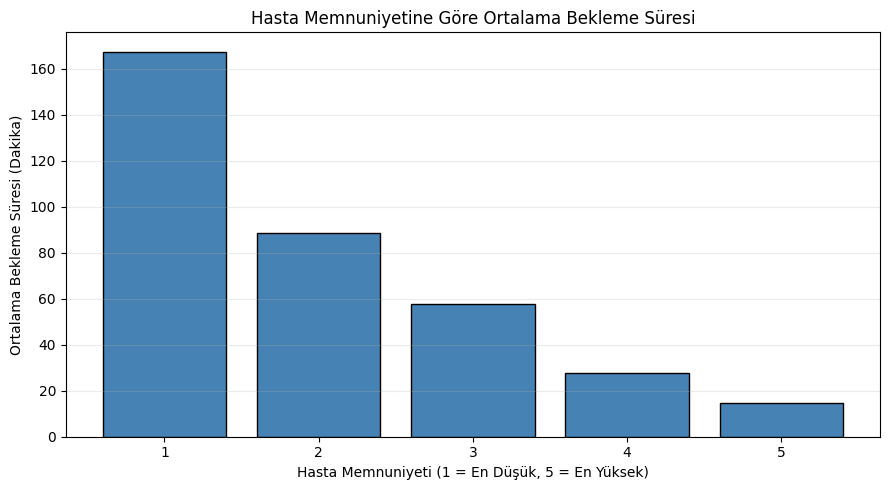

In [5]:

# HÜCRE 41A — HASTA MEMNUNİYETİ VE BEKLEME SÜRESİ GRAFİĞİ

import matplotlib.pyplot as plt

grafik_41a = ozet_41.sort_index()

plt.figure(figsize=(9, 5))

plt.bar(
    grafik_41a.index.astype(str),
    grafik_41a["Ortalama"],
    color="steelblue",
    edgecolor="black"
)

plt.title("Hasta Memnuniyetine Göre Ortalama Bekleme Süresi")
plt.xlabel("Hasta Memnuniyeti (1 = En Düşük, 5 = En Yüksek)")
plt.ylabel("Ortalama Bekleme Süresi (Dakika)")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


In [ ]:

# HÜCRE 42 — Spearman korelasyon analizi
from scipy.stats import spearmanr

veri_42 = df[
    ["Total Wait Time (min)", "Patient Satisfaction"]
].apply(pd.to_numeric, errors="coerce").dropna()

rho, p = spearmanr(
    veri_42["Total Wait Time (min)"],
    veri_42["Patient Satisfaction"]
)

print(f"Hasta sayısı: {len(veri_42)}")
print(f"Spearman rho: {rho:.4f}")
print(f"p değeri: {p:.6g}")
print(f"Sonuç: {'Anlamlı' if p < 0.05 else 'Anlamlı değil'}")


Hasta sayısı: 5000
Spearman rho: -0.9495
p değeri: 0
Sonuç: Anlamlı


In [ ]:

# HÜCRE 43 — ACİLİYET DÜZEYLERİNE GÖRE
# BEKLEME SÜRESİ VE HASTA MEMNUNİYETİ KORELASYONU

import pandas as pd
from scipy.stats import spearmanr

sutunlar = [
    "Aciliyet Düzeyi",
    "Toplam Bekleme Süresi (dk)",
    "Hasta Memnuniyeti"
]

veri_43 = df_tr[sutunlar].copy()

for sutun in sutunlar[1:]:
    veri_43[sutun] = pd.to_numeric(
        veri_43[sutun], errors="coerce"
    )

veri_43 = veri_43.dropna()

duzeyler = {
    "Critical": "Kritik",
    "High": "Yüksek",
    "Medium": "Orta",
    "Low": "Düşük"
}

sonuclar_43 = []

for kod, ad in duzeyler.items():
    grup = veri_43[veri_43["Aciliyet Düzeyi"] == kod]

    x = grup["Toplam Bekleme Süresi (dk)"]
    y = grup["Hasta Memnuniyeti"]

    if len(grup) < 3 or x.nunique() < 2 or y.nunique() < 2:
        rho, p = float("nan"), float("nan")
    else:
        rho, p = spearmanr(x, y)

    sonuclar_43.append({
        "Aciliyet Düzeyi": ad,
        "Hasta Sayısı": len(grup),
        "Spearman rho": round(rho, 4),
        "p Değeri": p
    })

tablo_43 = pd.DataFrame(sonuclar_43)

print("HÜCRE 43 — ACİLİYET DÜZEYLERİNE GÖRE KORELASYON")
display(tablo_43)


HÜCRE 43 — ACİLİYET DÜZEYLERİNE GÖRE KORELASYON


,Aciliyet Düzeyi,Hasta Sayısı,Spearman rho,p Değeri
0,Kritik,1242,-0.4727,3.925388e-70
1,Yüksek,1245,-0.7969,2.376715e-274
2,Orta,1291,-0.9104,0.000000e+00
3,Düşük,1222,-0.4776,1.213402e-70


In [ ]:

# HÜCRE 44 — ACİLİYET DÜZEYİ KONTROLLÜ KISMİ SPEARMAN

import pandas as pd
import numpy as np
from scipy.stats import pearsonr, t

sutunlar = [
    "Urgency Level",
    "Total Wait Time (min)",
    "Patient Satisfaction"
]

veri_44 = df[sutunlar].copy()

for sutun in sutunlar[1:]:
    veri_44[sutun] = pd.to_numeric(
        veri_44[sutun], errors="coerce"
    )

veri_44 = veri_44.dropna()

# Sayısal değişkenleri sıralara dönüştür
x = veri_44["Total Wait Time (min)"].rank().to_numpy()
y = veri_44["Patient Satisfaction"].rank().to_numpy()

# Aciliyet düzeyini kategorik olarak kontrol et
gruplar = pd.get_dummies(
    veri_44["Urgency Level"], drop_first=True
).astype(float)

X = np.column_stack([
    np.ones(len(veri_44)),
    gruplar.to_numpy()
])

# Aciliyet etkisi çıkarılmış sıralama artıkları
rx = x - X @ np.linalg.lstsq(X, x, rcond=None)[0]
ry = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]

rho, _ = pearsonr(rx, ry)

# Kontrol edilen değişkenlerin serbestlik derecesi
sd = len(veri_44) - np.linalg.matrix_rank(X) - 1
t_istatistigi = rho * np.sqrt(sd / (1 - rho**2))
p = 2 * t.sf(abs(t_istatistigi), df=sd)

tablo_44 = pd.DataFrame([{
    "Hasta Sayısı": len(veri_44),
    "Kısmi Spearman rho": round(rho, 4),
    "p Değeri": p,
    "Sonuç": "Anlamlı" if p < 0.05 else "Anlamlı değil"
}])

print("HÜCRE 44 — ACİLİYET KONTROLLÜ KORELASYON")
display(tablo_44)


HÜCRE 44 — ACİLİYET KONTROLLÜ KORELASYON


,Hasta Sayısı,Kısmi Spearman rho,p Değeri,Sonuç
0,5000,-0.7408,0.0,Anlamlı


## HÜCRE 41–44 — Bekleme Süresi ile Hasta Memnuniyeti Arasındaki İlişkinin Aciliyet Düzeyine Göre İncelenmesi

### 1. Analizin Amacı

Bu analiz grubunun amacı, acil servis hastalarının toplam bekleme süreleri ile memnuniyet puanları arasındaki ilişkinin yönünü, gücünü ve istatistiksel anlamlılığını değerlendirmektir.

Ayrıca genel veri setinde gözlenen ilişkinin aciliyet düzeyleri içerisinde nasıl değiştiği ve aciliyet düzeyi istatistiksel olarak kontrol edildiğinde devam edip etmediği araştırılmıştır.

### 2. İstatistiksel Yöntem

Toplam 5.000 hasta kaydı değerlendirilmiştir.

Analizler dört aşamada gerçekleştirilmiştir:

- **HÜCRE 41:** Memnuniyet puanlarına göre bekleme sürelerinin betimsel analizi.
- **HÜCRE 42:** Toplam bekleme süresi ile memnuniyet puanı arasındaki genel ilişkinin Spearman sıra korelasyonu ile incelenmesi.
- **HÜCRE 43:** Spearman korelasyonunun dört aciliyet düzeyinde ayrı ayrı hesaplanması.
- **HÜCRE 44:** Aciliyet düzeyi kategorik değişken olarak kontrol edilerek kısmi sıra korelasyonunun hesaplanması.

İstatistiksel anlamlılık düzeyi α = 0,05 olarak kabul edilmiştir.

### 3. HÜCRE 41 — Memnuniyet Puanlarına Göre Bekleme Süreleri

| Memnuniyet puanı | Hasta sayısı | Ortalama bekleme (dk) | Medyan (dk) | Standart sapma |
|---|---:|---:|---:|---:|
| 1 | 1.538 | 167,54 | 155 | 52,59 |
| 2 | 605 | 88,75 | 89 | 11,89 |
| 3 | 873 | 57,76 | 58 | 12,41 |
| 4 | 1.429 | 27,70 | 27 | 11,02 |
| 5 | 555 | 14,80 | 14 | 5,36 |

**Değerlendirme:**

Bekleme süreleri ile sayısal memnuniyet puanları arasında belirgin bir ters yönlü örüntü gözlenmiştir.

Memnuniyet puanı 1 olan hastalarda ortalama bekleme süresi 167,54 dakika iken puanı 5 olan hastalarda 14,80 dakikadır.

İki kategori arasında 152,74 dakikalık ortalama bekleme farkı bulunmaktadır.

 Veri kaynağındaki ölçek tanımına göre 1 en düşük, 5 en yüksek memnuniyet düzeyini göstermektedir. Bulgular, bekleme süresi uzadıkça hasta memnuniyetinin azalma eğiliminde olduğunu göstermektedir.

### 4. HÜCRE 42 — Genel Spearman Korelasyon Analizi

| İstatistik | Sonuç |
|---|---:|
| Hasta sayısı | 5.000 |
| Spearman korelasyon katsayısı (ρ) | −0,9495 |
| p değeri | <0,001 |
| İlişkinin yönü | Negatif |
| İlişkinin gücü | Çok güçlü |

**Değerlendirme:**

Spearman sıra korelasyon analizi sonucunda toplam bekleme süresi ile hasta memnuniyeti puanı arasında çok güçlü, negatif ve istatistiksel olarak anlamlı bir ilişki saptanmıştır (ρ = −0,9495; p < 0,001).

Bu bulgu, bekleme süresi arttıkça sayısal memnuniyet puanının azalma eğiliminde olduğunu göstermektedir.

Ancak genel korelasyon katsayısı, farklı aciliyet düzeylerindeki hastaların birlikte değerlendirilmesinden etkilenebilir.

Bu nedenle ilişkinin aciliyet grupları içerisinde ayrıca incelenmesi gerekli görülmüştür.

### 5. HÜCRE 43 — Aciliyet Düzeylerine Göre Spearman Korelasyonu

| Aciliyet düzeyi | Hasta sayısı | Spearman ρ | p değeri | İlişki gücü |
|---|---:|---:|---:|---|
| Kritik | 1.242 | −0,4727 | <0,001 | Orta |
| Yüksek | 1.245 | −0,7969 | <0,001 | Güçlü |
| Orta | 1.291 | −0,9104 | <0,001 | Çok güçlü |
| Düşük | 1.222 | −0,4776 | <0,001 | Orta |

**Değerlendirme:**

Dört aciliyet düzeyinin tamamında bekleme süresi ile memnuniyet puanı arasında istatistiksel olarak anlamlı negatif korelasyonlar belirlenmiştir.

En güçlü korelasyon orta aciliyet grubunda (ρ = −0,9104), en düşük mutlak korelasyon ise kritik aciliyet grubunda (ρ = −0,4727) görülmüştür.

Korelasyonun yönü bütün gruplarda aynı olmasına rağmen, ilişkinin gücü aciliyet düzeylerine göre farklılık göstermektedir.

Bu bulgu, genel veri setinde elde edilen yüksek korelasyonun bütün hasta gruplarını aynı güçte temsil etmediğini ortaya koymaktadır.

Gruplar arasında gözlenen korelasyon farklılıklarının istatistiksel anlamlılığı bu aşamada ayrıca test edilmemiştir.

### 6. HÜCRE 44 — Aciliyet Düzeyi Kontrollü Kısmi Spearman Korelasyonu

| Analiz | Korelasyon katsayısı |
|---|---:|
| Genel Spearman (HÜCRE 42) | −0,9495 |
| Aciliyet kontrollü kısmi sıra korelasyonu (HÜCRE 44) | Yaklaşık −0,74 |

HÜCRE 44 sonucunda aciliyet düzeyi kontrol edildiğinde bekleme süresi ile memnuniyet puanı arasındaki ilişkinin negatif yönde ve istatistiksel olarak anlamlı biçimde devam ettiği görülmüştür (yaklaşık ρ = −0,74; p < 0,001).

Ancak korelasyon katsayısının mutlak büyüklüğü genel analizdeki 0,9495 değerinden yaklaşık 0,74'e gerilemiştir.

**Değerlendirme:**

Bu azalma, genel veri setinde gözlenen ilişkinin bir bölümünün aciliyet düzeyleri arasındaki farklılıklarla bağlantılı olabileceğini düşündürmektedir.

Buna karşılık, aciliyet düzeyi kontrol edildikten sonra ilişkinin güçlü biçimde devam etmesi, bekleme süresi ile memnuniyet puanı arasındaki ters yönlü ilişkinin yalnızca aciliyet kategorileri arasındaki farklılıklardan kaynaklanmadığına işaret etmektedir.

Bu analizde kısmi sıra korelasyonu, değişkenlerin genel sıraları üzerinden aciliyet kategorilerine ait etkilerin doğrusal olarak çıkarılması yoluyla hesaplanmıştır. İstatistiksel anlamlılık için yaklaşık parametrik test kullanılmıştır.

### 7. Genel Bulguların Karşılaştırmalı Değerlendirilmesi

HÜCRE 41–44 kapsamında yapılan analizler birlikte değerlendirildiğinde aşağıdaki sonuçlara ulaşılmıştır:

1. Memnuniyet puanları yükseldikçe ortalama bekleme sürelerinin düzenli biçimde azaldığı görülmüştür.
2. Genel Spearman korelasyonu çok güçlü ve negatif bulunmuştur.
3. Aciliyet düzeyleri ayrı ayrı incelendiğinde negatif ilişki bütün gruplarda devam etmiş, ancak ilişkinin gücü farklılaşmıştır.
4. Aciliyet düzeyi kontrol edildiğinde korelasyonun mutlak büyüklüğü azalmış, buna rağmen güçlü ve istatistiksel olarak anlamlı ilişki korunmuştur.

Bu sonuçlar, bekleme süresi ile memnuniyet puanı arasındaki ilişkinin değerlendirilmesinde aciliyet düzeyinin dikkate alınması gerektiğini desteklemektedir.

### 8. Metodolojik Sınırlılıklar

**Memnuniyet ölçeğinin yönü:** Veri setinde 1–5 arasında kodlanan memnuniyet puanlarının özgün tanımı henüz kesin olarak doğrulanmamıştır. Bu nedenle puanların klinik memnuniyet düzeyini nasıl temsil ettiği açıklığa kavuşturulmalıdır.

**Nedensellik:** Korelasyon analizleri nedensellik kanıtı sağlamaz. Bekleme süresi ile memnuniyet puanı arasındaki ilişki, bekleme süresinin doğrudan memnuniyeti değiştirdiği şeklinde yorumlanamaz.

**Karıştırıcı değişkenler:** Aciliyet düzeyi kontrol edilmiş olmakla birlikte hasta sonucu, hastane özellikleri ve diğer olası karıştırıcı değişkenlerin etkileri bu analiz grubunda birlikte değerlendirilmemiştir.

**Kısmi korelasyon yöntemi:** HÜCRE 44'te kullanılan yaklaşım yaklaşık bir istatistiksel yöntemdir. Özellikle sıralı kategorik memnuniyet değişkeni ve bağlı sıra değerleri dikkate alındığında, ileri analizlerde uygun alternatif modellerle duyarlılık kontrolü yapılabilir.

**Veri üretim süreci:** Değişkenlerin nasıl ölçüldüğü veya üretildiği, özellikle bekleme süresi ile memnuniyet puanının birbirine bağlı biçimde oluşturulup oluşturulmadığı, veri kaynağının metodolojik açıklaması üzerinden incelenmelidir.

### 9. Sonuç

HÜCRE 41–44 kapsamında gerçekleştirilen betimsel, ilişkisel ve kontrol değişkenli analizler, toplam bekleme süresi ile sayısal hasta memnuniyeti puanı arasında güçlü ve negatif yönlü bir ilişki bulunduğunu göstermiştir.

Genel analizde belirlenen çok güçlü ilişkinin aciliyet düzeyi kontrol edildiğinde zayıflaması, aciliyet farklılıklarının genel korelasyonun yorumlanmasında önemli olabileceğine işaret etmektedir.

Bununla birlikte, negatif ilişkinin kontrol sonrasında da devam etmesi, bekleme süresi ile memnuniyet puanı arasındaki ilişkinin aciliyet düzeyinden bağımsız bileşenler içerebileceğini düşündürmektedir.

Bu bulgular ilişkisel niteliktedir ve doğrudan nedensel sonuç olarak değerlendirilmemelidir. Hasta memnuniyetinin klinik yorumuna geçilmeden önce ölçeğin yönü ve veri üretim süreci doğrulanmalıdır.

In [ ]:

# HÜCRE 45 — HASTA SONUCUNA GÖRE DUYARLILIK ANALİZİ

import pandas as pd
from scipy.stats import spearmanr

veri_45 = df[
    ["Patient Outcome", "Total Wait Time (min)",
     "Patient Satisfaction"]
].copy()

for sutun in ["Total Wait Time (min)", "Patient Satisfaction"]:
    veri_45[sutun] = pd.to_numeric(
        veri_45[sutun], errors="coerce"
    )

veri_45 = veri_45.dropna()

# Muayene olmadan ayrılan hastaları dışla
veri_45_filtreli = veri_45[
    veri_45["Patient Outcome"] != "Left Without Being Seen"
]

sonuclar = []

for ad, grup in [
    ("Tüm hastalar", veri_45),
    ("Muayene olmadan ayrılanlar hariç", veri_45_filtreli)
]:
    rho, p = spearmanr(
        grup["Total Wait Time (min)"],
        grup["Patient Satisfaction"]
    )

    sonuclar.append({
        "Hasta Grubu": ad,
        "Hasta Sayısı": len(grup),
        "Spearman rho": round(rho, 4),
        "p Değeri": p
    })

tablo_45 = pd.DataFrame(sonuclar)

print("HÜCRE 45 — DUYARLILIK ANALİZİ")
display(tablo_45)

print(
    "\nÇıkarılan hasta sayısı:",
    len(veri_45) - len(veri_45_filtreli)
)


HÜCRE 45 — DUYARLILIK ANALİZİ


,Hasta Grubu,Hasta Sayısı,Spearman rho,p Değeri
0,Tüm hastalar,5000,-0.9495,0.0
1,Muayene olmadan ayrılanlar hariç,4747,-0.9485,0.0



Çıkarılan hasta sayısı: 253


## HÜCRE 45 — Muayene Olmadan Ayrılan Hastalar Hariç Tutulduğunda Bekleme Süresi ve Hasta Memnuniyeti İlişkisinin Duyarlılık Analizi

### Amaç

Muayene olmadan ayrılan hastaların, toplam bekleme süresi ile hasta memnuniyeti puanı arasındaki korelasyon üzerindeki etkisini değerlendirmek ve önceki bulguların bu hasta grubu dışlandığında ne ölçüde korunduğunu incelemek.

### Yöntem

Toplam 5.000 hasta kaydı üzerinden hesaplanan Spearman sıra korelasyonu, muayene olmadan ayrılan 253 hasta veri setinden çıkarıldıktan sonra yeniden hesaplanmıştır.

İki analizden elde edilen korelasyon katsayıları karşılaştırılmıştır.

### Bulgular

| Hasta grubu | Hasta sayısı | Spearman (ρ) | p değeri |
|---|---:|---:|---:|
| Tüm hastalar | 5.000 | −0,9495 | <0,001 |
| Muayene olmadan ayrılanlar hariç | 4.747 | −0,9485 | <0,001 |

Analiz dışında bırakılan hasta sayısı 253 olup toplam hasta kayıtlarının %5,06'sını oluşturmaktadır.

### Bulguların Değerlendirilmesi

Muayene olmadan ayrılan hastaların analiz dışında bırakılması sonucunda Spearman korelasyon katsayısı −0,9495'ten −0,9485'e değişmiştir.

Korelasyon katsayısının mutlak büyüklüğündeki azalma yalnızca 0,0010 düzeyindedir.

Her iki analizde de bekleme süresi ile sayısal hasta memnuniyeti puanı arasında çok güçlü, negatif ve istatistiksel olarak anlamlı bir ilişki belirlenmiştir.

Bu sonuç, genel veri setinde gözlenen güçlü negatif ilişkinin yalnızca muayene olmadan ayrılan hastaların varlığına bağlı olmadığını göstermektedir.

### İstatistiksel Değerlendirme

Duyarlılık analizi, incelenen hasta grubunun çıkarılmasının korelasyon katsayısında ihmal edilebilir düzeyde bir değişiklik oluşturduğunu göstermiştir.

Bununla birlikte, bu bulgu ilişkinin nedensel olduğunu kanıtlamamaktadır. Ayrıca söz konusu analiz, aciliyet düzeyi kontrollü kısmi korelasyondan farklıdır.

Hasta memnuniyeti ölçeğinin yönü henüz özgün veri kaynağından doğrulanmadığı için sonuçlar sayısal puanlar üzerinden yorumlanmıştır.

### Sonuç

HÜCRE 45 kapsamında gerçekleştirilen duyarlılık analizi, muayene olmadan ayrılan 253 hasta hariç tutulduğunda bekleme süresi ile hasta memnuniyeti puanı arasındaki çok güçlü negatif ilişkinin korunduğunu ortaya koymuştur.

Bu bulgu, HÜCRE 42'de elde edilen genel korelasyon sonucunun incelenen hasta grubu dışlandığında da büyük ölçüde değişmediğini göstermektedir.

Sonuçlar ilişkisel niteliktedir ve nedensellik çıkarımı için yeterli değildir.

## VERİ SETİNİN OLUŞTURULMA YÖNTEMİ VE METODOLOJİK SINIRLILIKLAR

### Veri Setinin Kaynağı ve Niteliği

Bu çalışmada kullanılan *Emergency Room Wait Time Dataset*, Kaggle platformunda eğitim ve veri analizi uygulamaları amacıyla yayımlanmış, 2024 yılına ait 5.000 simüle edilmiş acil servis hasta ziyaretinden oluşmaktadır.

Veri seti, Python programlama dili kullanılarak oluşturulmuş ve 19 değişken içermektedir.

### Veri Üretim Yöntemi

Veri setinin açıklamasına göre üretim sürecinde aciliyet düzeyi, bekleme süresi, hasta memnuniyeti, hemşire-hasta oranı ve zamanla ilişkili değişkenler arasında sağlık hizmetleri alanındaki bilgilerden yararlanılarak mantıksal ilişkiler tasarlanmıştır.

Gerçekçi değişkenlik oluşturmak amacıyla rastgelelik de eklenmiştir. Veri setinin tasarımında ChatGPT'den de yararlanıldığı belirtilmiştir.

Bununla birlikte, hasta memnuniyeti puanlarının hangi matematiksel formül veya algoritmayla hesaplandığı kaynak açıklamasında ayrıntılı olarak verilmemiştir.

### Bulguların Yorumlanmasına Etkisi

HÜCRE 42'de toplam bekleme süresi ile hasta memnuniyeti arasında çok güçlü negatif ilişki bulunmuştur (Spearman ρ = −0,9495; p < 0,001).

Veri üretiminde değişkenler arasında önceden tanımlanan ilişkiler kullanılmış olması, elde edilen korelasyonun büyüklüğünü etkilemiş olabilir.

Ancak özgün veri üretim kodu incelenmeden, korelasyonun hangi kurallardan ne ölçüde kaynaklandığı kesin olarak belirlenemez.

### Metodolojik Sınırlılıklar

- Veriler gerçek hastalardan toplanmamış, simülasyon yoluyla üretilmiştir.
- Analiz sonuçları doğrudan gerçek hastane popülasyonlarına genellenemez.
- Değişkenler arasındaki ilişkiler, veri üretim sürecindeki varsayımlardan etkilenmiş olabilir.
- Korelasyon sonuçları nedensellik kanıtı olarak yorumlanmamalıdır.

### Sonuç

Bu çalışma kapsamında gerçekleştirilen istatistiksel analizler, simüle edilmiş acil servis verilerindeki ilişkilerin belirlenmesi ve veri analizi yöntemlerinin uygulanması açısından değerlidir.

Bununla birlikte, bulgular gerçek klinik sonuçlar olarak değil, eğitim amaçlı simülasyon verileri üzerinden elde edilen istatistiksel sonuçlar olarak değerlendirilmelidir.

**Kaynak:** *Emergency Room Wait Time Dataset — ER Wait Time Data Overview*, Kaggle veri seti açıklaması.

In [ ]:

# HÜCRE 46 — ÇOK DEĞİŞKENLİ BEKLEME SÜRESİ ANALİZİ

import pandas as pd
import statsmodels.formula.api as smf

sutunlar = [
    "Toplam Bekleme Süresi (dk)",
    "Aciliyet Düzeyi",
    "Hastane Adı",
    "Hemşire Hasta Oranı",
    "Uzman Hekim Mevcudiyeti",
    "Hastane Yatak Kapasitesi"
]

veri_46 = df_tr[sutunlar].copy()

sayisal = [
    "Toplam Bekleme Süresi (dk)",
    "Hemşire Hasta Oranı",
    "Uzman Hekim Mevcudiyeti",
    "Hastane Yatak Kapasitesi"
]

veri_46[sayisal] = veri_46[sayisal].apply(
    pd.to_numeric, errors="coerce"
)

veri_46 = veri_46.dropna()

formul = (
    'Q("Toplam Bekleme Süresi (dk)") ~ '
    'C(Q("Aciliyet Düzeyi")) + '
    'C(Q("Hastane Adı")) + '
    'Q("Hemşire Hasta Oranı") + '
    'Q("Uzman Hekim Mevcudiyeti") + '
    'Q("Hastane Yatak Kapasitesi")'
)

model_46 = smf.ols(
    formul, data=veri_46
).fit(cov_type="HC3")

guven = model_46.conf_int()

tablo_46 = pd.DataFrame({
    "Değişken": model_46.params.index,
    "Katsayı": model_46.params.values,
    "Alt %95 GA": guven.iloc[:, 0].values,
    "Üst %95 GA": guven.iloc[:, 1].values,
    "p Değeri": model_46.pvalues.values
})

print("HÜCRE 46 — ÇOK DEĞİŞKENLİ REGRESYON")
print("Hasta sayısı:", len(veri_46))
print("R-kare:", round(model_46.rsquared, 4))
print("Düzeltilmiş R-kare:", round(model_46.rsquared_adj, 4))

display(tablo_46.round(4))


HÜCRE 46 — ÇOK DEĞİŞKENLİ REGRESYON
Hasta sayısı: 5000
R-kare: 0.75
Düzeltilmiş R-kare: 0.7495


,Değişken,Katsayı,Alt %95 GA,Üst %95 GA,p Değeri
0,Intercept,9.0475,5.5234,12.5716,0.0000
1,"C(Q(""Aciliyet Düzeyi""))[T.High]",11.5712,7.6672,15.4752,0.0000
2,"C(Q(""Aciliyet Düzeyi""))[T.Low]",135.1428,128.4556,141.8299,0.0000
3,"C(Q(""Aciliyet Düzeyi""))[T.Medium]",62.3120,58.2385,66.3854,0.0000
4,"C(Q(""Hastane Adı""))[T.Riverside Medical Center]",0.7181,-3.6571,5.0932,0.7477
5,"C(Q(""Hastane Adı""))[T.Springfield General Hosp...",0.1998,-4.1875,4.5870,0.9289
6,"C(Q(""Hastane Adı""))[T.St. Mary’s Regional Health]",-1.5698,-4.6467,1.5070,0.3173
7,"C(Q(""Hastane Adı""))[T.Summit Health Center]",1.5632,-2.8841,6.0105,0.4909
8,"Q(""Hemşire Hasta Oranı"")",6.6173,4.7171,8.5175,0.0000
9,"Q(""Uzman Hekim Mevcudiyeti"")",-0.0337,-0.4281,0.3608,0.8672


HÜCRE 47 — REGRESYON VARSAYIM TESTLERİ


,Test,Test İstatistiği,p Değeri
0,Jarque-Bera,8223.512555,0.000000e+00
1,Breusch-Pagan,763.902461,1.183229e-157



ÇOKLU DOĞRUSAL BAĞLANTI — VIF


,Değişken,VIF
2,"C(Q(""Aciliyet Düzeyi""))[T.Low]",8.309
8,"Q(""Hemşire Hasta Oranı"")",5.781
3,"C(Q(""Aciliyet Düzeyi""))[T.Medium]",4.520
1,"C(Q(""Aciliyet Düzeyi""))[T.High]",4.517
4,"C(Q(""Hastane Adı""))[T.Riverside Medical Center]",3.248
7,"C(Q(""Hastane Adı""))[T.Summit Health Center]",3.208
5,"C(Q(""Hastane Adı""))[T.Springfield General Hosp...",3.202
10,"Q(""Hastane Yatak Kapasitesi"")",2.757
9,"Q(""Uzman Hekim Mevcudiyeti"")",1.663
6,"C(Q(""Hastane Adı""))[T.St. Mary’s Regional Health]",1.600


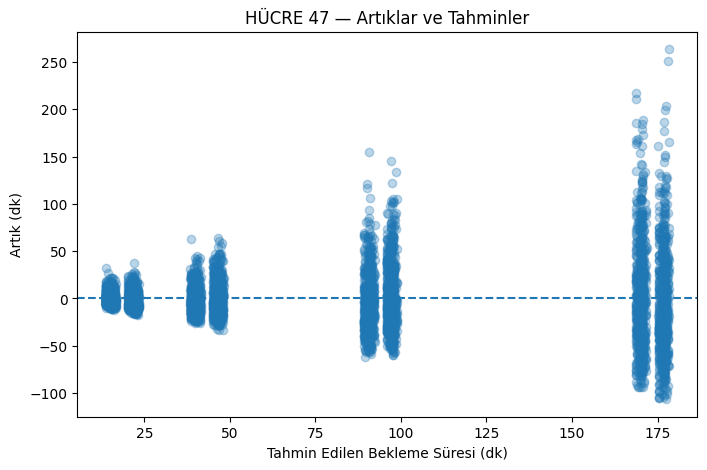

In [ ]:

# HÜCRE 47 — REGRESYON VARSAYIM KONTROLLERİ

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# HÜCRE 46'da oluşturulan model
model = model_46

artiklar = model.resid
tahminler = model.fittedvalues
X = model.model.exog
adlar = model.model.exog_names

# 1. Artıkların normal dağılımı
jb = jarque_bera(artiklar)

# 2. Değişen varyans: Breusch-Pagan
bp = het_breuschpagan(artiklar, X)

tablo_47 = pd.DataFrame({
    "Test": ["Jarque-Bera", "Breusch-Pagan"],
    "Test İstatistiği": [jb.statistic, bp[0]],
    "p Değeri": [jb.pvalue, bp[1]]
})

print("HÜCRE 47 — REGRESYON VARSAYIM TESTLERİ")
display(tablo_47)

# 3. Çoklu doğrusal bağlantı (VIF)
vif_47 = pd.DataFrame({
    "Değişken": adlar,
    "VIF": [
        variance_inflation_factor(X, i)
        for i in range(X.shape[1])
    ]
})

vif_47 = vif_47[
    vif_47["Değişken"] != "Intercept"
].sort_values("VIF", ascending=False)

print("\nÇOKLU DOĞRUSAL BAĞLANTI — VIF")
display(vif_47.round(3))

# 4. Artıklar ve tahmin edilen değerler
plt.figure(figsize=(8, 5))
plt.scatter(tahminler, artiklar, alpha=0.3)
plt.axhline(0, linestyle="--")
plt.xlabel("Tahmin Edilen Bekleme Süresi (dk)")
plt.ylabel("Artık (dk)")
plt.title("HÜCRE 47 — Artıklar ve Tahminler")
plt.show()


## HÜCRE 46–47 — Acil Servis Bekleme Süresinin Çok Değişkenli Regresyon Analizi ve Model Varsayımlarının Değerlendirilmesi

### 1. Analizin Amacı

Bu analiz grubunun amacı, acil servis hastalarının toplam bekleme süreleri ile ilişkili faktörleri çok değişkenli bir istatistiksel model aracılığıyla incelemek ve kurulan regresyon modelinin temel varsayımlarını değerlendirmektir.

Bu kapsamda aciliyet düzeyi, hastane, hemşire-hasta oranı, uzman hekim mevcudiyeti ve yatak kapasitesi birlikte ele alınmıştır.

### 2. İstatistiksel Yöntem

Toplam 5.000 simüle edilmiş hasta kaydı kullanılmıştır.

**HÜCRE 46:** Toplam bekleme süresinin bağımlı değişken olduğu çoklu doğrusal regresyon (OLS) modeli oluşturulmuştur.

Bağımsız değişkenler:

- Aciliyet düzeyi
- Hastane adı
- Hemşire-hasta oranı
- Uzman hekim mevcudiyeti
- Hastane yatak kapasitesi

Aciliyet düzeyi ve hastane adı kategorik değişkenler olarak modele dahil edilmiştir. Değişen varyansa karşı daha dayanıklı istatistiksel çıkarım sağlamak amacıyla HC3 sağlam standart hataları kullanılmıştır.

**HÜCRE 47:** Modelin varsayımları Jarque–Bera testi, Breusch–Pagan testi, varyans şişirme faktörü (VIF) ve artık-tahmin grafiği aracılığıyla değerlendirilmiştir.

İstatistiksel anlamlılık düzeyi α = 0,05 olarak kabul edilmiştir.

---

### 3. HÜCRE 46 — Çok Değişkenli Regresyon Bulguları

#### 3.1. Modelin Açıklama Gücü

| Gösterge | Değer |
|---|---:|
| Hasta sayısı | 5.000 |
| R-kare (R²) | 0,7500 |
| Düzeltilmiş R-kare | 0,7495 |

Regresyon modeli, toplam bekleme süresindeki gözlenen değişkenliğin yaklaşık %75'ini açıklamaktadır.

Düzeltilmiş R-kare değerinin R-kare değerine oldukça yakın olması, model karmaşıklığına ilişkin düzeltmenin açıklama gücünü sınırlı ölçüde değiştirdiğini göstermektedir.

Bununla birlikte, yüksek açıklama gücü modelin bütün istatistiksel varsayımlarının sağlandığı veya farklı veri setlerinde aynı başarının elde edileceği anlamına gelmemektedir.

#### 3.2. Regresyon Katsayıları

| Değişken | Katsayı | %95 güven aralığı | p değeri |
|---|---:|---|---:|
| Sabit terim | 9,0475 | [5,5234; 12,5716] | <0,001 |
| Yüksek aciliyet | 11,5712 | [7,6672; 15,4752] | <0,001 |
| Orta aciliyet | 62,3120 | [58,2385; 66,3854] | <0,001 |
| Düşük aciliyet | 135,1428 | [128,4556; 141,8299] | <0,001 |
| Riverside Medical Center | 0,7181 | [−3,6571; 5,0932] | 0,7477 |
| Springfield General Hospital | 0,1998 | [−4,1875; 4,5870] | 0,9289 |
| St. Mary’s Regional Health | −1,5698 | [−4,6467; 1,5070] | 0,3173 |
| Summit Health Center | 1,5632 | [−2,8841; 6,0105] | 0,4909 |
| Hemşire-hasta oranı | 6,6173 | [4,7171; 8,5175] | <0,001 |
| Uzman hekim mevcudiyeti | −0,0337 | [−0,4281; 0,3608] | 0,8672 |
| Hastane yatak kapasitesi | −0,0070 | [−0,0341; 0,0201] | 0,6122 |

**Not:** Kategorik değişkenlerin katsayıları ilgili referans kategorilerine göre yorumlanmıştır. Aciliyet düzeyinde referans kategori kritik aciliyettir.

#### 3.3. Bulguların Değerlendirilmesi

**Aciliyet düzeyi**

Diğer bağımsız değişkenler sabit tutulduğunda, kritik aciliyet grubuna kıyasla yüksek aciliyette 11,57 dakika, orta aciliyette 62,31 dakika ve düşük aciliyette 135,14 dakika daha uzun toplam bekleme süresi tahmin edilmektedir.

Üç katsayının tamamı istatistiksel olarak anlamlıdır (p < 0,001).

Bu bulgular, aciliyet düzeyinin toplam bekleme süresiyle güçlü biçimde ilişkili olduğunu ve aciliyet temelli önceliklendirme yapısının model sonuçlarında belirgin şekilde gözlendiğini göstermektedir.

**Hemşire-hasta oranı**

Hemşire-hasta oranının regresyon katsayısı 6,6173 olarak hesaplanmıştır (p < 0,001).

Diğer değişkenler sabitken bu değişkendeki bir birimlik artış, yaklaşık 6,62 dakika daha uzun bekleme süresiyle ilişkilidir.

Bu bulgu, personel yükünü temsil eden değişken ile bekleme süresi arasında pozitif yönlü bir ilişki bulunduğunu göstermektedir. Bununla birlikte, değişkenin operasyonel yorumu veri setindeki kodlama biçimine bağlıdır ve nedensel etki olarak değerlendirilmemelidir.

**Hastane farklılıkları**

Modeldeki hastane göstergelerinin hiçbirinde referans hastaneye kıyasla istatistiksel olarak anlamlı bir katsayı belirlenmemiştir (p > 0,05).

Ancak katsayıların tek tek anlamlı olmaması, hastane değişkeninin bütün olarak etkisiz olduğunu kanıtlamamaktadır. Hastane göstergelerinin ortak anlamlılığı ayrıca test edilmemiştir.

**Uzman hekim mevcudiyeti ve yatak kapasitesi**

Uzman hekim mevcudiyeti (p = 0,8672) ve hastane yatak kapasitesi (p = 0,6122) değişkenleri için mevcut modelde istatistiksel olarak anlamlı bağımsız doğrusal ilişkiler saptanmamıştır.

Bu sonuç, söz konusu faktörlerin tüm koşullarda önemsiz olduğu anlamına gelmemektedir.

---

### 4. HÜCRE 47 — Regresyon Varsayımlarının İncelenmesi

#### 4.1. Normal Dağılım ve Değişen Varyans Testleri

| Test | Test istatistiği | p değeri |
|---|---:|---:|
| Jarque–Bera | 8.223,5126 | <0,001 |
| Breusch–Pagan | 763,9025 | <0,001 |

**Jarque–Bera testi**

Jarque–Bera testi sonucunda regresyon artıklarının normal dağılıma uygun olduğu yönündeki sıfır hipotezi reddedilmiştir.

Bu bulgu, model artıklarının normal dağılımdan istatistiksel olarak anlamlı biçimde saptığını göstermektedir.

Artıkların normal dağılmaması OLS katsayılarını tek başına geçersiz kılmamakla birlikte, klasik parametrik çıkarım varsayımlarının değerlendirilmesini gerekli kılmaktadır.

**Breusch–Pagan testi**

Breusch–Pagan testi sonucunda sabit hata varyansı varsayımına karşı güçlü istatistiksel kanıt elde edilmiştir.

Dolayısıyla modelde heteroskedastisite, diğer bir ifadeyle değişen hata varyansı bulunduğu değerlendirilmiştir.

HÜCRE 46'da HC3 sağlam standart hatalarının kullanılması, değişen varyans koşullarında katsayılara ilişkin istatistiksel çıkarım açısından önemli bir önlemdir.

Ancak HC3 yaklaşımı, modelin fonksiyonel biçimindeki olası sorunları, değişkenler arasındaki doğrusal bağlantıyı veya diğer model sınırlılıklarını ortadan kaldırmamaktadır.

#### 4.2. Çoklu Doğrusal Bağlantı — VIF Analizi

| Değişken | VIF |
|---|---:|
| Düşük aciliyet | 8,309 |
| Hemşire-hasta oranı | 5,781 |
| Orta aciliyet | 4,520 |
| Yüksek aciliyet | 4,517 |
| Riverside Medical Center | 3,248 |
| Summit Health Center | 3,208 |
| Springfield General Hospital | 3,202 |
| Hastane yatak kapasitesi | 2,757 |
| Uzman hekim mevcudiyeti | 1,663 |
| St. Mary’s Regional Health | 1,600 |

En yüksek VIF değeri düşük aciliyet göstergesinde (8,309), ikinci en yüksek değer hemşire-hasta oranında (5,781) görülmüştür.

Bu bulgular, bazı açıklayıcı değişkenlerin diğer model değişkenleriyle önemli düzeyde doğrusal bağlantıya sahip olabileceğini düşündürmektedir.

Bununla birlikte, VIF için kullanılan 5 ve 10 eşikleri kesin karar sınırları değildir. Özellikle çok kategorili değişkenlerin gösterge sütunlarına ait VIF değerlerinin, modeldeki referans kategori ve kodlama yapısı dikkate alınarak yorumlanması gerekmektedir.

Dolayısıyla mevcut VIF sonuçları modelde dikkat gerektiren bağlantılar bulunduğunu göstermekte, ancak tek başına modelin geçersiz olduğunu kanıtlamamaktadır.

#### 4.3. Artıklar ve Tahmin Edilen Değerler Grafiği

Artık-tahmin grafiği incelendiğinde tahmin edilen bekleme sürelerinin belirli aralıklarda kümelendiği görülmektedir.

Düşük tahmini bekleme sürelerinde artıkların dağılımı görece dar bir aralıkta bulunurken, yüksek tahmini bekleme sürelerinde artıkların yayılımı belirgin biçimde artmaktadır.

Ayrıca yüksek bekleme sürelerinde büyük pozitif artık değerleri gözlenmektedir.

Bu görünüm, Breusch–Pagan testinde belirlenen heteroskedastisite bulgusuyla uyumludur.

Tahminlerin belirli aralıklarda kümelenmesi, aciliyet düzeyleri ve diğer kategorik özelliklerle ilişkili olabilir. Ancak bu olasılık, mevcut grafik üzerinden kesin olarak doğrulanamamaktadır.

---

### 5. HÜCRE 46–47 — Karşılaştırmalı Değerlendirme

Çok değişkenli regresyon ve model varsayım analizleri birlikte değerlendirildiğinde aşağıdaki sonuçlara ulaşılmıştır:

1. Regresyon modeli toplam bekleme süresindeki gözlenen değişkenliğin yaklaşık %75'ini açıklamaktadır.
2. Aciliyet düzeyi ve hemşire-hasta oranı, diğer model değişkenleri kontrol edildiğinde istatistiksel olarak anlamlı ilişkiler göstermektedir.
3. Hastane göstergelerinin tek tek katsayıları, uzman hekim mevcudiyeti ve yatak kapasitesi mevcut modelde istatistiksel olarak anlamlı bulunmamıştır.
4. Jarque–Bera testi, artıkların normal dağılımdan anlamlı biçimde saptığını göstermiştir.
5. Breusch–Pagan testi ve artık grafiği, modelde değişen hata varyansı bulunduğunu desteklemektedir.
6. VIF analizi, özellikle düşük aciliyet göstergesi ve hemşire-hasta oranı için dikkat gerektiren doğrusal bağlantılar bulunduğuna işaret etmektedir.

Bu bulgular, modelin veri seti içerisindeki açıklama gücünün yüksek olduğunu, ancak istatistiksel varsayımlar ve model yapısı açısından sınırlılıklar taşıdığını göstermektedir.

### 6. Metodolojik Sınırlılıklar

**Simüle edilmiş veri:** Çalışmada kullanılan hasta kayıtları gerçek klinik gözlemlerden değil, Python aracılığıyla oluşturulmuş simülasyon verilerinden elde edilmiştir. Bu nedenle bulgular gerçek hastane popülasyonlarına doğrudan genellenemez.

**Veri üretim kuralları:** Aciliyet düzeyi, personel kapasitesi ve bekleme süresi arasındaki ilişkiler veri üretim sürecindeki varsayımlardan etkilenmiş olabilir.

**Regresyon varsayımları:** Artıkların normal dağılımdan sapması ve değişen varyansın varlığı, modelin istatistiksel özelliklerinin dikkatle değerlendirilmesini gerektirmektedir.

**Gözlemlerin bağımsızlığı:** Veri seti beş farklı hastaneye ait simüle edilmiş hasta kayıtlarından oluşmaktadır. Aynı hastaneye ait gözlemler arasında benzerlik veya bağımlılık bulunma olasılığı dikkate alınmalıdır. Mevcut analizde gözlemlerin bağımsızlığı ve hastane düzeyindeki olası kümelenme ayrıca test edilmemiştir. Kullanılan HC3 sağlam standart hataları heteroskedastisiteye karşı dayanıklılık sağlamakla birlikte, hastane düzeyindeki olası bağımlılığı tek başına gidermemektedir. Bu nedenle istatistiksel çıkarımlar söz konusu sınırlılık çerçevesinde değerlendirilmelidir.

**Çoklu doğrusal bağlantı:** Bazı bağımsız değişkenler arasında bağlantılar bulunması, regresyon katsayılarının hassasiyetini etkileyebilir.

**Modelin kapsamı:** Mevcut regresyon doğrusal ve toplamsal bir yapıya sahiptir. Olası etkileşimler ve doğrusal olmayan ilişkiler bu analizde ayrıca modellenmemiştir.

**Nedensellik:** Regresyon katsayıları değişkenler arasındaki koşullu ilişkileri göstermektedir. Bulgular, herhangi bir faktörün bekleme süresini doğrudan değiştirdiğine ilişkin nedensel kanıt sunmamaktadır.


### 7. Genel Sonuç

HÜCRE 46 ve HÜCRE 47 kapsamında gerçekleştirilen analizler, acil servis toplam bekleme süresinin aciliyet düzeyi ve hemşire-hasta oranıyla istatistiksel olarak anlamlı biçimde ilişkili olduğunu ortaya koymuştur.

Çok değişkenli regresyon modelinin açıklama gücü yüksek olmakla birlikte, varsayım testlerinde normal dağılımdan sapma, heteroskedastisite ve bazı açıklayıcı değişkenlerde dikkat gerektiren doğrusal bağlantılar belirlenmiştir.

Bu nedenle mevcut model, simüle edilmiş acil servis verilerindeki ilişkilerin incelenmesi açısından yararlı olmakla birlikte, istatistiksel çıkarımlarının ve farklı veri setlerine uygulanabilirliğinin dikkatle değerlendirilmesi gerekmektedir.

**Sonuç olarak**, aciliyet düzeyi ve personel yükü, bekleme süreleriyle ilişkili temel değişkenler olarak öne çıkmaktadır. Ancak mevcut bulgular, doğrudan nedensel veya gerçek klinik ortamlara genellenebilir sonuçlar olarak değerlendirilmemelidir.

İleri analizlerde modelin fonksiyonel biçiminin, olası etkileşimlerin ve model performansının ayrıca incelenmesi önerilmektedir.

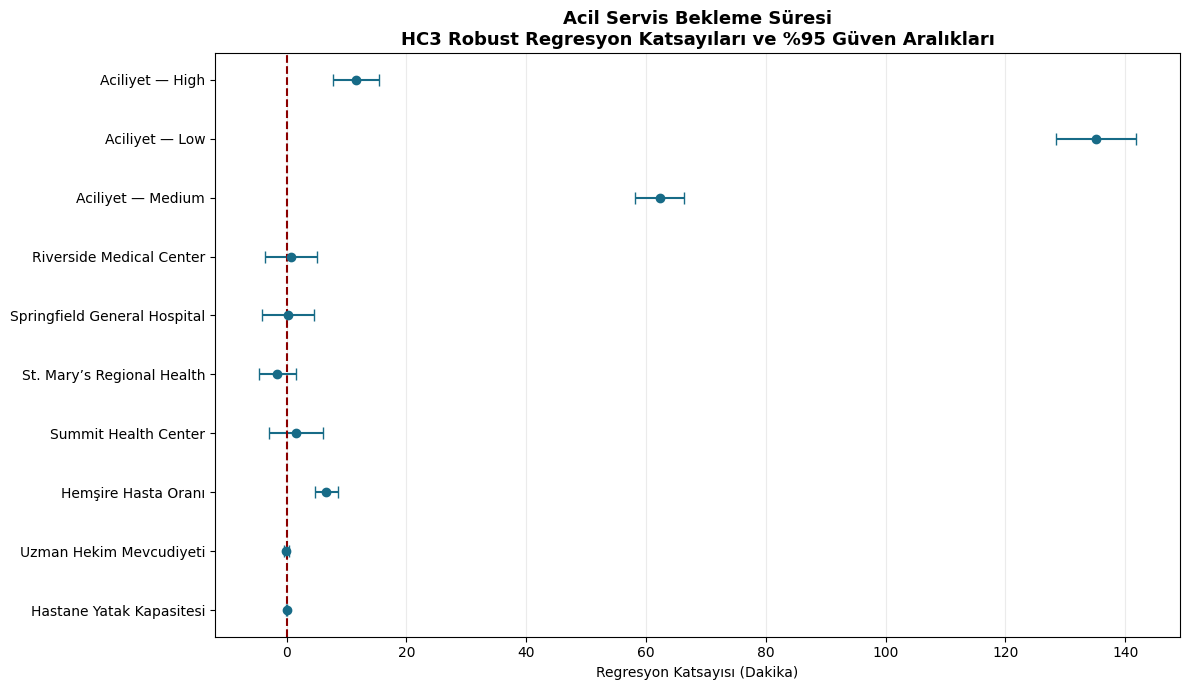

In [3]:

# HÜCRE 48 — REGRESYON KATSAYILARI VE %95 GÜVEN ARALIKLARI

import matplotlib.pyplot as plt
import numpy as np

grafik_48 = tablo_46[
    tablo_46["Değişken"] != "Intercept"
].copy()

def etiket_48(ad):
    if "Aciliyet Düzeyi" in ad:
        return "Aciliyet — " + ad.split("[T.")[-1].rstrip("]")
    if "Hastane Adı" in ad:
        return ad.split("[T.")[-1].rstrip("]")
    return ad.replace('Q("', "").replace('")', "")

grafik_48["Etiket"] = grafik_48["Değişken"].apply(etiket_48)

katsayi = grafik_48["Katsayı"].to_numpy()
alt = grafik_48["Alt %95 GA"].to_numpy()
ust = grafik_48["Üst %95 GA"].to_numpy()

hata = np.vstack([katsayi - alt, ust - katsayi])
y = np.arange(len(grafik_48))

fig, ax = plt.subplots(figsize=(12, 7))

ax.errorbar(
    katsayi, y, xerr=hata,
    fmt="o", capsize=4, markersize=6,
    color="#176B87", ecolor="#176B87"
)

ax.axvline(0, color="darkred", linestyle="--", linewidth=1.5)

ax.set_yticks(y)
ax.set_yticklabels(grafik_48["Etiket"])
ax.invert_yaxis()

ax.set_xlabel("Regresyon Katsayısı (Dakika)")
ax.set_title(
    "Acil Servis Bekleme Süresi\n"
    "HC3 Robust Regresyon Katsayıları ve %95 Güven Aralıkları",
    fontsize=13, fontweight="bold"
)

ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## HÜCRE 48 — Regresyon Katsayılarının ve %95 Güven Aralıklarının Görselleştirilmesi

### Amaç
Acil servis bekleme süresini açıklamak amacıyla oluşturulan çok değişkenli regresyon modelinin HC3 heteroskedastisiteye dayanıklı standart hatalarla hesaplanan katsayılarını ve %95 güven aralıklarını görsel olarak değerlendirmek.

### Bulgular

Regresyon katsayıları ve güven aralıkları incelendiğinde, aciliyet düzeyinin bekleme süresiyle istatistiksel olarak anlamlı ilişkiler gösterdiği belirlenmiştir.

- **Düşük aciliyet:** Katsayı +135,1428 dakika olup %95 güven aralığı 128,4556–141,8299 dakikadır.
- **Orta aciliyet:** Katsayı +62,3120 dakika olup %95 güven aralığı 58,2385–66,3854 dakikadır.
- **Yüksek aciliyet:** Katsayı +11,5712 dakika olup %95 güven aralığı 7,6672–15,4752 dakikadır.
- **Hemşire-hasta oranı:** Katsayı +6,6173 olup %95 güven aralığı 4,7171–8,5175'tir.

Bu değişkenlerin güven aralıkları sıfırı içermemekte ve katsayıları istatistiksel olarak anlamlı bulunmaktadır (p < 0,001).

Hastane adlarına ilişkin katsayıların %95 güven aralıkları ise sıfırı kapsamaktadır. Bu nedenle modeldeki referans hastaneye kıyasla istatistiksel olarak anlamlı bekleme süresi farklılıkları saptanmamıştır.

Uzman hekim mevcudiyeti ve hastane yatak kapasitesi değişkenlerinde de istatistiksel olarak anlamlı katsayılar bulunmamıştır.

### Grafiksel Değerlendirme

Grafikte katsayı tahminleri noktalarla, %95 güven aralıkları yatay çizgilerle ve sıfır referans değeri kesikli dikey çizgiyle gösterilmiştir.

Düşük aciliyet kategorisinin yüksek katsayıya sahip olması nedeniyle diğer bazı değişkenlerin güven aralıkları ortak eksende oldukça dar görünmektedir. Bu durum istatistiksel hesaplama hatasından değil, değişkenlerin katsayı büyüklükleri arasındaki farktan kaynaklanmaktadır.

### İstatistiksel Sınırlılıklar

Katsayılar, modeldeki diğer değişkenler sabit tutulduğunda elde edilen koşullu ilişkileri temsil etmektedir. Bulgular nedensel etki olarak yorumlanmamalıdır.

Kategorik değişkenlerin katsayıları modeldeki referans kategorilere göre değerlendirilmelidir. Sayısal değişkenlerin katsayılarının yorumu ise veri setindeki ölçüm birimlerine bağlıdır.

HC3 yöntemi değişen varyansa karşı daha dayanıklı istatistiksel çıkarım sağlamaktadır; ancak modeldeki olası çoklu doğrusal bağlantıyı ortadan kaldırmamaktadır.

**Gözlemlerin bağımsızlığı:** HC3 yöntemi heteroskedastisiteye karşı dayanıklılık sağlamakla birlikte, aynı hastaneye ait gözlemler arasındaki olası bağımlılığı tek başına gidermemektedir. Bu nedenle güven aralıkları ve istatistiksel anlamlılık sonuçları, HÜCRE 46–47'de açıklanan kümelenme sınırlılığı dikkate alınarak yorumlanmalıdır.

### Sonuç

HÜCRE 48 kapsamında regresyon katsayıları ve %95 güven aralıkları görselleştirilmiştir. Aciliyet düzeyi kategorileri ile hemşire-hasta oranının bekleme süresiyle istatistiksel olarak anlamlı pozitif ilişkiler gösterdiği, diğer incelenen değişkenlerin ise bu modelde anlamlı katsayılar vermediği belirlenmiştir.

Bu görselleştirme, acil servis bekleme süresine ilişkin çok değişkenli regresyon bulgularının akademik raporda karşılaştırmalı olarak sunulmasını sağlamaktadır.

# HÜCRE 49 — GENEL BULGULAR, SONUÇ VE ÖNERİLER

## 1. Araştırmanın Amacı ve Kapsamı

Bu çalışmanın amacı, acil servislerde hasta bekleme süreleri ile ilişkili faktörleri istatistiksel yöntemlerle incelemek ve hasta sonuçları, memnuniyet düzeyleri, aciliyet kategorileri ve sağlık hizmeti kapasitesi arasındaki ilişkileri değerlendirmektir.

Araştırmada 2024 yılına ait, 5.000 simüle edilmiş hasta ziyaretinden ve 19 değişkenden oluşan *Emergency Room Wait Time Dataset* kullanılmıştır.

Çalışma kapsamında betimsel istatistikler, grup karşılaştırmaları, korelasyon analizleri, Ki-kare ve Fisher kesin testleri, duyarlılık analizleri ve çok değişkenli doğrusal regresyon yöntemleri uygulanmıştır.

## 2. Araştırmanın Temel Bulguları

### 2.1. Aciliyet Düzeyi ve Bekleme Süresi

Analizlerde aciliyet düzeylerine göre bekleme sürelerinin farklılaştığı belirlenmiştir.

Çok değişkenli regresyon modelinde diğer açıklayıcı değişkenler kontrol edildiğinde, referans aciliyet kategorisine kıyasla:

- Düşük aciliyet düzeyinde bekleme süresi katsayısı +135,14 dakika,
- Orta aciliyet düzeyinde +62,31 dakika,
- Yüksek aciliyet düzeyinde +11,57 dakika olarak hesaplanmıştır.

Bu katsayıların tamamı istatistiksel olarak anlamlıdır (p < 0,001).

Sonuçlar, modeldeki referans aciliyet kategorisine göre bekleme süresi farklılıklarının belirgin olduğunu göstermektedir.

### 2.2. Hasta Sonuçları ve Muayene Olmadan Ayrılma

Toplam 5.000 hasta ziyaretinin:

- 1.868'i hastaneye yatırılma,
- 2.879'u taburcu edilme,
- 253'ü muayene olmadan ayrılma ile sonuçlanmıştır.

Muayene olmadan ayrılan hastaların toplam hasta kayıtlarına oranı %5,06'dır.

Hasta sonucu ile memnuniyet düzeyi arasında istatistiksel olarak anlamlı ilişki saptanmıştır (χ²(4) = 706,2244; p < 0,001; Cramér's V = 0,2657).

Muayene olmadan ayrılan hastalar dışlandığında da ilişkinin istatistiksel anlamlılığı korunmuştur.

### 2.3. Hasta Memnuniyeti ve Bekleme Süresi

Veri kaynağındaki ölçek tanımına göre 1 en düşük, 5 en yüksek memnuniyet düzeyini temsil etmektedir.

Toplam bekleme süresi ile hasta memnuniyeti arasında çok güçlü, negatif ve istatistiksel olarak anlamlı bir Spearman korelasyonu belirlenmiştir:

**ρ = −0,9495; p < 0,001.**

Memnuniyet puanı 1 olan hastalarda ortalama bekleme süresi 167,54 dakika iken memnuniyet puanı 5 olanlarda 14,80 dakikadır.

Muayene olmadan ayrılan hastalar dışlandığında da korelasyonun büyük ölçüde korunduğu görülmüştür (ρ = −0,9485).

Bu sonuçlar, veri setinde bekleme süresi uzadıkça memnuniyet puanlarının azalma eğiliminde olduğunu göstermektedir.

### 2.4. Hastane ve Personel Kapasitesine İlişkin Bulgular

Çok değişkenli regresyon modelinde hemşire-hasta oranı ile toplam bekleme süresi arasında istatistiksel olarak anlamlı pozitif ilişki bulunmuştur (β = 6,6173; p < 0,001).

Uzman hekim mevcudiyeti ve hastane yatak kapasitesi katsayıları ise istatistiksel olarak anlamlı bulunmamıştır.

Hastane kategorilerinin katsayılarında da referans hastaneyle karşılaştırıldığında istatistiksel olarak anlamlı farklılık saptanmamıştır.

Bu sonuçlar, ilgili değişkenlerin modeldeki koşullu ilişkilerini göstermekte olup nedensel etki olarak yorumlanmamalıdır.

### 2.5. Regresyon Modelinin Açıklama Gücü

Çok değişkenli doğrusal regresyon modelinde:

- **R-kare (R²): 0,7500**
- **Düzeltilmiş R-kare: 0,7495**

olarak hesaplanmıştır.

Model, mevcut veri setindeki toplam bekleme süresi değişkenliğinin yaklaşık %75'ini açıklamaktadır.

Model varsayımlarının değerlendirilmesinde artıkların normal dağılım ve sabit varyans varsayımlarını karşılamadığı belirlenmiştir.

Bu nedenle regresyon katsayılarına ilişkin istatistiksel çıkarımlarda HC3 heteroskedastisiteye dayanıklı standart hatalar kullanılmıştır.

## 3. Araştırmanın Metodolojik Sınırlılıkları

Araştırmada kullanılan veri seti gerçek hastalardan toplanmamış, simülasyon yoluyla oluşturulmuştur.

Veri üretim sürecinde bazı değişkenler arasında önceden tasarlanmış mantıksal ilişkilerin bulunması, istatistiksel sonuçların büyüklüğünü etkilemiş olabilir.

Özellikle hasta memnuniyeti ile bekleme süresi arasındaki güçlü ilişkinin, veri üretiminde kullanılan kurallardan ne ölçüde kaynaklandığı özgün üretim algoritması incelenmeden kesin olarak belirlenemez.

Ayrıca:

- Bulgular gerçek hastane popülasyonlarına doğrudan genellenemez.
- İstatistiksel ilişkiler nedensellik kanıtı oluşturmaz.
- Regresyon modelinin mevcut veri setindeki açıklama gücü, yeni veriler üzerindeki tahmin performansını garanti etmez.
- Model varsayımlarında belirlenen sapmalar sonuçların yorumlanmasında dikkate alınmalıdır.

- **Gözlemlerin bağımsızlığı:** Aynı hastaneye ait hasta kayıtları arasında olası bağımlılık bulunabilir. Kullanılan HC3 sağlam standart hataları heteroskedastisiteye karşı dayanıklılık sağlamakla birlikte, hastane düzeyindeki olası kümelenmeyi tek başına gidermemektedir. Bu nedenle istatistiksel sonuçlar bu sınırlılık dikkate alınarak değerlendirilmelidir.

## 4. Öneriler

Gerçek hastane kayıtlarıyla gerçekleştirilecek gelecekteki araştırmalarda:

1. Aciliyet düzeylerine göre bekleme süreleri düzenli olarak izlenebilir.
2. Muayene olmadan ayrılma davranışıyla ilişkili faktörler ayrıntılı biçimde araştırılabilir.
3. Personel yükü, uzman hekim mevcudiyeti ve hastane kapasitesi birlikte değerlendirilebilir.
4. Hasta memnuniyeti ile bekleme süresi arasındaki ilişkiler doğrulanmış ölçüm araçları kullanılarak incelenebilir.
5. Kurulan istatistiksel modellerin farklı veri setleri üzerindeki tahmin başarısı ayrıca değerlendirilebilir.

Bu öneriler simüle edilmiş verilerden elde edilen bulgular doğrultusunda oluşturulmuştur ve doğrudan klinik uygulama önerisi niteliği taşımamaktadır.

## 5. Genel Sonuç

Bu araştırmada acil servis bekleme süreleri, hasta memnuniyeti, aciliyet düzeyleri, hasta sonuçları ve sağlık hizmeti kapasitesi arasındaki ilişkiler kapsamlı istatistiksel yöntemlerle incelenmiştir.

Simüle edilmiş veri setinde aciliyet düzeylerinin bekleme süresiyle anlamlı biçimde ilişkili olduğu, bekleme süresi ile hasta memnuniyeti arasında ise güçlü negatif ilişki bulunduğu belirlenmiştir.

Çok değişkenli regresyon modelinin mevcut veride bekleme süresindeki değişkenliğin yaklaşık %75'ini açıklaması, incelenen değişkenlerin birlikte önemli bir açıklama gücü sunduğunu göstermektedir.

Bununla birlikte araştırmanın simülasyon verilerine dayanması, sonuçların gerçek klinik koşullara doğrudan aktarılmasını sınırlandırmaktadır.

**Sonuç olarak çalışma, sağlık hizmetleri alanındaki simüle edilmiş veriler üzerinde istatistiksel analiz yöntemlerinin sistematik biçimde uygulanması, bulguların yorumlanması ve akademik veri analizi sürecinin yürütülmesi bakımından kapsamlı bir uygulama sunmaktadır.**